# 15. Mejorar especificación y validar fuera de muestra

**Unidad de análisis:** persona. Cada fila es una persona de 18 años o más con ingreso laboral o de negocio trimestral positivo en un levantamiento ENIGH (2018, 2020, 2022 o 2024). Los cuatro levantamientos son **cortes transversales repetidos**, no un panel. El hogar se usa para agrupar errores estándar y para construir particiones de validación cruzada; agrupar por hogar **no** cambia la granularidad persona.

**Pregunta de esta etapa.** ¿Qué cambios de especificación, justificados por teoría y por diagnóstico, mejoran el ajuste del modelo de determinantes del ingreso laboral individual **fuera de muestra**, y qué aportan los estimadores robustos (Huber), cuantílicos y la retransformación de Duan a la lectura de esos determinantes?

**Punto de partida.** El notebook 14 estimó, por año, un OLS sobre $\ln(1+y)$ con el núcleo común más escolaridad homologada y región Banxico (`regional_ampliado`), con $R^2$ entre 0.426 y 0.446. Este notebook toma esa especificación como línea base (M0) y la mejora por pasos documentados.

**Qué se hace aquí:**

1. Homologación por **código** de variables antes excluidas: años de escolaridad (`gradoaprob`), parentesco, estado conyugal, etnia, alfabetismo, tamaño de empresa, estrato socioeconómico, contexto del hogar, y ocupación (SINCO) y sector (SCIAN) del trabajo principal, recuperados de `trabajos.csv` mediante los notebooks 05 y 12.
2. Una **regla de plausibilidad** explícita que excluye un único registro extremo; no se recortan colas por grupo.
3. Exploración de forma funcional (*pairplot* y suavizados) y transformaciones: polinomio de edad, *spline* de horas, experiencia potencial tipo Mincer.
4. Una **escalera de especificaciones** comparada con $R^2$, $\bar R^2$, AIC, BIC, pruebas anidadas y $R^2$ por **validación cruzada agrupada por hogar**.
5. **Interacciones** seleccionadas por teoría, con énfasis territorial (región × tamaño de localidad, escolaridad y sexo × territorio), evaluadas con la misma batería y una regla de decisión declarada de antemano.
6. **Geografía:** estratos territoriales, mínimos cuadrados generalizados factibles (FGLS) por estrato, modelos separados por tamaño de localidad y efectos estatales con contracción empírica bayesiana.
7. Diagnóstico de supuestos (RESET, Breusch–Pagan, Jarque–Bera, GVIF, distancia de Cook).
8. Estimadores **Huber** y **cuantílicos**, ecuaciones separadas para **subordinados e independientes**, y retransformación con **corrección de Duan**.

**Reglas que se respetan** (ver `AGENTS.md`): todo el código sustantivo vive en este notebook; el target se conserva en **pesos nominales trimestrales** (escala $\ln(1+y)$), sin deflactar; las especificaciones y bloques se fijan **antes** de mirar resultados y se evalúan en **cada año**: ninguna selección de un año se traslada automáticamente a otro; las salidas visibles provienen de esta ejecución y la exportación va al final. Las estimaciones son **asociaciones condicionadas**, no efectos causales.

# Librerías

In [1]:
from __future__ import annotations

import json
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import scipy
import statsmodels
import statsmodels.api as sm
from IPython.display import Markdown, display
from scipy import linalg
from scipy.stats import boxcox_normmax, chi2, norm
from sklearn.model_selection import GroupKFold
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import jarque_bera

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

# Configuración

Todos los parámetros que cambian resultados están aquí y se registran en el manifest. `FRACCION_HOGARES_PRUEBA` existe solo para depurar el código con una submuestra de hogares; en la ejecución académica debe ser `None`.

In [2]:
ANIOS                       = [2018, 2020, 2022, 2024]
ANIO_DIAGNOSTICO            = 2024      # año de los gráficos detallados; las decisiones usan los cuatro años
EDAD_MINIMA                 = 18
UMBRAL_Z_PLAUSIBILIDAD      = 8.0       # z robusto del log-ingreso por encima del cual un registro se excluye
HORAS_MAXIMAS_SEMANALES     = 112       # 16 h x 7 dias; el regresor de horas se acota, no se excluyen personas
NUDOS_HORAS                 = [20, 40, 48, 60]
EDAD_CENTRO                 = 40        # edad y experiencia se centran y se expresan en decadas
EXPERIENCIA_CENTRO          = 20
K_FOLDS                     = 5
SEMILLA                     = 20261018
ALFA                        = 0.05
TAMANO_MUESTRA_PAIRPLOT     = 4000
TAMANO_MUESTRA_LOWESS       = 30000
CUANTILES_PROCESO           = [0.10, 0.25, 0.50, 0.75, 0.90]   # solo ANIO_DIAGNOSTICO
CUANTILES_ANUALES           = [0.10, 0.50, 0.90]               # los cuatro años
HUBER_T                     = 1.345
EJECUTAR_HUBER              = True
EJECUTAR_CV_HUBER           = True      # validacion cruzada de Huber solo en ANIO_DIAGNOSTICO (costosa)
EJECUTAR_CUANTILICA         = True
EXPORTAR_RESULTADOS         = True
FRACCION_HOGARES_PRUEBA     = None      # p. ej. 0.1 solo para depurar; None en la ejecucion academica

if ANIOS != [2018, 2020, 2022, 2024] or ANIO_DIAGNOSTICO not in ANIOS:
    raise ValueError("Revisar años.")
if not (0 < ALFA < 1) or K_FOLDS < 2 or UMBRAL_Z_PLAUSIBILIDAD <= 0:
    raise ValueError("Revisar ALFA, K_FOLDS o UMBRAL_Z_PLAUSIBILIDAD.")
if sorted(NUDOS_HORAS) != NUDOS_HORAS or max(NUDOS_HORAS) >= HORAS_MAXIMAS_SEMANALES:
    raise ValueError("Los nudos de horas deben ser crecientes y menores al tope.")
if FRACCION_HOGARES_PRUEBA is not None and not 0 < FRACCION_HOGARES_PRUEBA < 1:
    raise ValueError("FRACCION_HOGARES_PRUEBA debe ser None o estar en (0, 1).")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "README.md").exists():
    raise FileNotFoundError("Abrir Jupyter desde la raiz del proyecto o notebooks/.")

KEY_COLS    = ["anio", "folioviv", "foliohog", "numren"]
TARGET      = "ingreso_persona_laboral_negocio_tri"          # nominal trimestral
LOG_TARGET  = "log1p_ingreso_persona_laboral_negocio_tri"    # ln(1 + y), escala de estimacion
INPUTS = {
    anio: PROJECT_ROOT / "data" / "processed" / f"determinantes_{anio}"
          / f"base_interpretable_personas_{anio}.csv.gz"
    for anio in ANIOS
}
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "especificacion_validacion_fuera_muestra"
BASE_MODELO_DIR = PROJECT_ROOT / "data" / "processed" / "especificacion_validacion"   # insumo del notebook 16
FIGURAS_REPORTE_DIR = PROJECT_ROOT / "reports" / "figures" / "especificacion_validacion_fuera_muestra"
INICIO_EJECUCION = datetime.now()
z_critico = norm.ppf(1 - ALFA / 2)

# Funciones

Funciones pequeñas usadas en varias secciones. Las fórmulas que implementan se explican en la sección donde se usan por primera vez.

* `construir_matriz` arma la matriz de diseño a partir de **términos**: variables numéricas, categóricas (una *dummy* por categoría distinta de la referencia), términos compuestos (polinomio de edad, *spline* de horas, contexto del hogar) e interacciones `a:b` (producto de todas las columnas de `a` por todas las de `b`). Elimina columnas sin variación y, mediante una factorización QR **sin pivoteo**, las columnas que son combinación lineal exacta de columnas anteriores; así se conservan los efectos principales y se descarta la columna redundante posterior. Toda eliminación se registra.
* `validacion_cruzada` calcula predicciones fuera de pliegue con particiones agrupadas por hogar. Usa la identidad $X_{tr}'X_{tr} = X'X - X_{te}'X_{te}$ para no recalcular la matriz completa en cada pliegue y estima dentro de cada pliegue de entrenamiento los factores de Duan.

In [3]:
FIGURAS = {}


def mostrar_figura(fig, nombre):
    """Muestra una figura creada en esta ejecucion y la guarda para exportarla al final."""
    FIGURAS[nombre] = fig
    display(fig)
    plt.close(fig)


def pct(beta):
    """Diferencia porcentual en 1+ingreso asociada a un coeficiente de ln(1+y)."""
    return 100 * (np.exp(beta) - 1)


def leer_base(anio):
    ruta = INPUTS[anio]
    if not ruta.exists():
        raise FileNotFoundError(ruta)
    base = pd.read_csv(ruta, low_memory=False)
    faltan = sorted(set(COLUMNAS_REQUERIDAS) - set(base.columns))
    if faltan:
        raise KeyError(f"{anio}: columnas ausentes {faltan}")
    if base.duplicated(KEY_COLS).any() or not base.anio.eq(anio).all():
        raise ValueError(f"{anio}: llave duplicada o año incorrecto.")
    if not base.edad.ge(EDAD_MINIMA).all() or not base[TARGET].gt(0).all():
        raise ValueError(f"{anio}: registros fuera del universo.")
    if not np.allclose(base[LOG_TARGET], np.log1p(base[TARGET])):
        raise ValueError(f"{anio}: log1p inconsistente.")
    base["id_hogar"] = base.folioviv.astype(str) + "-" + base.foliohog.astype(str)
    if FRACCION_HOGARES_PRUEBA is not None:
        hogares = base.id_hogar.drop_duplicates().sample(frac=FRACCION_HOGARES_PRUEBA, random_state=SEMILLA)
        base = base.loc[base.id_hogar.isin(hogares)].reset_index(drop=True)
    return base


def z_robusto_log(ingreso):
    """z robusto del log-ingreso: (ln y - mediana) / (1.4826 * MAD)."""
    log_y = np.log(np.asarray(ingreso, dtype=float))
    mediana = np.median(log_y)
    escala = 1.4826 * np.median(np.abs(log_y - mediana))
    return (log_y - mediana) / escala, mediana, escala


def columnas_termino(datos, termino):
    if ":" in termino:
        izquierda, derecha = termino.split(":", 1)
        a = columnas_termino(datos, izquierda)
        b = columnas_termino(datos, derecha)
        return pd.DataFrame(
            {f"{ca}:{cb}": a[ca].to_numpy() * b[cb].to_numpy() for ca in a for cb in b},
            index=datos.index,
        )
    if termino in COMPUESTOS:
        return datos[COMPUESTOS[termino]].astype(float)
    if termino in CATEGORIAS:
        serie = datos[termino].astype(str)
        return pd.DataFrame(
            {f"{termino}[{c}]": serie.eq(c).to_numpy(dtype=float)
             for c in CATEGORIAS[termino] if c != REFERENCIAS[termino]},
            index=datos.index,
        )
    if termino in datos:
        return datos[[termino]].astype(float)
    raise KeyError(f"Termino desconocido: {termino}")


def construir_matriz(datos, terminos, tolerancia=1e-7):
    partes = [pd.DataFrame({"const": np.ones(len(datos))}, index=datos.index)]
    origen = {"const": "intercepto"}
    for termino in terminos:
        bloque = columnas_termino(datos, termino)
        for columna in bloque.columns:
            origen.setdefault(columna, termino)
        partes.append(bloque)
    X = pd.concat(partes, axis=1)
    X = X.loc[:, ~X.columns.duplicated()]
    if not np.isfinite(X.to_numpy()).all():
        raise ValueError("Matriz con valores no finitos.")
    eliminadas = []
    sin_variacion = [c for c in X.columns if c != "const" and np.ptp(X[c].to_numpy()) == 0]
    eliminadas += [{"columna": c, "termino": origen[c], "motivo": "sin variacion"} for c in sin_variacion]
    X = X.drop(columns=sin_variacion)
    A = X.to_numpy(dtype=float)
    escala = np.sqrt((A ** 2).sum(axis=0))
    R = np.linalg.qr(A / escala, mode="r")
    diagonal = np.abs(np.diag(R))
    dependientes = list(X.columns[diagonal < tolerancia * diagonal.max()])
    eliminadas += [{"columna": c, "termino": origen[c], "motivo": "combinacion lineal de columnas previas"}
                   for c in dependientes]
    X = X.drop(columns=dependientes)
    mapa = {t: [c for c in X.columns if origen.get(c) == t] for t in terminos}
    return X, mapa, pd.DataFrame(eliminadas, columns=["columna", "termino", "motivo"])


def codigos_hogar(datos):
    return pd.factorize(datos["id_hogar"])[0]


def ajustar_ols(datos, terminos, objetivo=None, cluster=True):
    X, mapa, eliminadas = construir_matriz(datos, terminos)
    y = datos[objetivo or LOG_TARGET].astype(float)
    ajuste = sm.OLS(y, X).fit(method="qr")
    resultado_cluster = (
        ajuste.get_robustcov_results(cov_type="cluster", groups=codigos_hogar(datos),
                                     use_correction=True, use_t=False)
        if cluster else None
    )
    return {"X": X, "y": y, "ajuste": ajuste, "cluster": resultado_cluster,
            "mapa": mapa, "eliminadas": eliminadas}


def metricas_ajuste(ajuste):
    return {"n": int(ajuste.nobs), "k": int(ajuste.df_model + 1),
            "r2": ajuste.rsquared, "r2_ajustado": ajuste.rsquared_adj,
            "aic": ajuste.aic, "bic": ajuste.bic, "log_verosimilitud": ajuste.llf}


def tabla_coeficientes(resultado, nombres):
    ic = np.asarray(resultado.conf_int(alpha=ALFA))
    tabla = pd.DataFrame({
        "termino": list(nombres), "coeficiente": np.asarray(resultado.params),
        "error_estandar": np.asarray(resultado.bse),
        "ic_inferior": ic[:, 0], "ic_superior": ic[:, 1],
        "p_value": np.asarray(resultado.pvalues),
    })
    for columna in ["coeficiente", "ic_inferior", "ic_superior"]:
        tabla[columna.replace("coeficiente", "efecto") + "_pct"] = pct(tabla[columna])
    return tabla


def wald_columnas(resultado, nombres, columnas):
    nombres = list(nombres)
    indices = [nombres.index(c) for c in columnas if c in nombres]
    if not indices:
        return np.nan, 0, np.nan
    R = np.zeros((len(indices), len(nombres)))
    R[np.arange(len(indices)), indices] = 1
    prueba = resultado.wald_test(R, use_f=False, scalar=True)
    return float(prueba.statistic), len(indices), float(prueba.pvalue)


def combinacion_lineal(resultado, nombres, pesos):
    nombres = list(nombres)
    v = np.zeros(len(nombres))
    for columna, peso in pesos.items():
        if columna in nombres:
            v[nombres.index(columna)] = peso
    estimacion = float(v @ np.asarray(resultado.params))
    error = float(np.sqrt(v @ np.asarray(resultado.cov_params()) @ v))
    return estimacion, error, estimacion - z_critico * error, estimacion + z_critico * error


def particiones(datos):
    gkf = GroupKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEMILLA)
    return list(gkf.split(np.zeros(len(datos)), groups=codigos_hogar(datos)))


def restringir_particiones(folds, mascara):
    """Traduce particiones globales a posiciones locales de un subconjunto (mismos hogares por pliegue)."""
    posicion = np.cumsum(mascara) - 1
    return [(posicion[tr[mascara[tr]]], posicion[te[mascara[te]]]) for tr, te in folds]


def resolver(G, b):
    try:
        return linalg.cho_solve(linalg.cho_factor(G, check_finite=False), b, check_finite=False)
    except linalg.LinAlgError:
        return linalg.lstsq(G, b, check_finite=False)[0]


def validacion_cruzada(X, y, folds, grupos_duan=None, grupos_varianza=None):
    """Predicciones fuera de pliegue, R2 de validacion cruzada y factores de Duan por pliegue.

    grupos_varianza: si se indica, cada pliegue estima FGLS con varianzas residuales por grupo
    calculadas solo con el entrenamiento.
    """
    A = X.to_numpy(dtype=float)
    yv = np.asarray(y, dtype=float)
    n = len(yv)
    prediccion, media_train, duan = np.empty(n), np.empty(n), np.empty(n)
    duan_grupo = np.full(n, np.nan)
    r2_pliegues = []
    if grupos_varianza is None:
        G, b = A.T @ A, A.T @ yv
    for tr, te in folds:
        if grupos_varianza is None:
            A_te = A[te]
            beta = resolver(G - A_te.T @ A_te, b - A_te.T @ yv[te])
        else:
            beta0 = resolver(A[tr].T @ A[tr], A[tr].T @ yv[tr])
            r0 = yv[tr] - A[tr] @ beta0
            varianza = pd.Series(r0 ** 2).groupby(grupos_varianza[tr]).mean()
            w = 1 / varianza.reindex(grupos_varianza[tr]).to_numpy()
            Aw = A[tr] * w[:, None]
            beta = resolver(Aw.T @ A[tr], Aw.T @ yv[tr])
        residuo_tr = yv[tr] - A[tr] @ beta
        prediccion[te] = A[te] @ beta
        media_train[te] = yv[tr].mean()
        duan[te] = np.mean(np.exp(residuo_tr))
        if grupos_duan is not None:
            factor = pd.Series(np.exp(residuo_tr)).groupby(grupos_duan[tr]).mean()
            duan_grupo[te] = factor.reindex(grupos_duan[te]).fillna(np.mean(np.exp(residuo_tr))).to_numpy()
        r2_pliegues.append(1 - np.sum((yv[te] - prediccion[te]) ** 2)
                           / np.sum((yv[te] - yv[tr].mean()) ** 2))
    sse = np.sum((yv - prediccion) ** 2)
    sst = np.sum((yv - media_train) ** 2)
    return {"pred": prediccion, "media_train": media_train, "duan": duan, "duan_grupo": duan_grupo,
            "r2_cv": 1 - sse / sst, "rmse_cv": np.sqrt(sse / n),
            "r2_cv_sd_pliegues": float(np.std(r2_pliegues, ddof=1))}


def metricas_pesos(y_log, pred_log, factor):
    """Metricas en pesos nominales trimestrales de una prediccion exp(pred)*factor - 1."""
    y = np.expm1(y_log)
    p = np.exp(pred_log) * factor - 1
    return {"r2_pesos": 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2),
            "mae_pesos": float(np.mean(np.abs(y - p))),
            "error_absoluto_mediano_pesos": float(np.median(np.abs(y - p))),
            "razon_media_predicha_observada": float(p.mean() / y.mean())}

## 1. Lectura y auditoría de las bases anuales

Se leen las cuatro bases individuales exportadas por el notebook 12, que ahora incluyen los insumos de esta etapa (códigos de escolaridad, parentesco, estado conyugal, etnia, tamaño de empresa, ocupación y sector del trabajo principal y estrato socioeconómico). Se valida llave, año, universo y consistencia de $\ln(1+y)$. `id_hogar` combina `folioviv` y `foliohog` dentro de cada año.

In [4]:
COLUMNAS_REQUERIDAS = KEY_COLS + [
    TARGET, LOG_TARGET, "edad", "sexo_desc", "hablaind_desc", "n_trabajos", "horas_trabajos_total",
    "segsoc_desc", "subor_principal_desc", "contrato_principal_desc", "tam_loc_desc", "region_banxico",
    "entidad", "cve_ent", "nivelaprob", "nivelaprob_desc", "gradoaprob", "parentesco", "parentesco_desc",
    "edo_conyug", "edo_conyug_desc", "etnia", "etnia_desc", "alfabetism_desc", "tam_emp_principal",
    "tam_emp_principal_desc", "sinco_principal", "scian_principal", "est_socio", "est_socio_desc",
    "tot_integ", "menores", "p65mas", "factor", "est_dis", "upm",
]
bases = {}
filas = []
for anio in ANIOS:
    bases[anio] = leer_base(anio)
    b = bases[anio]
    filas.append({"anio": anio, "personas": len(b), "hogares": b.id_hogar.nunique(),
                  "columnas": b.shape[1], "ingreso_minimo": b[TARGET].min(),
                  "ingreso_mediano": b[TARGET].median(), "ingreso_maximo": b[TARGET].max()})
auditoria_lectura = pd.DataFrame(filas)
display(auditoria_lectura)

,anio,personas,hogares,columnas,ingreso_minimo,ingreso_mediano,ingreso_maximo
0,2018,120054,67807,52,2.93,14434.405,3684098.35
1,2020,139394,79365,52,0.48,14673.910,10688918.47
2,2022,141514,80217,52,2.45,19565.210,6854754.09
3,2024,141579,80872,52,2.93,24245.890,17021739.12


## 2. Homologación de las variables incorporadas

Las variables nuevas se homologan **por código** (no por etiqueta), porque varias etiquetas de 2024 vienen contaminadas en el archivo fuente (por ejemplo, el código 8 de estado conyugal aparece como *"Está soltera(o) nóicpircseD .4202 y"*). Cada código se cruza con su etiqueta: si un código no tiene la etiqueta esperada o aparece un código no catalogado, la ejecución se detiene.

| Variable | Fuente | Construcción | Referencia |
| --- | --- | --- | --- |
| `nivel_educativo` | `nivelaprob` | Mismo agrupamiento del notebook 14, ahora por código: Sin escolaridad/inicial, Primaria, Secundaria, Media superior, Normal, Técnica/comercial, Licenciatura/profesional, Posgrado (en 2024 el código 08 es Especialidad y Maestría/Doctorado pasan a 09/10) | Secundaria |
| `anios_esc` | `nivelaprob`, `gradoaprob` | $S_i = b(\text{nivel}_i) + \min\{g_i, \bar g(\text{nivel}_i)\}$ (tabla abajo); se usa para la experiencia potencial | numérica |
| `grado_relativo` | `nivelaprob`, `gradoaprob` | $\min\{g_i, \bar g(\text{nivel}_i)\} - g^{c}(\text{nivel}_i)$: grados aprobados respecto al grado típico de conclusión del nivel (0 para Ninguno y Preescolar) | numérica |
| `parentesco_grupo` | `parentesco` (primer dígito del código de 3 dígitos) | 1 Jefe(a); 2 Cónyuge o pareja; 3 Hijo(a); 4–5 Sin parentesco o trabajo doméstico; 6 Otro pariente | Jefe(a) |
| `edo_conyugal_grupo` | `edo_conyug` | 2018–2022: 1 unión libre, 2 casado, 3–4 separado/divorciado, 5 viudo, 6 soltero. 2024: 1 unión libre, 2–4 casado (civil, religioso o ambos), 5–6 separado/divorciado, 7 viudo, 8 soltero | Soltero(a) |
| `etnia_grupo` | `etnia` | 1 Sí (autoadscripción indígena), 2 No | No |
| `alfabetismo` | `alfabetism_desc` | Sí / No | Sí |
| `tam_emp_grupo` | `tam_emp_principal` | 1 persona; 2–5; 6–10; 11–50; 51–250; 251 y más; No sabe; *No aplica* si no hay trabajo principal | 2 a 5 personas |
| `est_socio_grupo` | `est_socio` | Bajo, Medio bajo, Medio alto, Alto (estrato del hogar) | Bajo |
| `sinco_division` | `sinco_principal` | Primer dígito: las nueve divisiones ocupacionales coinciden en SINCO 2011 (2018) y SINCO 2019 (2020–2024); el código especial 0980 es trabajo en el extranjero | 9 Actividades elementales |
| `scian_sector` | `scian_principal` | Primeros dos dígitos agrupados en 11 sectores amplios estables entre SCIAN 2013 y 2018; los códigos especiales (0980, 10xx, 9700, 9999) forman *Especial o no especificado* | Comercio |
| `hogar` | `tot_integ`, `menores`, `p65mas` | Integrantes, menores y personas de 65+ del hogar: contexto del hogar repetido en cada persona; se valida que sean constantes dentro del hogar | numéricas |
| `tam_loc_grupo` | `tam_loc_desc` | Rural (<2,500), Semiurbana (2,500–14,999), Urbana media (15,000–99,999), Urbana grande (100,000+) | Urbana grande |

**Años de escolaridad aproximados.** Sin la variable de antecedente escolar, la base de años por nivel es una convención documentada:

| Nivel (código) | $b$ | $\bar g$ (tope) | $g^c$ (conclusión típica) | Nota |
| --- | --- | --- | --- | --- |
| Ninguno, Preescolar | 0 | 0 | 0 | preescolar no se cuenta como escolaridad básica |
| Primaria | 0 | 6 | 6 | |
| Secundaria | 6 | 3 | 3 | |
| Preparatoria o bachillerato | 9 | 3 | 3 | |
| Normal | 12 | 5 | 4 | supone normal de licenciatura (requiere bachillerato desde 1984); sobreestima en cohortes con normal básica |
| Técnica o comercial | 9 | 4 | 3 | supone antecedente de secundaria |
| Profesional / Licenciatura | 12 | 6 | 4 | |
| Especialidad (solo 2024) | 16 | 3 | 1 | |
| Maestría | 16 | 3 | 2 | |
| Doctorado | 18 | 6 | 3 | |

**Por qué no usar los años totales junto con los niveles.** Los años totales $S_i$ son casi una función del nivel ($b$ cambia por nivel), así que con ambos en el modelo las *dummies* de nivel pasan a medir solo la desviación respecto de una tendencia lineal en años, y la prima de cada nivel deja de leerse directamente (una prueba preliminar mostró un GVIF de 21 para $S_i$ y una prima de Licenciatura negativa en 2024). Por eso el modelo usa `grado_relativo`: las *dummies* conservan su lectura de **prima al concluir el nivel** frente a Secundaria concluida, y `grado_relativo` mide la asociación de cada grado adicional (o faltante) **dentro** del nivel. El error de la convención en Normal o Técnica queda absorbido por la *dummy* del nivel. La **experiencia potencial** de Mincer usa los años totales: $X_i = \max(\text{edad}_i - S_i - 6,\, 0)$.

**Faltantes estructurales.** Subordinación, contrato, tamaño de empresa, ocupación y sector solo existen para quien reporta trabajo principal. Se verifica que "sin trabajo principal" coincida **exactamente** con 0 horas y 0 trabajos; esa condición la representa la categoría `No aplica` de subordinación, y las columnas equivalentes de las otras variables se eliminan como colineales.

In [5]:
NIVEL_EDUCATIVO = {
    "2018_2022": {0: "Sin escolaridad/inicial", 1: "Sin escolaridad/inicial", 2: "Primaria",
                  3: "Secundaria", 4: "Media superior", 5: "Normal", 6: "Tecnica/comercial",
                  7: "Licenciatura/profesional", 8: "Posgrado", 9: "Posgrado"},
    "2024": {0: "Sin escolaridad/inicial", 1: "Sin escolaridad/inicial", 2: "Primaria",
             3: "Secundaria", 4: "Media superior", 5: "Normal", 6: "Tecnica/comercial",
             7: "Licenciatura/profesional", 8: "Posgrado", 9: "Posgrado", 10: "Posgrado"},
}
ETIQUETA_NIVEL_ESPERADA = {
    "2018_2022": {0: "Ninguno", 1: "Preescolar", 2: "Primaria", 3: "Secundaria", 4: "Preparatoria",
                  5: "Normal", 6: "cnica", 7: "Profesional", 8: "Maestr", 9: "Doctorado"},
    "2024": {0: "Ninguno", 1: "Preescolar", 2: "Primaria", 3: "Secundaria", 4: "Preparatoria",
             5: "Normal", 6: "cnicos", 7: "Licenciatura", 8: "Especialidad", 9: "Maestr", 10: "Doctorado"},
}
ESCOLARIDAD_BASE_TOPE = {
    "2018_2022": {0: (0, 0), 1: (0, 0), 2: (0, 6), 3: (6, 3), 4: (9, 3), 5: (12, 5), 6: (9, 4),
                  7: (12, 6), 8: (16, 3), 9: (18, 6)},
    "2024": {0: (0, 0), 1: (0, 0), 2: (0, 6), 3: (6, 3), 4: (9, 3), 5: (12, 5), 6: (9, 4),
             7: (12, 6), 8: (16, 3), 9: (16, 3), 10: (18, 6)},
}
GRADO_CONCLUSION = {
    "2018_2022": {0: 0, 1: 0, 2: 6, 3: 3, 4: 3, 5: 4, 6: 3, 7: 4, 8: 2, 9: 3},
    "2024": {0: 0, 1: 0, 2: 6, 3: 3, 4: 3, 5: 4, 6: 3, 7: 4, 8: 1, 9: 2, 10: 3},
}
EDO_CONYUGAL = {
    "2018_2022": {1: "Union libre", 2: "Casado(a)", 3: "Separado(a) o divorciado(a)",
                  4: "Separado(a) o divorciado(a)", 5: "Viudo(a)", 6: "Soltero(a)"},
    "2024": {1: "Union libre", 2: "Casado(a)", 3: "Casado(a)", 4: "Casado(a)",
             5: "Separado(a) o divorciado(a)", 6: "Separado(a) o divorciado(a)", 7: "Viudo(a)", 8: "Soltero(a)"},
}
CLAVES_EDO_CONYUGAL = {"Union libre": ["uni"], "Casado(a)": ["casad"], "Separado(a) o divorciado(a)": ["separad", "divorciad"],
                       "Viudo(a)": ["viud"], "Soltero(a)": ["solter"]}
PARENTESCO_GRUPO = {1: "Jefe(a)", 2: "Conyuge o pareja", 3: "Hijo(a)", 4: "Sin parentesco o trabajo domestico",
                    5: "Sin parentesco o trabajo domestico", 6: "Otro pariente"}
TAM_EMP_GRUPO = {1: "1 persona", 2: "2 a 5 personas", 3: "6 a 10 personas", 4: "11 a 50 personas",
                 5: "11 a 50 personas", 6: "11 a 50 personas", 7: "11 a 50 personas", 8: "51 a 250 personas",
                 9: "51 a 250 personas", 10: "251 personas y mas", 11: "251 personas y mas", 12: "No sabe"}
SINCO_DIVISION = {
    "1": "1 Funcionarios, directores y jefes", "2": "2 Profesionistas y tecnicos",
    "3": "3 Auxiliares administrativos", "4": "4 Comerciantes y ventas",
    "5": "5 Servicios personales y vigilancia", "6": "6 Agropecuarios",
    "7": "7 Artesanales y construccion", "8": "8 Operadores y conductores",
    "9": "9 Actividades elementales y de apoyo", "0": "Trabajo en el extranjero",
}
SCIAN_SECTOR = {
    "11": "Agropecuario", "21": "Mineria y energia", "22": "Mineria y energia", "23": "Construccion",
    "31": "Manufacturas", "32": "Manufacturas", "33": "Manufacturas", "43": "Comercio", "46": "Comercio",
    "48": "Transporte", "49": "Transporte",
    **{s: "Servicios profesionales, financieros e informacion" for s in ["51", "52", "53", "54", "55", "56"]},
    "61": "Educacion y salud", "62": "Educacion y salud",
    "71": "Alojamiento, alimentos y esparcimiento", "72": "Alojamiento, alimentos y esparcimiento",
    "81": "Otros servicios", "93": "Gobierno",
    **{s: "Especial o no especificado" for s in ["09", "10", "97", "99"]},
}
EST_SOCIO = {1: "Bajo", 2: "Medio bajo", 3: "Medio alto", 4: "Alto"}
TAM_LOC_PATRONES = [
    (r"menos de 2\s?500", "Rural (<2,500)"),
    (r"2\s?500 a 14\s?999", "Semiurbana (2,500-14,999)"),
    (r"15\s?000 a 99\s?999", "Urbana media (15,000-99,999)"),
    (r"100\s?000 y m", "Urbana grande (100,000+)"),
]
NO_APLICA = "No aplica: sin trabajo principal"


def codigo_texto(serie, ancho):
    return serie.map(lambda v: str(int(v)).zfill(ancho) if pd.notna(v) else np.nan)


def preparar_variables(base, anio):
    catalogo = "2024" if anio == 2024 else "2018_2022"
    d = base.copy()
    validaciones = []

    # Estructura del trabajo principal (mismas etiquetas que el notebook 14)
    sin_trabajo = base.subor_principal_desc.isna()
    estructura_ok = bool((sin_trabajo == base.horas_trabajos_total.eq(0)).all()
                         and (sin_trabajo == base.n_trabajos.eq(0)).all())
    if not estructura_ok or not set(base.subor_principal_desc.dropna()) <= {"Sí", "No"}:
        raise ValueError(f"{anio}: estructura de trabajo principal inesperada.")
    validaciones.append(("sin trabajo principal == 0 horas == 0 trabajos", estructura_ok))
    d["subor_principal_desc"] = base.subor_principal_desc.fillna("No aplica: sin trabajo principal reportado")
    d["contrato_principal_desc"] = base.contrato_principal_desc.fillna("No aplica: sin contrato principal documentado")
    d["subor_grupo"] = np.select([base.subor_principal_desc.eq("Sí"), base.subor_principal_desc.eq("No")],
                                 ["Subordinado", "Independiente"], NO_APLICA)

    # Escolaridad por codigo
    if base.nivelaprob.isna().any():
        raise ValueError(f"{anio}: nivelaprob con faltantes.")
    nivel = base.nivelaprob.astype(int)
    desconocidos = set(nivel) - set(NIVEL_EDUCATIVO[catalogo])
    if desconocidos:
        raise ValueError(f"{anio}: codigos de nivelaprob no catalogados {desconocidos}")
    for codigo, fragmento in ETIQUETA_NIVEL_ESPERADA[catalogo].items():
        etiquetas = base.loc[nivel.eq(codigo), "nivelaprob_desc"].astype(str)
        if not etiquetas.str.contains(fragmento, regex=False).all():
            raise ValueError(f"{anio}: codigo {codigo} de nivelaprob con etiqueta inesperada.")
    d["nivel_educativo"] = nivel.map(NIVEL_EDUCATIVO[catalogo])
    base_anios = nivel.map({k: v[0] for k, v in ESCOLARIDAD_BASE_TOPE[catalogo].items()})
    tope = nivel.map({k: v[1] for k, v in ESCOLARIDAD_BASE_TOPE[catalogo].items()})
    grado = base.gradoaprob.fillna(0).clip(lower=0)
    d["anios_esc"] = (base_anios + np.minimum(grado, tope)).astype(float)
    conclusion = nivel.map(GRADO_CONCLUSION[catalogo])
    d["grado_relativo"] = np.where(nivel.ge(2), np.minimum(grado, tope) - conclusion, 0).astype(float)
    validaciones.append(("gradoaprob faltante (imputado 0)", int(base.gradoaprob.isna().sum())))

    # Edad, experiencia potencial, horas y trabajos
    d["edad_c"] = (base.edad - EDAD_CENTRO) / 10
    d["edad_c2"] = d.edad_c ** 2
    d["exp_pot"] = (base.edad - d.anios_esc - 6).clip(lower=0)
    d["exp_c"] = (d.exp_pot - EXPERIENCIA_CENTRO) / 10
    d["exp_c2"] = d.exp_c ** 2
    d["horas_acotadas"] = base.horas_trabajos_total.clip(upper=HORAS_MAXIMAS_SEMANALES)
    d["horas_10"] = d.horas_acotadas / 10
    for nudo in NUDOS_HORAS:
        d[f"horas_s{nudo}"] = (d.horas_acotadas - nudo).clip(lower=0) / 10
    d["dos_o_mas_trabajos"] = base.n_trabajos.ge(2).astype(float)
    validaciones.append(("horas acotadas a HORAS_MAXIMAS_SEMANALES",
                         int(base.horas_trabajos_total.gt(HORAS_MAXIMAS_SEMANALES).sum())))

    # Estado conyugal, etnia, alfabetismo, parentesco
    edo = base.edo_conyug.astype(int)
    if set(edo) - set(EDO_CONYUGAL[catalogo]):
        raise ValueError(f"{anio}: codigos de edo_conyug no catalogados.")
    d["edo_conyugal_grupo"] = edo.map(EDO_CONYUGAL[catalogo])
    etiqueta_edo = base.edo_conyug_desc.astype(str).str.lower()
    for grupo, claves in CLAVES_EDO_CONYUGAL.items():
        filas_grupo = d.edo_conyugal_grupo.eq(grupo)
        if not etiqueta_edo[filas_grupo].apply(lambda t: any(c in t for c in claves)).all():
            raise ValueError(f"{anio}: etiqueta de estado conyugal inconsistente con {grupo}.")
    etnia = base.etnia.astype(int)
    if set(etnia) - {1, 2} or not base.loc[etnia.eq(2), "etnia_desc"].astype(str).str.startswith("No").all():
        raise ValueError(f"{anio}: etnia inesperada.")
    d["etnia_grupo"] = etnia.map({1: "Si", 2: "No"})
    if set(base.alfabetism_desc) - {"Sí", "No"}:
        raise ValueError(f"{anio}: alfabetismo inesperado.")
    d["alfabetismo"] = base.alfabetism_desc
    digito = base.parentesco.astype(int) // 100
    if set(digito) - set(PARENTESCO_GRUPO):
        raise ValueError(f"{anio}: parentesco fuera de catalogo.")
    d["parentesco_grupo"] = digito.map(PARENTESCO_GRUPO)

    # Tamano de empresa, ocupacion y sector del trabajo principal
    if not (base.tam_emp_principal.isna() == sin_trabajo).all():
        raise ValueError(f"{anio}: tam_emp faltante no coincide con ausencia de trabajo principal.")
    d["tam_emp_grupo"] = base.tam_emp_principal.map(lambda v: TAM_EMP_GRUPO[int(v)] if pd.notna(v) else NO_APLICA)
    sinco = codigo_texto(base.sinco_principal, 4)
    scian = codigo_texto(base.scian_principal, 4)
    if not (sinco.isna() == sin_trabajo).all() or not (scian.isna() == sin_trabajo).all():
        raise ValueError(f"{anio}: SINCO/SCIAN faltante no coincide con ausencia de trabajo principal.")
    if not sinco.dropna().loc[lambda s: s.str[0].eq("0")].eq("0980").all():
        raise ValueError(f"{anio}: codigo SINCO con division 0 distinto de 0980.")
    if set(scian.dropna().str[:2]) - set(SCIAN_SECTOR):
        raise ValueError(f"{anio}: prefijos SCIAN no catalogados {set(scian.dropna().str[:2]) - set(SCIAN_SECTOR)}")
    d["sinco_division"] = sinco.str[0].map(SINCO_DIVISION).fillna(NO_APLICA)
    d["scian_sector"] = scian.str[:2].map(SCIAN_SECTOR).fillna(NO_APLICA)

    # Estrato, localidad y hogar
    d["est_socio_grupo"] = base.est_socio.astype(int).map(EST_SOCIO)
    if not d.est_socio_grupo.eq(base.est_socio_desc).all():
        raise ValueError(f"{anio}: est_socio y su etiqueta no coinciden.")
    tam_loc = pd.Series(np.nan, index=base.index, dtype=object)
    for patron, etiqueta in TAM_LOC_PATRONES:
        tam_loc[base.tam_loc_desc.astype(str).str.contains(patron, regex=True)] = etiqueta
    if tam_loc.isna().any():
        raise ValueError(f"{anio}: tam_loc_desc sin clasificar.")
    d["tam_loc_grupo"] = tam_loc
    constantes = base.groupby("id_hogar")[["tot_integ", "menores", "p65mas"]].nunique().max().max()
    if constantes != 1:
        raise ValueError(f"{anio}: variables del hogar no son constantes dentro del hogar.")
    validaciones.append(("contexto del hogar constante dentro del hogar (cardinalidad 1)", True))
    for columna in ["tot_integ", "menores", "p65mas"]:
        d[columna] = base[columna].astype(float)
    d["estrato_territorial"] = d.region_banxico + " | " + d.tam_loc_grupo
    return d, pd.DataFrame(validaciones, columns=["validacion", "resultado"]).assign(anio=anio)


datos_completos = {}
tablas_validacion = []
for anio in ANIOS:
    datos_completos[anio], validacion = preparar_variables(bases[anio], anio)
    tablas_validacion.append(validacion)
validaciones_homologacion = pd.concat(tablas_validacion, ignore_index=True)
display(validaciones_homologacion.pivot(index="validacion", columns="anio", values="resultado"))

anio,2018,2020,2022,2024
validacion,,,,
contexto del hogar constante dentro del hogar (cardinalidad 1),True,True,True,True
gradoaprob faltante (imputado 0),0,0,0,0
horas acotadas a HORAS_MAXIMAS_SEMANALES,521,595,612,433
sin trabajo principal == 0 horas == 0 trabajos,True,True,True,True


Se fijan las categorías comunes y sus referencias. Una categoría ausente en un año produce una columna sin variación, que `construir_matriz` elimina y registra. Si falta la **referencia** en algún año, la ejecución se detiene.

In [6]:
COMPUESTOS = {
    "edad_poly": ["edad_c", "edad_c2"],
    "exp_poly": ["exp_c", "exp_c2"],
    "horas_spline": ["horas_10"] + [f"horas_s{n}" for n in NUDOS_HORAS],
    "hogar": ["tot_integ", "menores", "p65mas"],
}
REFERENCIAS = {
    "sexo_desc": "Hombre", "hablaind_desc": "No", "segsoc_desc": "No", "subor_principal_desc": "No",
    "contrato_principal_desc": "No", "tam_loc_grupo": "Urbana grande (100,000+)", "region_banxico": "Centro",
    "entidad": "Ciudad de Mexico", "nivel_educativo": "Secundaria", "parentesco_grupo": "Jefe(a)",
    "edo_conyugal_grupo": "Soltero(a)", "etnia_grupo": "No", "alfabetismo": "Sí",
    "tam_emp_grupo": "2 a 5 personas", "est_socio_grupo": "Bajo",
    "sinco_division": "9 Actividades elementales y de apoyo", "scian_sector": "Comercio",
    "subor_grupo": "Subordinado", "estrato_territorial": "Centro | Urbana grande (100,000+)",
}
CATEGORIAS = {}
filas = []
for variable, referencia in REFERENCIAS.items():
    conjuntos = {anio: set(datos_completos[anio][variable].astype(str)) for anio in ANIOS}
    union = set.union(*conjuntos.values())
    for anio in ANIOS:
        if referencia not in conjuntos[anio]:
            raise ValueError(f"{variable}: referencia {referencia} ausente en {anio}.")
        filas.append({"variable": variable, "anio": anio, "referencia": referencia,
                      "n_categorias": len(conjuntos[anio]),
                      "ausentes_vs_union": " | ".join(sorted(union - conjuntos[anio]))})
    CATEGORIAS[variable] = [referencia] + sorted(union - {referencia})
categorias_por_anio = pd.DataFrame(filas)
display(categorias_por_anio.pivot(index="variable", columns="anio", values="n_categorias"))
display(categorias_por_anio.loc[categorias_por_anio.ausentes_vs_union.ne("")])

frecuencias_homologadas = pd.concat([
    datos_completos[anio].groupby(variable).size().rename("frecuencia").reset_index()
    .rename(columns={variable: "categoria"}).assign(variable=variable, anio=anio)
    for anio in ANIOS for variable in ["nivel_educativo", "parentesco_grupo", "edo_conyugal_grupo",
                                       "etnia_grupo", "tam_emp_grupo", "est_socio_grupo",
                                       "sinco_division", "scian_sector", "tam_loc_grupo", "subor_grupo"]
], ignore_index=True)
display(frecuencias_homologadas.pivot_table(index=["variable", "categoria"], columns="anio",
                                            values="frecuencia", fill_value=0))

anio,2018,2020,2022,2024
variable,,,,
alfabetismo,2,2,2,2
contrato_principal_desc,3,3,3,3
edo_conyugal_grupo,5,5,5,5
entidad,32,32,32,32
est_socio_grupo,4,4,4,4
estrato_territorial,16,16,16,16
etnia_grupo,2,2,2,2
hablaind_desc,2,2,2,2
nivel_educativo,8,8,8,8


,variable,anio,referencia,n_categorias,ausentes_vs_union


anio                                                2018     2020     2022     2024
variable           categoria                                                       
edo_conyugal_grupo Casado(a)                     50906.0  55898.0  55015.0  53179.0
                   Separado(a) o divorciado(a)   11689.0  14488.0  15137.0  15717.0
                   Soltero(a)                    27807.0  33487.0  35028.0  35207.0
                   Union libre                   25670.0  30850.0  31263.0  32346.0
                   Viudo(a)                       3982.0   4671.0   5071.0   5130.0
...                                                  ...      ...      ...      ...
tam_emp_grupo      No sabe                        2556.0   2738.0   2960.0   3099.0
tam_loc_grupo      Rural (<2,500)                44036.0  51870.0  52260.0  53072.0
                   Semiurbana (2,500-14,999)     16363.0  19207.0  18671.0  17301.0
                   Urbana grande (100,000+)      43910.0  50343.0  52041.0  54544.0
                   Urbana media (15,000-99,999)  15745.0  17974.0  18542.0  16662.0

[63 rows x 4 columns]

## 3. Regla de plausibilidad para valores extremos

**Por qué no recortar colas.** Si se eliminan observaciones según el valor de la variable dependiente, la muestra queda **truncada**: para un umbral $c$, $\mathbb E[u_i \mid x_i,\, y_i \le c] \neq 0$ y depende de $x_i$, de modo que OLS sobre la muestra recortada es sesgado, típicamente hacia cero (Hausman y Wise, 1977). Recortar por grupo reduce la varianza residual y eleva el $R^2$ **por construcción**, sin que el modelo explique mejor. Por eso aquí no se recortan colas: la influencia de los extremos se trata con estimadores robustos (Huber) y cuantílicos (secciones 10 y 11).

**Regla.** Una exclusión solo se justifica como corrección de un registro implausible. Se usa el z robusto del log-ingreso dentro de cada año:

$$z_i = \frac{\ln y_i - \operatorname{med}(\ln y)}{1.4826\,\operatorname{MAD}(\ln y)}, \qquad \operatorname{MAD}(\ln y) = \operatorname{med}\big|\ln y_i - \operatorname{med}(\ln y)\big|,$$

donde $1.4826 = 1/\Phi^{-1}(0.75)$ hace al MAD consistente para la desviación estándar bajo normalidad. Un registro se excluye si $z_i > 8$, es decir, si su ingreso supera en más de ocho desviaciones robustas la mediana logarítmica de su año. Mediana y MAD no se ven afectadas por el propio extremo, a diferencia de media y desviación estándar.

**Transparencia.** La regla se formuló después de inspeccionar el valor máximo de 2024, señalado en la revisión del proyecto como demasiado alejado del resto. El umbral es por tanto una decisión documentada, no una prueba estadística. La regla es unilateral: la cola baja es **más** extrema en escala logarítmica (mínimos de $z$ cercanos a $-11$), pero ingresos trimestrales muy bajos son económicamente posibles (pocos días trabajados, negocios marginales) y no se excluyen. La sección siguiente cuantifica la influencia del caso excluido para que la decisión pueda revisarse.

,anio,personas,mediana_ingreso,escala_robusta_log,umbral_pesos,excluidos,z_maximo,z_minimo,z_menor_a_menos_umbral_no_excluidos,ingreso_maximo,segundo_ingreso,razon_maximo_segundo
0,2018,120054,14434.405,0.858262,1.384546e+07,0,6.457428,-9.906492,60,3684098.35,3068852.45,1.200481
1,2020,139394,14673.910,0.937861,2.660770e+07,0,7.027581,-11.012079,28,10688918.47,5990624.99,1.784274
2,2022,141514,19565.210,0.798238,1.161036e+07,0,7.339851,-11.256575,110,6854754.09,6329445.65,1.082994
3,2024,141579,24245.890,0.781988,1.263402e+07,1,8.381206,-11.535988,113,17021739.12,5978481.63,2.847168


,anio,ingreso_trimestral,z_robusto_log,ingreso_por_hora_aprox,edad,sexo,nivel_educativo,subordinacion,tam_empresa,horas_semanales,ocupacion,sector,region,localidad,estrato_hogar
0,2024,17021739.12,8.381206,26187.290954,62,Hombre,Licenciatura/profesional,Independiente,11 a 50 personas,50.0,"1 Funcionarios, directores y jefes",Manufacturas,Norte,"Urbana grande (100,000+)",Alto


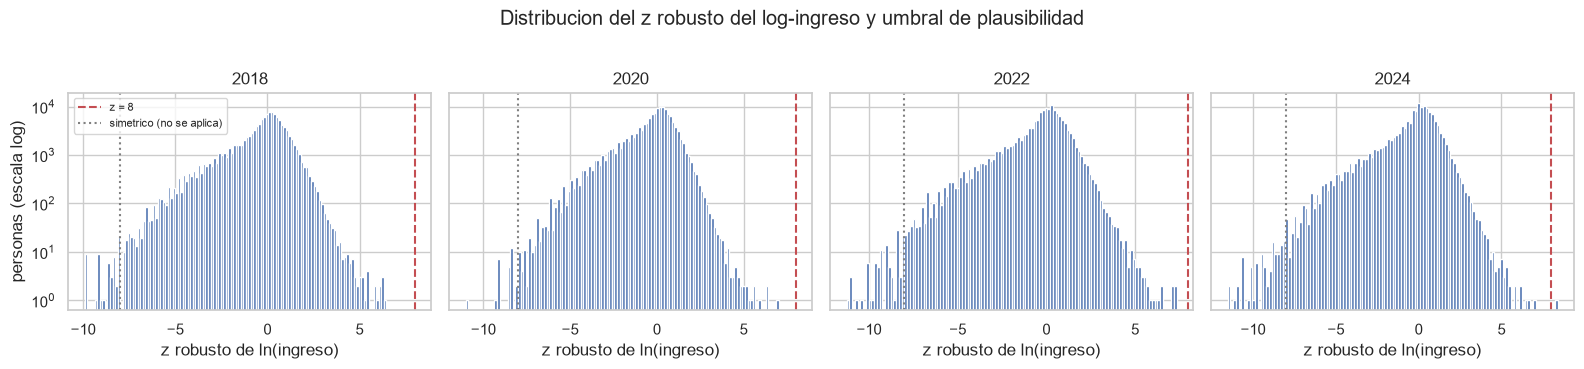

In [7]:
filas, perfiles = [], []
for anio in ANIOS:
    d = datos_completos[anio]
    z, mediana, escala = z_robusto_log(d[TARGET])
    d["z_robusto_log"] = z
    d["excluido_plausibilidad"] = z > UMBRAL_Z_PLAUSIBILIDAD
    ordenado = np.sort(d[TARGET].to_numpy())[::-1]
    filas.append({
        "anio": anio, "personas": len(d), "mediana_ingreso": np.exp(mediana), "escala_robusta_log": escala,
        "umbral_pesos": np.exp(mediana + UMBRAL_Z_PLAUSIBILIDAD * escala),
        "excluidos": int(d.excluido_plausibilidad.sum()), "z_maximo": float(z.max()), "z_minimo": float(z.min()),
        "z_menor_a_menos_umbral_no_excluidos": int((z < -UMBRAL_Z_PLAUSIBILIDAD).sum()),
        "ingreso_maximo": ordenado[0], "segundo_ingreso": ordenado[1], "razon_maximo_segundo": ordenado[0] / ordenado[1],
    })
    for _, r in d.loc[d.excluido_plausibilidad].iterrows():
        perfiles.append({
            "anio": anio, "ingreso_trimestral": r[TARGET], "z_robusto_log": r.z_robusto_log,
            "ingreso_por_hora_aprox": r[TARGET] / (r.horas_trabajos_total * 13) if r.horas_trabajos_total > 0 else np.nan,
            "edad": r.edad, "sexo": r.sexo_desc, "nivel_educativo": r.nivel_educativo, "subordinacion": r.subor_grupo,
            "tam_empresa": r.tam_emp_grupo, "horas_semanales": r.horas_trabajos_total, "ocupacion": r.sinco_division,
            "sector": r.scian_sector, "region": r.region_banxico, "localidad": r.tam_loc_grupo,
            "estrato_hogar": r.est_socio_grupo,
        })
plausibilidad = pd.DataFrame(filas)
perfil_excluidos = pd.DataFrame(perfiles)
display(plausibilidad)
display(perfil_excluidos)

fig, ejes = plt.subplots(1, len(ANIOS), figsize=(16, 3.6), sharey=True)
for ax, anio in zip(ejes, ANIOS):
    z = datos_completos[anio].z_robusto_log
    ax.hist(z, bins=120, color="#4c72b0")
    ax.axvline(UMBRAL_Z_PLAUSIBILIDAD, color="#c44e52", linestyle="--", label=f"z = {UMBRAL_Z_PLAUSIBILIDAD:g}")
    ax.axvline(-UMBRAL_Z_PLAUSIBILIDAD, color="0.5", linestyle=":", label="simetrico (no se aplica)")
    ax.set_yscale("log")
    ax.set_title(f"{anio}")
    ax.set_xlabel("z robusto de ln(ingreso)")
ejes[0].set_ylabel("personas (escala log)")
ejes[0].legend(fontsize=8)
fig.suptitle("Distribucion del z robusto del log-ingreso y umbral de plausibilidad", y=1.02)
fig.tight_layout()
mostrar_figura(fig, "plausibilidad_z_robusto")

### Influencia del registro excluido

Se compara la especificación base del notebook 14 (M0) con y sin el registro, en escala logarítmica y en nivel nominal. La **distancia de Cook** mide cuánto cambian todas las predicciones al omitir la observación $i$:

$$D_i = \frac{\hat u_i^2}{k\, s^2}\,\frac{h_{ii}}{(1-h_{ii})^2},$$

con $h_{ii}$ el elemento diagonal de la matriz sombrero $H = X(X'X)^{-1}X'$ (apalancamiento), $k$ el número de parámetros y $s^2$ la varianza residual. Un criterio convencional de alerta es $D_i > 4/n$.

In [8]:
ESPECIFICACION_M0 = ["edad", "n_trabajos", "horas_trabajos_total", "sexo_desc", "hablaind_desc", "segsoc_desc",
                     "subor_principal_desc", "contrato_principal_desc", "tam_loc_grupo", "nivel_educativo",
                     "region_banxico"]


def influencia(X, y):
    ajuste = sm.OLS(y, X).fit(method="qr")
    Q, _ = np.linalg.qr(X.to_numpy(dtype=float))
    h = np.einsum("ij,ij->i", Q, Q)
    s2 = ajuste.ssr / ajuste.df_resid
    cook = ajuste.resid.to_numpy() ** 2 / (X.shape[1] * s2) * h / (1 - h) ** 2
    return ajuste, h, cook


filas = []
for anio in ANIOS:
    d = datos_completos[anio]
    if not d.excluido_plausibilidad.any():
        continue
    X, _, _ = construir_matriz(d, ESPECIFICACION_M0)
    caso = np.flatnonzero(d.excluido_plausibilidad.to_numpy())
    for escala, objetivo in [("log1p nominal", LOG_TARGET), ("nivel nominal", TARGET)]:
        y = d[objetivo].astype(float)
        con, h, cook = influencia(X, y)
        sin = sm.OLS(y.drop(index=d.index[caso]), X.drop(index=d.index[caso])).fit(method="qr")
        cambio = (sin.params - con.params).abs().drop("const")
        filas.append({
            "anio": anio, "escala": escala, "r2_con_caso": con.rsquared, "r2_sin_caso": sin.rsquared,
            "cook_caso": float(cook[caso].max()), "umbral_4_n": 4 / len(d),
            "rango_cook_caso": int((cook > cook[caso].max()).sum() + 1),
            "apalancamiento_caso": float(h[caso].max()), "apalancamiento_medio": float(h.mean()),
            "maximo_cambio_coeficiente": float(cambio.max()), "termino_mas_afectado": cambio.idxmax(),
        })
influencia_exclusion = pd.DataFrame(filas)
display(influencia_exclusion)

datos = {anio: datos_completos[anio].loc[~datos_completos[anio].excluido_plausibilidad].reset_index(drop=True)
         for anio in ANIOS}
display(pd.DataFrame([{"anio": a, "personas_analisis": len(datos[a]), "hogares": datos[a].id_hogar.nunique()}
                      for a in ANIOS]))

,anio,escala,r2_con_caso,r2_sin_caso,cook_caso,umbral_4_n,rango_cook_caso,apalancamiento_caso,apalancamiento_medio,maximo_cambio_coeficiente,termino_mas_afectado
0,2024,log1p nominal,0.442070,0.442130,0.000270,0.000028,329,0.000138,0.00017,0.000283,nivel_educativo[Licenciatura/profesional]
1,2024,nivel nominal,0.070438,0.135676,0.431765,0.000028,1,0.000138,0.00017,778.781591,nivel_educativo[Licenciatura/profesional]


,anio,personas_analisis,hogares
0,2018,120054,67807
1,2020,139394,79365
2,2022,141514,80217
3,2024,141578,80871


## 4. Exploración de la forma funcional

El modelo base trata edad, horas y número de trabajos como lineales en $\ln(1+y)$. La teoría del capital humano predice otra cosa: en la ecuación de Mincer (1974)

$$\ln w_i = \beta_0 + \beta_1 S_i + \beta_2 X_i + \beta_3 X_i^2 + u_i,\qquad \beta_2 > 0,\ \beta_3 < 0,$$

el ingreso crece con la experiencia a tasa decreciente (perfil cóncavo de ciclo de vida). Con horas, el ingreso trimestral debería crecer casi proporcionalmente hasta la jornada completa y aplanarse después, porque las horas extra se concentran en ocupaciones de menor remuneración por hora.

La *pairplot* muestra relaciones bivariadas en una muestra aleatoria del año de diagnóstico, coloreada por subordinación. Los suavizados LOWESS (regresión local ponderada; Cleveland, 1979) estiman $\mathbb E[\ln(1+y)\mid v]$ para cada variable continua $v$ en **los cuatro años**, para comprobar que la forma no es particular de un corte. Se agrega además el estimador de máxima verosimilitud del parámetro de Box–Cox,

$$y^{(\lambda)} = \frac{y^{\lambda} - 1}{\lambda}\ (\lambda \neq 0),\qquad y^{(0)} = \ln y,$$

como referencia marginal de si la escala logarítmica es adecuada para el target ($\hat\lambda \approx 0$ respalda el logaritmo). Es una referencia sin covariables, no una prueba condicional.

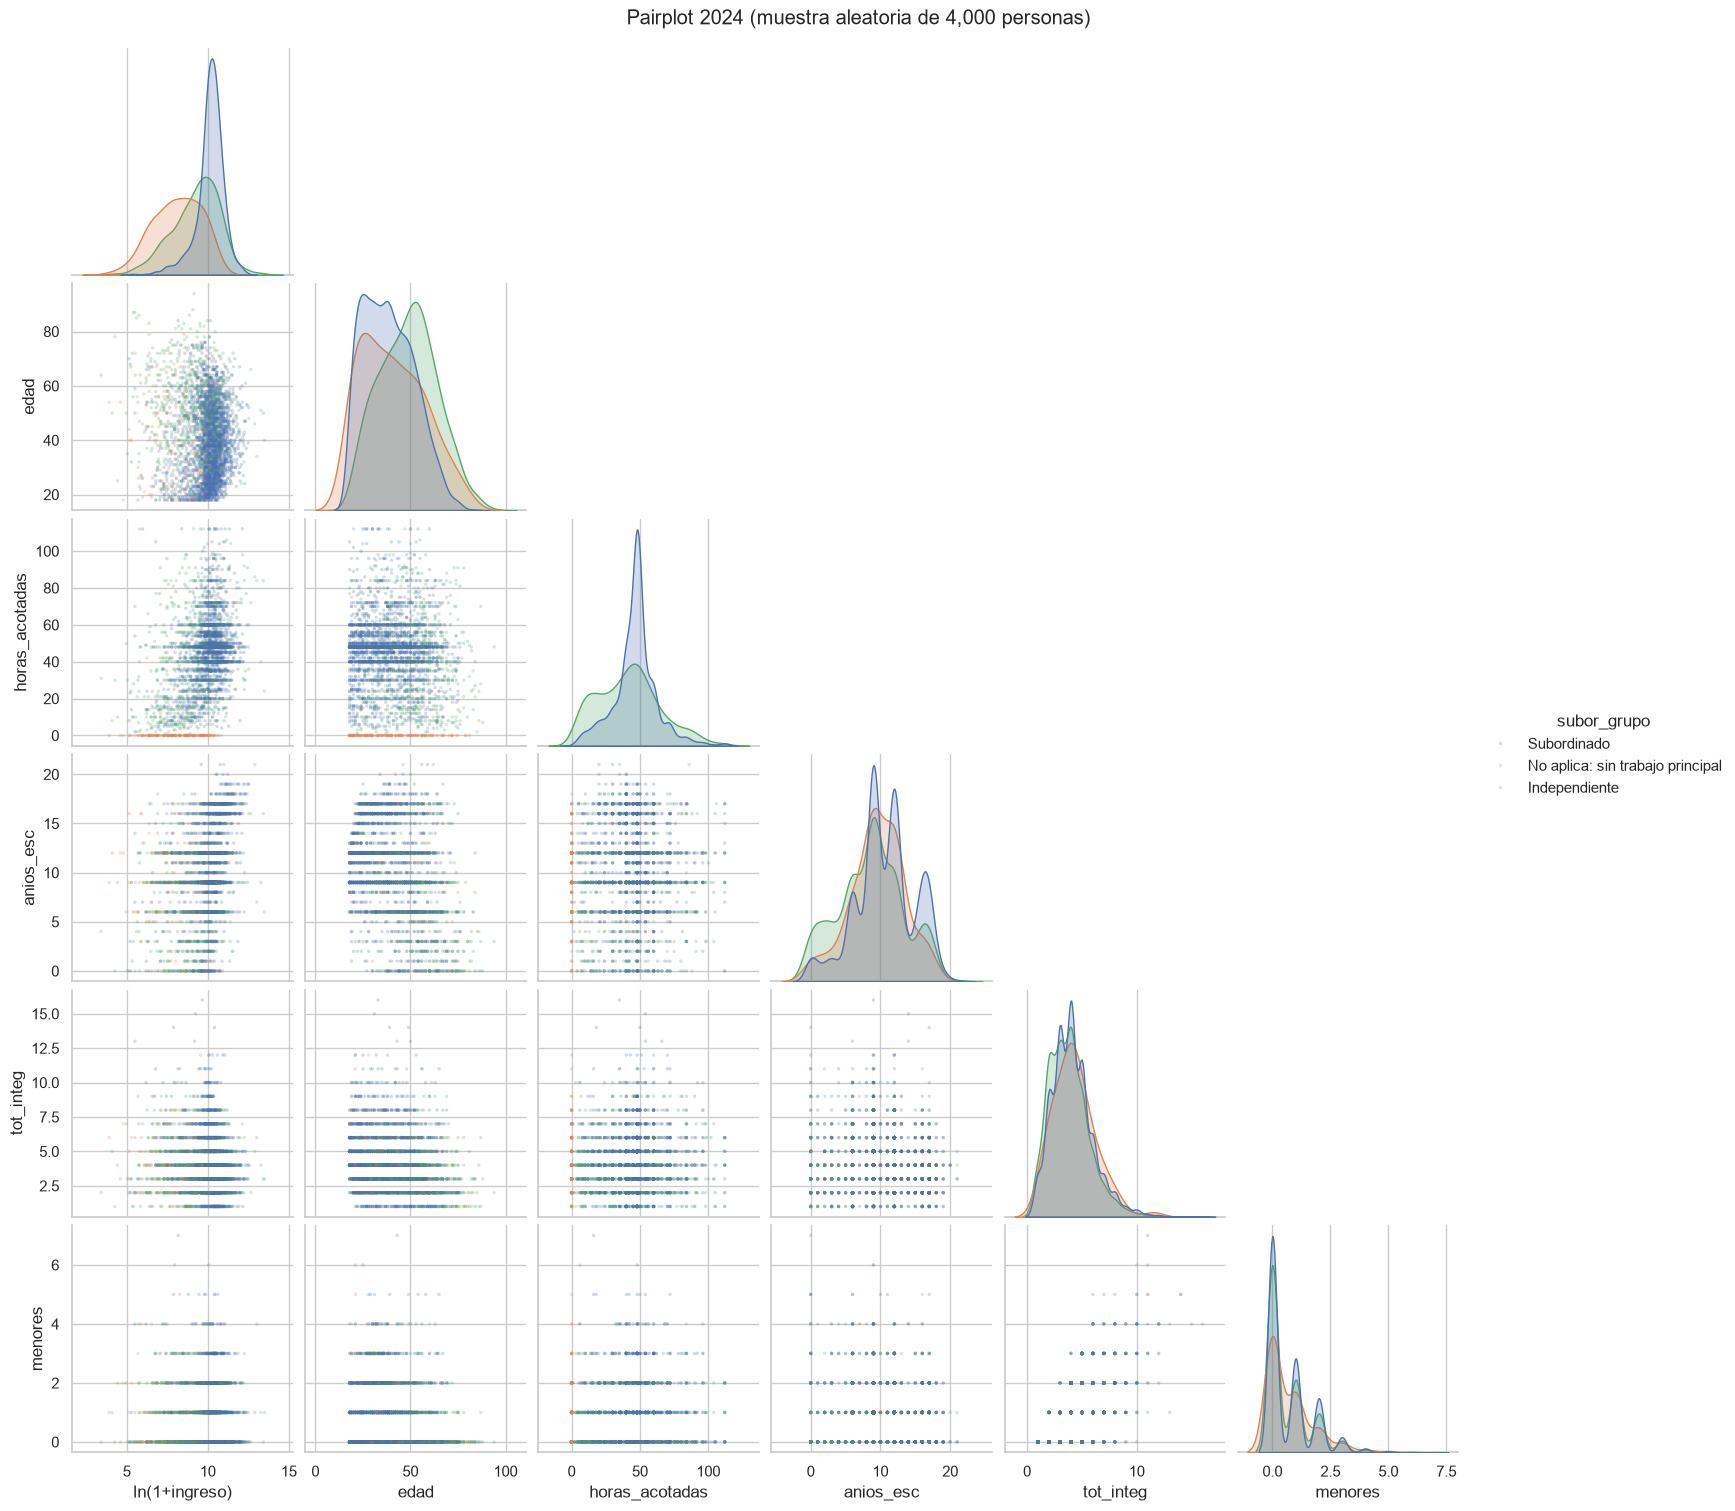

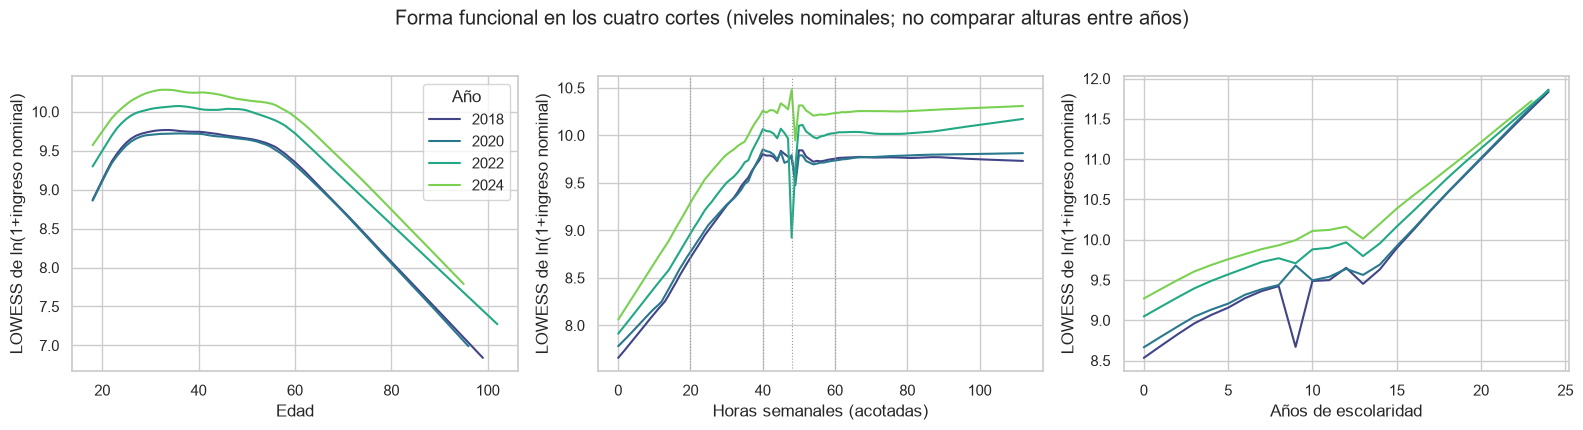

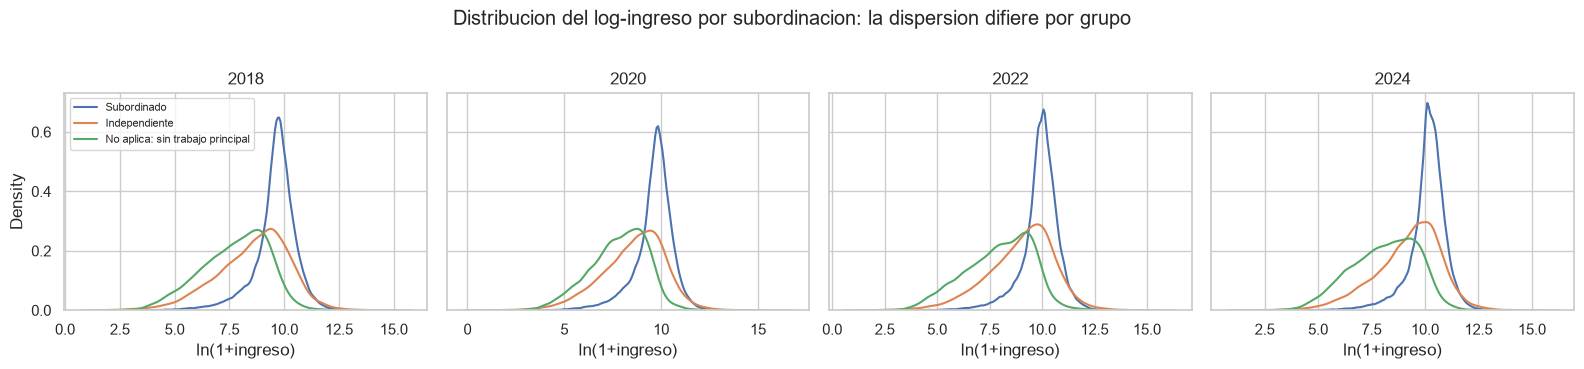

,anio,lambda_box_cox_mle,horas_mayores_tope,horas_mayores_168
0,2018,0.249802,521,20
1,2020,0.247115,595,25
2,2022,0.262452,612,26
3,2024,0.297253,433,16


In [9]:
d = datos[ANIO_DIAGNOSTICO]
variables_pair = [LOG_TARGET, "edad", "horas_acotadas", "anios_esc", "tot_integ", "menores"]
muestra = d.sample(n=min(TAMANO_MUESTRA_PAIRPLOT, len(d)), random_state=SEMILLA)
grid = sns.pairplot(
    muestra[variables_pair + ["subor_grupo"]].rename(columns={LOG_TARGET: "ln(1+ingreso)"}),
    hue="subor_grupo", corner=True, diag_kind="kde", plot_kws={"s": 6, "alpha": 0.25, "linewidth": 0},
    diag_kws={"common_norm": False},
)
grid.figure.suptitle(f"Pairplot {ANIO_DIAGNOSTICO} (muestra aleatoria de {len(muestra):,} personas)", y=1.01)
mostrar_figura(grid.figure, "pairplot_variables_continuas")

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.2))
paleta = dict(zip(ANIOS, sns.color_palette("viridis", len(ANIOS))))
for ax, variable, nombre in zip(ejes, ["edad", "horas_acotadas", "anios_esc"],
                                ["Edad", "Horas semanales (acotadas)", "Años de escolaridad"]):
    for anio in ANIOS:
        s = datos[anio].sample(n=min(TAMANO_MUESTRA_LOWESS, len(datos[anio])), random_state=SEMILLA)
        rango = s[variable].max() - s[variable].min()
        with warnings.catch_warnings():
            # LOWESS divide por pesos nulos en valores discretos repetidos; esos puntos se omiten del trazo
            warnings.simplefilter("ignore", RuntimeWarning)
            curva = lowess(s[LOG_TARGET], s[variable], frac=0.2, delta=0.01 * rango, return_sorted=True)
        curva = curva[np.isfinite(curva[:, 1])]
        ax.plot(curva[:, 0], curva[:, 1], color=paleta[anio], label=str(anio))
    if variable == "horas_acotadas":
        for nudo in NUDOS_HORAS:
            ax.axvline(nudo, color="0.6", linestyle=":", linewidth=0.8)
    ax.set_xlabel(nombre)
    ax.set_ylabel("LOWESS de ln(1+ingreso nominal)")
ejes[0].legend(title="Año")
fig.suptitle("Forma funcional en los cuatro cortes (niveles nominales; no comparar alturas entre años)", y=1.02)
fig.tight_layout()
mostrar_figura(fig, "lowess_forma_funcional")

fig, ejes = plt.subplots(1, len(ANIOS), figsize=(16, 3.6), sharey=True)
for ax, anio in zip(ejes, ANIOS):
    for grupo, color in zip(["Subordinado", "Independiente", NO_APLICA], ["#4c72b0", "#dd8452", "#55a868"]):
        valores = datos[anio].loc[datos[anio].subor_grupo.eq(grupo), LOG_TARGET]
        sns.kdeplot(valores, ax=ax, label=grupo, color=color, common_norm=False)
    ax.set_title(str(anio))
    ax.set_xlabel("ln(1+ingreso)")
ejes[0].legend(fontsize=8)
fig.suptitle("Distribucion del log-ingreso por subordinacion: la dispersion difiere por grupo", y=1.02)
fig.tight_layout()
mostrar_figura(fig, "densidad_log_ingreso_subordinacion")

box_cox = pd.DataFrame([{
    "anio": anio,
    "lambda_box_cox_mle": boxcox_normmax(
        datos[anio][TARGET].sample(n=min(50000, len(datos[anio])), random_state=SEMILLA).to_numpy(), method="mle"),
    "horas_mayores_tope": int(datos[anio].horas_trabajos_total.gt(HORAS_MAXIMAS_SEMANALES).sum()),
    "horas_mayores_168": int(datos[anio].horas_trabajos_total.gt(168).sum()),
} for anio in ANIOS])
display(box_cox)

**Transformaciones adoptadas (fijadas antes de estimar).**

* **Edad:** polinomio cuadrático centrado, $e_i = (\text{edad}_i - 40)/10$ y $e_i^2$. El centrado reduce la colinealidad entre $e$ y $e^2$ y hace interpretable el término lineal como pendiente a los 40 años (por década).
* **Horas:** *spline* lineal con nudos $\kappa \in \{20, 40, 48, 60\}$ sobre horas acotadas a 112:
  $$f(h) = \gamma_0 \tfrac{h}{10} + \sum_{k} \gamma_k \tfrac{(h-\kappa_k)_+}{10},\qquad (a)_+ = \max(a,0).$$
  La pendiente entre nudos es $\gamma_0 + \sum_{\kappa_k < h}\gamma_k$ por cada 10 horas. Los nudos tienen justificación institucional: 20 h (tiempo parcial), 40 h, 48 h (jornada máxima semanal diurna, art. 123 constitucional y art. 61 de la Ley Federal del Trabajo) y 60 h (horas extra prolongadas). Acotar a 112 h (16 h × 7 días) evita el apalancamiento de valores físicamente implausibles sin excluir personas.
* **Número de trabajos:** indicador de dos o más trabajos. Con el indicador de "sin trabajo principal" ya en el modelo, reproduce exactamente la información de `n_trabajos` ∈ {0, 1, 2}, de modo que M0 queda anidado en M1.
* **Escolaridad fina y experiencia potencial:** `grado_relativo` (sección 2) y, como alternativa de Mincer, experiencia potencial $X_i$ con su cuadrado en lugar de la edad. Edad, años de escolaridad y experiencia no pueden entrar juntas linealmente, porque $X = \text{edad} - S - 6$ (colinealidad exacta).
* **Target:** se mantiene $\ln(1+y)$ nominal. La $\hat\lambda$ marginal es solo una primera referencia; la justificación formal de la escala, con el perfil de Box–Cox condicional, está en la sección 9.

Otras transformaciones que sugiere la exploración quedan como candidatas en la síntesis (sección 14).

## 5. Criterios de comparación y especificaciones

**Ajuste dentro de muestra.** Con $SSR = \sum_i \hat u_i^2$ y $SST = \sum_i (y_i - \bar y)^2$:

$$R^2 = 1 - \frac{SSR}{SST}, \qquad \bar R^2 = 1 - (1-R^2)\frac{n-1}{n-k},$$

$$\mathrm{AIC} = 2k - 2\ln\hat L, \qquad \mathrm{BIC} = k\ln n - 2\ln\hat L, \qquad \ln\hat L = -\frac n2\Big[\ln(2\pi) + \ln\frac{SSR}{n} + 1\Big],$$

donde $k$ incluye el intercepto. Estos valores son los que reporta `statsmodels` en su `summary()`. El $R^2$ nunca disminuye al agregar regresores; $\bar R^2$, AIC y BIC penalizan la complejidad. Con $n \approx 140{,}000$, el BIC cobra $\ln n \approx 11.9$ por parámetro, de modo que es mucho más exigente que el AIC (que cobra 2).

**Pruebas anidadas.** Para modelos anidados se reporta la prueba $F$ convencional,

$$F = \frac{(SSR_r - SSR_u)/q}{SSR_u/(n-k_u)},$$

que supone homocedasticidad y por ello es solo de referencia. Para bloques de interacciones se usa el Wald con covarianza agrupada por hogar, $W = (R\hat\beta)'(R\hat V_{cl}R')^{-1}(R\hat\beta) \sim \chi^2_q$.

**Validación cruzada agrupada por hogar.** Se forman $K=5$ particiones de **hogares** $\mathcal H_1,\dots,\mathcal H_K$. Para cada $k$ se estima con los hogares fuera de $\mathcal H_k$ y se predice a las personas de $\mathcal H_k$:

$$R^2_{CV} = 1 - \frac{\sum_k \sum_{i \in \mathcal H_k} \big(y_i - \hat y_i^{(-k)}\big)^2}{\sum_k \sum_{i \in \mathcal H_k} \big(y_i - \bar y^{(-k)}\big)^2}.$$

Agrupar por hogar evita la fuga de información: los miembros de un hogar comparten choques no observados (lugar, red, negocio familiar). Si unos quedan en entrenamiento y otros en prueba, el error de prueba subestima el error al predecir **hogares nuevos**. Todo el preprocesamiento (categorías, referencias, nudos, centrado) se fija antes y no se aprende de los datos de prueba; los factores de Duan se estiman solo con el entrenamiento de cada pliegue. Las mismas particiones se usan para todas las especificaciones de un año, de modo que las diferencias de $R^2_{CV}$ son comparaciones pareadas. La validación cruzada **no** decide significancia: mide capacidad de generalización.

**Especificaciones (escalera anidada).**

| Modelo | Agrega a la anterior |
| --- | --- |
| M0_base_nb14 | Especificación `regional_ampliado` del notebook 14 |
| M1_forma_funcional | Edad cuadrática centrada, *spline* de horas, indicador de dos o más trabajos |
| M2_escolaridad_fina | Grados aprobados respecto a la conclusión del nivel (`grado_relativo`) |
| M3_variables_excluidas | Parentesco, estado conyugal, etnia, alfabetismo, tamaño de empresa, estrato socioeconómico y contexto del hogar |
| M4_ocupacion_sector | División ocupacional (SINCO) y sector (SCIAN) del trabajo principal |
| M4_mincer | M4 con experiencia potencial cuadrática en lugar de edad (no anidado; alternativa) |

**Advertencia sobre M4.** Ocupación y sector son en parte **resultado** de la escolaridad: una persona con licenciatura accede a ocupaciones profesionales. Controlar por ellos absorbe parte de la prima educativa (un *mal control* en el sentido de Angrist y Pischke, 2009). M4 mejora la predicción, pero para leer la asociación total de la escolaridad la referencia es M3. La sección 6 compara ambas.

In [10]:
ESPECIFICACIONES = {}
ESPECIFICACIONES["M0_base_nb14"] = ESPECIFICACION_M0
ESPECIFICACIONES["M1_forma_funcional"] = [
    "edad_poly", "dos_o_mas_trabajos", "horas_spline", "sexo_desc", "hablaind_desc", "segsoc_desc",
    "subor_principal_desc", "contrato_principal_desc", "tam_loc_grupo", "nivel_educativo", "region_banxico",
]
ESPECIFICACIONES["M2_escolaridad_fina"] = ESPECIFICACIONES["M1_forma_funcional"] + ["grado_relativo"]
ESPECIFICACIONES["M3_variables_excluidas"] = ESPECIFICACIONES["M2_escolaridad_fina"] + [
    "parentesco_grupo", "edo_conyugal_grupo", "etnia_grupo", "alfabetismo", "tam_emp_grupo",
    "est_socio_grupo", "hogar",
]
ESPECIFICACIONES["M4_ocupacion_sector"] = ESPECIFICACIONES["M3_variables_excluidas"] + ["sinco_division", "scian_sector"]
ESPECIFICACIONES["M4_mincer"] = [("exp_poly" if t == "edad_poly" else t) for t in ESPECIFICACIONES["M4_ocupacion_sector"]]
ESCALERA = list(ESPECIFICACIONES)
ANIDADO_EN = {"M1_forma_funcional": "M0_base_nb14", "M2_escolaridad_fina": "M1_forma_funcional",
              "M3_variables_excluidas": "M2_escolaridad_fina", "M4_ocupacion_sector": "M3_variables_excluidas"}

display(pd.DataFrame([{"especificacion": k, "terminos": len(v), "detalle": " + ".join(v)}
                      for k, v in ESPECIFICACIONES.items()]))
folds_por_anio = {anio: particiones(datos[anio]) for anio in ANIOS}
grupos_duan_por_anio = {anio: (datos[anio].subor_grupo + " | " + datos[anio].tam_loc_grupo).to_numpy()
                        for anio in ANIOS}
display(pd.DataFrame([{"anio": a, "pliegue": i + 1, "personas_prueba": len(te),
                       "hogares_prueba": datos[a].id_hogar.iloc[te].nunique()}
                      for a in ANIOS for i, (_, te) in enumerate(folds_por_anio[a])])
        .pivot(index="pliegue", columns="anio", values="personas_prueba"))

,especificacion,terminos,detalle
0,M0_base_nb14,11,edad + n_trabajos + horas_trabajos_total + sex...
1,M1_forma_funcional,11,edad_poly + dos_o_mas_trabajos + horas_spline ...
2,M2_escolaridad_fina,12,edad_poly + dos_o_mas_trabajos + horas_spline ...
3,M3_variables_excluidas,19,edad_poly + dos_o_mas_trabajos + horas_spline ...
4,M4_ocupacion_sector,21,edad_poly + dos_o_mas_trabajos + horas_spline ...
5,M4_mincer,21,exp_poly + dos_o_mas_trabajos + horas_spline +...


anio,2018,2020,2022,2024
pliegue,,,,
1,24081,27858,28160,28249
2,24034,27867,28292,28385
3,23996,27696,28349,28303
4,23902,27973,28305,28391
5,24041,28000,28408,28250


## 6. Escalera de especificaciones

Para cada año y especificación se reportan $R^2$, $\bar R^2$, AIC, BIC, la prueba $F$ anidada frente al peldaño anterior y el $R^2_{CV}$ con su desviación estándar entre pliegues. Para el año de diagnóstico se muestran los `summary()` completos de `statsmodels` de M0 y M4, con errores agrupados por hogar.

In [11]:
filas = []
cv_guardado = {}
coeficientes_m3_m4 = []
eliminadas_registro = []
modelos_m4 = {}
for anio in ANIOS:
    d = datos[anio]
    ajustes = {}
    for nombre in ESCALERA:
        inicio = time.time()
        necesita_cluster = nombre in ("M3_variables_excluidas", "M4_ocupacion_sector") or (
            anio == ANIO_DIAGNOSTICO and nombre == "M0_base_nb14")
        aj = ajustar_ols(d, ESPECIFICACIONES[nombre], cluster=necesita_cluster)
        cv = validacion_cruzada(aj["X"], aj["y"], folds_por_anio[anio], grupos_duan=grupos_duan_por_anio[anio])
        fila = {"anio": anio, "especificacion": nombre, **metricas_ajuste(aj["ajuste"]),
                "r2_cv": cv["r2_cv"], "rmse_cv": cv["rmse_cv"], "r2_cv_sd_pliegues": cv["r2_cv_sd_pliegues"],
                "columnas_eliminadas": len(aj["eliminadas"])}
        if nombre in ANIDADO_EN:
            f, p, gl = aj["ajuste"].compare_f_test(ajustes[ANIDADO_EN[nombre]])
            fila.update({"f_anidada": f, "gl_f": gl, "p_f_anidada": p})
        filas.append({**fila, "segundos": time.time() - inicio})
        cv_guardado[(anio, nombre)] = {k: cv[k] for k in ("pred", "media_train", "duan", "duan_grupo")}
        eliminadas_registro.append(aj["eliminadas"].assign(anio=anio, especificacion=nombre))
        ajustes[nombre] = aj["ajuste"]
        if nombre in ("M3_variables_excluidas", "M4_ocupacion_sector"):
            tabla = tabla_coeficientes(aj["cluster"], aj["X"].columns)
            coeficientes_m3_m4.append(tabla.loc[tabla.termino.str.startswith(("nivel_educativo[", "grado_relativo"))
                                                & ~tabla.termino.str.contains(":")]
                                      .assign(anio=anio, especificacion=nombre))
        if nombre == "M4_ocupacion_sector":
            modelos_m4[anio] = {"X": aj["X"], "y": aj["y"], "cluster": aj["cluster"]}
        if anio == ANIO_DIAGNOSTICO and nombre in ("M0_base_nb14", "M4_ocupacion_sector"):
            print(f"\n{nombre} | {anio} | errores estandar agrupados por hogar")
            display(aj["cluster"].summary())
    del ajustes
escalera = pd.DataFrame(filas)
escalera["delta_r2_cv_vs_m0"] = escalera.r2_cv - escalera.groupby("anio").r2_cv.transform("first")
escalera["delta_bic_vs_m0"] = escalera.bic - escalera.groupby("anio").bic.transform("first")
display(escalera[["anio", "especificacion", "k", "r2", "r2_ajustado", "aic", "bic", "f_anidada", "p_f_anidada",
                  "r2_cv", "r2_cv_sd_pliegues", "delta_r2_cv_vs_m0", "delta_bic_vs_m0", "columnas_eliminadas"]])
columnas_eliminadas = pd.concat(eliminadas_registro, ignore_index=True)
display(columnas_eliminadas.groupby(["especificacion", "motivo", "termino"]).size().rename("anios_x_columnas").reset_index())


M0_base_nb14 | 2024 | errores estandar agrupados por hogar


<class 'statsmodels.iolib.summary.Summary'>
"""
                                        OLS Regression Results                                       
=====================================================================================================
Dep. Variable:     log1p_ingreso_persona_laboral_negocio_tri   R-squared:                       0.442
Model:                                                   OLS   Adj. R-squared:                  0.442
Method:                                        Least Squares   F-statistic:                     3468.
Date:                                       Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                                               19:00:59   Log-Likelihood:            -1.8600e+05
No. Observations:                                     141578   AIC:                         3.721e+05
Df Residuals:                                         141554   BIC:                         3.723e+05
Df Model:                                                 23                                         
Covariance Type:                                     cluster                                         
==========================================================================================================================================
                                                                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------------------
const                                                                      9.8322      0.056    174.228      0.000       9.722       9.943
edad                                                                       0.0016      0.000      7.234      0.000       0.001       0.002
n_trabajos                                                                -0.0206      0.009     -2.172      0.030      -0.039      -0.002
horas_trabajos_total                                                       0.0171      0.000     90.730      0.000       0.017       0.017
sexo_desc[Mujer]                                                          -0.3644      0.005    -71.162      0.000      -0.374      -0.354
hablaind_desc[Sí]                                                         -0.2675      0.012    -22.043      0.000      -0.291      -0.244
segsoc_desc[Sí]                                                            0.2798      0.007     42.181      0.000       0.267       0.293
subor_principal_desc[No aplica: sin trabajo principal reportado]          -0.5297      0.025    -20.998      0.000      -0.579      -0.480
subor_principal_desc[Sí]                                                  -0.7623      0.054    -14.207      0.000      -0.867      -0.657
contrato_principal_desc[No aplica: sin contrato principal documentado]    -1.1394      0.053    -21.319      0.000      -1.244      -1.035
contrato_principal_desc[Sí]                                                0.3110      0.006     54.908      0.000       0.300       0.322
tam_loc_grupo[Rural (<2,500)]                                             -0.2242      0.006    -35.016      0.000      -0.237      -0.212
tam_loc_grupo[Semiurbana (2,500-14,999)]                                  -0.1230      0.008    -14.531      0.000      -0.140      -0.106
tam_loc_grupo[Urbana media (15,000-99,999)]                               -0.0614      0.008     -7.673      0.000      -0.077      -0.046
nivel_educativo[Licenciatura/profesional]                                  0.3904      0.007     53.336      0.000       0.376       0.405
nivel_educativo[Media superior]                                            0.0619      0.006      9.607      0.000       0.049       0.075
nivel_educativo[Normal]                                                    0.3894      0.050      7.791      0.000       0.291       0.487
nivel_educativo[Posgrado]                         


M4_ocupacion_sector | 2024 | errores estandar agrupados por hogar


<class 'statsmodels.iolib.summary.Summary'>
"""
                                        OLS Regression Results                                       
=====================================================================================================
Dep. Variable:     log1p_ingreso_persona_laboral_negocio_tri   R-squared:                       0.529
Model:                                                   OLS   Adj. R-squared:                  0.528
Method:                                        Least Squares   F-statistic:                     1573.
Date:                                       Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                                               19:01:13   Log-Likelihood:            -1.7408e+05
No. Observations:                                     141578   AIC:                         3.483e+05
Df Residuals:                                         141506   BIC:                         3.490e+05
Df Model:                                                 71                                         
Covariance Type:                                     cluster                                         
==========================================================================================================================================
                                                                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------------------
const                                                                      8.9644      0.063    142.058      0.000       8.841       9.088
edad_c                                                                     0.0195      0.003      7.384      0.000       0.014       0.025
edad_c2                                                                   -0.0468      0.001    -35.218      0.000      -0.049      -0.044
dos_o_mas_trabajos                                                         0.0339      0.009      3.759      0.000       0.016       0.052
horas_10                                                                   0.6402      0.015     41.387      0.000       0.610       0.671
horas_s20                                                                 -0.4068      0.020    -20.785      0.000      -0.445      -0.368
horas_s40                                                                 -0.1718      0.012    -13.875      0.000      -0.196      -0.148
horas_s48                                                                  0.0221      0.011      1.951      0.051      -0.000       0.044
horas_s60                                                                 -0.0526      0.009     -6.062      0.000      -0.070      -0.036
sexo_desc[Mujer]                                                          -0.2892      0.006    -49.697      0.000      -0.301      -0.278
hablaind_desc[Sí]                                                         -0.1869      0.012    -15.569      0.000      -0.210      -0.163
segsoc_desc[Sí]                                                            0.1694      0.006     26.855      0.000       0.157       0.182
subor_principal_desc[No aplica: sin trabajo principal reportado]           0.2593      0.035      7.365      0.000       0.190       0.328
subor_principal_desc[Sí]                                                  -0.8776      0.055    -16.017      0.000      -0.985      -0.770
contrato_principal_desc[No aplica: sin contrato principal documentado]    -0.9265      0.054    -17.025      0.000      -1.033      -0.820
contrato_principal_desc[Sí]                                                0.1374      0.006     22.711      0.000       0.126       0.149
tam_loc_grupo[Rural (<2,500)]                                             -0.0569      0.007     -8.400      0.000      -0.070      -0.044
tam_loc_grupo[Semiurbana (2,500-14,999)]          

,anio,especificacion,k,r2,r2_ajustado,aic,bic,f_anidada,p_f_anidada,r2_cv,r2_cv_sd_pliegues,delta_r2_cv_vs_m0,delta_bic_vs_m0,columnas_eliminadas
0,2018,M0_base_nb14,24,0.446389,0.446283,330495.592548,330728.289274,NaN,NaN,0.446013,0.002338,0.000000,0.000000,0
1,2018,M1_forma_funcional,29,0.493077,0.492959,319928.345986,320209.521197,2210.903135,0.000000e+00,0.492650,0.001796,0.046637,-10518.768077,0
2,2018,M2_escolaridad_fina,30,0.495685,0.495564,319311.060856,319601.931764,620.729985,1.157331e-136,0.495222,0.001686,0.049209,-11126.357510,0
3,2018,M3_variables_excluidas,52,0.512348,0.512141,315321.508435,315825.684675,186.377282,0.000000e+00,0.511719,0.001791,0.065706,-14902.604599,1
4,2018,M4_ocupacion_sector,72,0.535664,0.535389,309479.688237,310177.778415,301.233569,0.000000e+00,0.534936,0.001546,0.088923,-20550.510859,3
5,2018,M4_mincer,72,0.536125,0.535851,309360.313360,310058.403538,NaN,NaN,0.535394,0.001600,0.089381,-20669.885736,3
6,2020,M0_base_nb14,24,0.429098,0.429004,396552.187739,396788.469173,NaN,NaN,0.428809,0.002775,0.000000,0.000000,0
7,2020,M1_forma_funcional,29,0.471467,0.471361,385813.217287,386098.724019,2234.389023,0.000000e+00,0.471160,0.003769,0.042351,-10689.745153,0
8,2020,M2_escolaridad_fina,30,0.473603,0.473494,385250.639059,385545.990851,565.601356,9.027750e-125,0.473295,0.003831,0.044486,-11242.478321,0
9,2020,M3_variables_excluidas,52,0.490178,0.489991,380834.943718,381346.886824,205.914193,0.000000e+00,0.489678,0.003749,0.060869,-15441.582348,1


,especificacion,motivo,termino,anios_x_columnas
0,M3_variables_excluidas,combinacion lineal de columnas previas,tam_emp_grupo,4
1,M4_mincer,combinacion lineal de columnas previas,scian_sector,4
2,M4_mincer,combinacion lineal de columnas previas,sinco_division,4
3,M4_mincer,combinacion lineal de columnas previas,tam_emp_grupo,4
4,M4_ocupacion_sector,combinacion lineal de columnas previas,scian_sector,4
5,M4_ocupacion_sector,combinacion lineal de columnas previas,sinco_division,4
6,M4_ocupacion_sector,combinacion lineal de columnas previas,tam_emp_grupo,4


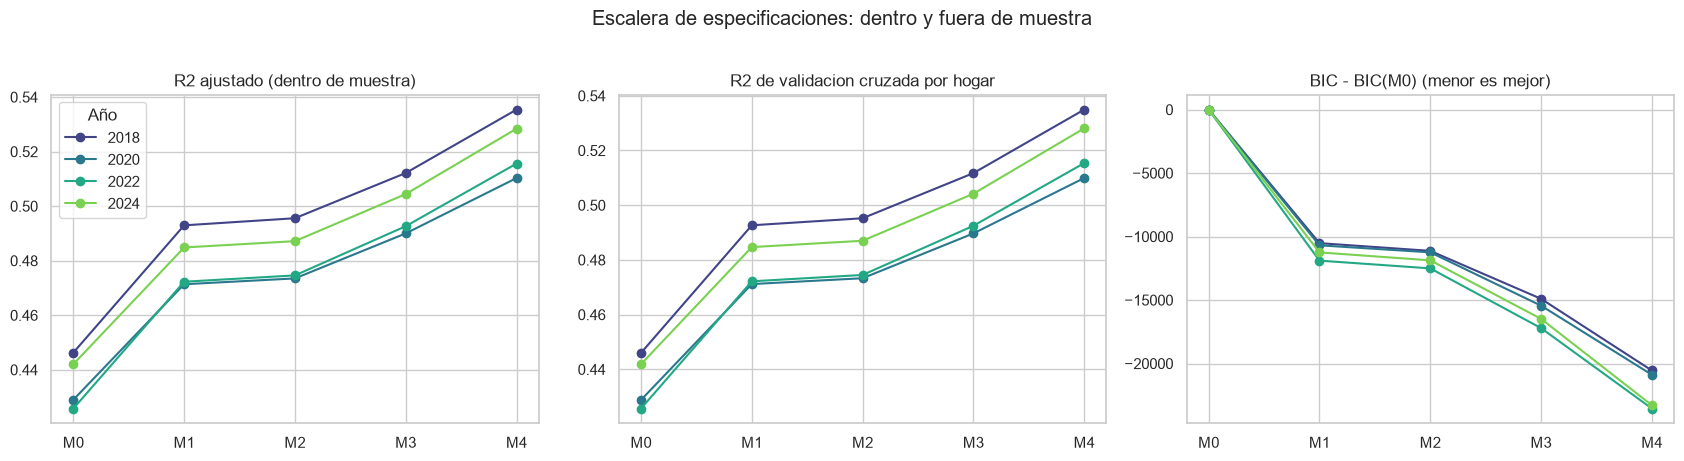

especificacion,termino,anio,M3_variables_excluidas,M4_ocupacion_sector,reduccion_por_ocupacion_sector_pp
0,grado_relativo,2018,5.570449,3.943109,1.627339
1,grado_relativo,2020,5.200156,3.548611,1.651545
2,grado_relativo,2022,5.152817,3.635350,1.517467
3,grado_relativo,2024,4.998012,3.685787,1.312225
4,nivel_educativo[Licenciatura/profesional],2018,64.659902,38.447508,26.212394
5,nivel_educativo[Licenciatura/profesional],2020,56.520062,28.937571,27.582491
6,nivel_educativo[Licenciatura/profesional],2022,52.727670,31.041951,21.685719
7,nivel_educativo[Licenciatura/profesional],2024,43.427346,27.361586,16.065759
8,nivel_educativo[Media superior],2018,14.369923,8.927966,5.441957
9,nivel_educativo[Media superior],2020,12.494819,6.526824,5.967996


In [12]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
orden = [e for e in ESCALERA if e != "M4_mincer"]
for anio in ANIOS:
    sub = escalera.loc[escalera.anio.eq(anio)].set_index("especificacion").loc[orden]
    ejes[0].plot(range(len(orden)), sub.r2_ajustado, marker="o", color=paleta[anio], label=str(anio))
    ejes[1].plot(range(len(orden)), sub.r2_cv, marker="o", color=paleta[anio], label=str(anio))
    ejes[2].plot(range(len(orden)), sub.bic - sub.bic.iloc[0], marker="o", color=paleta[anio], label=str(anio))
for ax, titulo in zip(ejes, ["R2 ajustado (dentro de muestra)", "R2 de validacion cruzada por hogar",
                             "BIC - BIC(M0) (menor es mejor)"]):
    ax.set_xticks(range(len(orden)), [o.split("_")[0] for o in orden])
    ax.set_title(titulo)
ejes[0].legend(title="Año")
fig.suptitle("Escalera de especificaciones: dentro y fuera de muestra", y=1.02)
fig.tight_layout()
mostrar_figura(fig, "escalera_especificaciones")

coeficientes_m3_m4 = pd.concat(coeficientes_m3_m4, ignore_index=True)
prima_educativa = coeficientes_m3_m4.pivot_table(index=["termino", "anio"], columns="especificacion",
                                                 values="efecto_pct").reset_index()
prima_educativa["reduccion_por_ocupacion_sector_pp"] = (prima_educativa["M3_variables_excluidas"]
                                                        - prima_educativa["M4_ocupacion_sector"])
display(prima_educativa)

**Lectura de la tabla de prima educativa.** Cada valor es $100[\exp(\beta)-1]$: la diferencia porcentual en $1+$ingreso frente a Secundaria concluida (o por grado adicional dentro del nivel, en `grado_relativo`), condicionada al resto del modelo. La columna `reduccion_por_ocupacion_sector_pp` mide cuántos puntos porcentuales de la prima de M3 se transfieren a ocupación y sector en M4: es la parte de la asociación educativa que opera **a través** del tipo de trabajo al que se accede. Por eso M3 es la referencia para hablar de la asociación total de la escolaridad y M4 para la predicción.

## 7. Interacciones justificadas por teoría

Una interacción permite que la pendiente de una variable dependa de otra. En

$$\ln(1+y_i) = \beta_0 + \beta_1 x_i + \beta_2 z_i + \beta_3 x_i z_i + \dots + u_i, \qquad \frac{\partial\,\mathbb E[\ln(1+y)\mid x,z]}{\partial x} = \beta_1 + \beta_3 z,$$

el efecto de $x$ ya no es un número sino una función de $z$. Agregar todas las interacciones posibles multiplicaría los parámetros sin respaldo teórico y sobreajustaría. Por eso se definen **bloques** con una hipótesis cada uno:

| Bloque | Términos | Hipótesis |
| --- | --- | --- |
| I1_genero_ciclo_vida | sexo × edad (cuadrática), sexo × estado conyugal, sexo × menores | La brecha de género se amplía con la edad y con la maternidad o el matrimonio (Goldin, 2014; Blau y Kahn, 2017) |
| I2_educacion_edad | nivel educativo × edad (cuadrática) | Los perfiles de ingreso por edad son más empinados con más escolaridad (Heckman, Lochner y Todd, 2006) |
| I3a_estrato_territorial | región × tamaño de localidad | La penalización rural no es igual en el Norte que en el Sur |
| I3b_educacion_territorio | nivel educativo × tamaño de localidad, nivel educativo × región | La prima educativa es mayor en mercados urbanos densos (Glaeser y Maré, 2001) |
| I3c_genero_territorio | sexo × región, sexo × tamaño de localidad | La brecha de género varía por estructura productiva regional |
| I3d_ocupacion_territorio | división ocupacional × tamaño de localidad | Una misma ocupación se paga distinto en mercados rurales y urbanos |
| I4_laboral | subordinación × seguridad social, subordinación × *spline* de horas | La relación horas–ingreso y la asociación de la seguridad social difieren entre asalariados e independientes |

**Procedimiento.** Cada bloque se agrega **por separado** a M4 en cada año y se registran $\Delta\bar R^2$, $\Delta$AIC, $\Delta$BIC, $\Delta R^2_{CV}$ y el Wald agrupado por hogar del bloque. **Regla de decisión declarada de antemano:** un bloque entra a la especificación final M5 si en **los cuatro años** cumple $\Delta\mathrm{BIC} < 0$ y $\Delta R^2_{CV} > 0$. Exigir los cuatro años evita que la selección de un corte se traslade a otro (regla 10 de `AGENTS.md`) y combina un criterio consistente (BIC) con uno predictivo. Por simplicidad, la regla no corrige por comparaciones múltiples; el Wald se reporta como evidencia complementaria.

,anio,bloque,parametros_bloque,delta_r2,delta_r2_ajustado,delta_aic,delta_bic,delta_r2_cv,wald_cluster,gl_wald,p_wald,cumple_regla
0,2018,I1_genero_ciclo_vida,7,0.001785,0.001759,-448.298475,-380.428597,0.001733,471.793585,7,9.250412e-98,True
1,2018,I2_educacion_edad,14,0.003177,0.003125,-796.114186,-660.374429,0.002996,742.007437,14,2.761410e-149,True
2,2018,I3a_estrato_territorial,9,0.001658,0.001624,-411.434038,-324.172766,0.001581,349.685558,9,7.229350e-70,True
3,2018,I3b_educacion_territorio,42,0.000858,0.000696,-138.103076,269.116195,0.000426,188.092009,42,2.184390e-20,False
4,2018,I3c_genero_territorio,6,0.001256,0.001234,-313.221774,-255.047593,0.001177,296.228366,6,5.258417e-61,True
5,2018,I3d_ocupacion_territorio,30,0.000806,0.000690,-148.477841,142.393067,0.000464,177.051467,30,8.831421e-23,False
6,2018,I4_laboral,7,0.002621,0.002596,-665.638602,-597.768724,0.002536,358.310694,7,2.048275e-73,True
7,2020,I1_genero_ciclo_vida,7,0.001312,0.001288,-360.162598,-291.247180,0.001248,389.607001,7,4.035625e-80,True
8,2020,I2_educacion_edad,14,0.002913,0.002866,-804.068574,-666.237738,0.002773,792.915357,14,3.623033e-160,True
9,2020,I3a_estrato_territorial,9,0.000796,0.000765,-208.987478,-120.381940,0.000719,194.997331,9,3.701922e-37,True


,anios_que_cumplen,delta_r2_cv_promedio,delta_bic_maximo,p_wald_maximo,incluido_en_m5
bloque,,,,,
I1_genero_ciclo_vida,4,0.001563,-291.247180,4.035625e-80,True
I2_educacion_edad,4,0.002509,-466.585253,6.671528e-118,True
I3a_estrato_territorial,4,0.000987,-120.381940,3.701922e-37,True
I3b_educacion_territorio,0,0.000278,395.957200,1.200978e-06,False
I3c_genero_territorio,4,0.001239,-130.902942,9.583660e-38,True
I3d_ocupacion_territorio,0,0.000484,159.604439,6.446963e-13,False
I4_laboral,4,0.002823,-597.768724,2.048275e-73,True


Bloques seleccionados para M5: ['I1_genero_ciclo_vida', 'I2_educacion_edad', 'I3a_estrato_territorial', 'I3c_genero_territorio', 'I4_laboral']


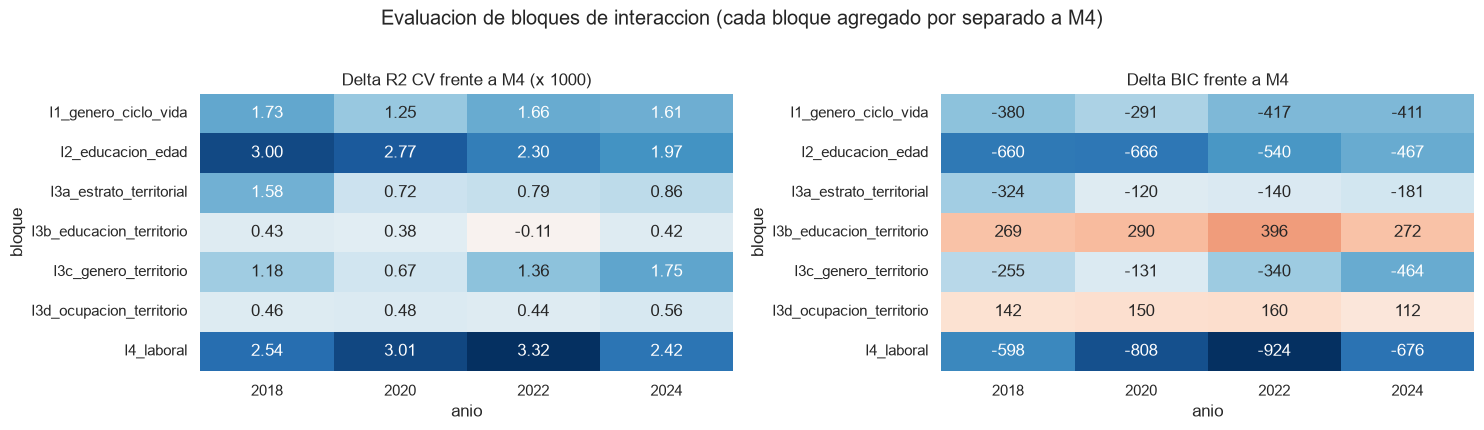

In [13]:
BLOQUES_INTERACCION = {
    "I1_genero_ciclo_vida": ["sexo_desc:edad_poly", "sexo_desc:edo_conyugal_grupo", "sexo_desc:menores"],
    "I2_educacion_edad": ["nivel_educativo:edad_poly"],
    "I3a_estrato_territorial": ["region_banxico:tam_loc_grupo"],
    "I3b_educacion_territorio": ["nivel_educativo:tam_loc_grupo", "nivel_educativo:region_banxico"],
    "I3c_genero_territorio": ["sexo_desc:region_banxico", "sexo_desc:tam_loc_grupo"],
    "I3d_ocupacion_territorio": ["sinco_division:tam_loc_grupo"],
    "I4_laboral": ["subor_principal_desc:segsoc_desc", "subor_principal_desc:horas_spline"],
}
NIVELES_EDUCATIVOS = [c for c in CATEGORIAS["nivel_educativo"] if c != "Secundaria"]
REGIONES = CATEGORIAS["region_banxico"]
LOCALIDADES = CATEGORIAS["tam_loc_grupo"]


def efectos_territoriales(nombre_bloque, resultado, nombres, anio):
    """Efectos totales (principal + interaccion) por celda territorial, con IC agrupados por hogar."""
    filas = []
    ref_loc, ref_reg = REFERENCIAS["tam_loc_grupo"], REFERENCIAS["region_banxico"]
    if nombre_bloque == "I3a_estrato_territorial":
        for r in REGIONES:
            for t in LOCALIDADES:
                pesos = {}
                if r != ref_reg: pesos[f"region_banxico[{r}]"] = 1
                if t != ref_loc: pesos[f"tam_loc_grupo[{t}]"] = 1
                if r != ref_reg and t != ref_loc: pesos[f"region_banxico[{r}]:tam_loc_grupo[{t}]"] = 1
                if pesos:
                    est, se, lo, hi = combinacion_lineal(resultado, nombres, pesos)
                    filas.append({"efecto": "estrato territorial vs Centro | Urbana grande", "region": r,
                                  "localidad": t, "beta": est, "error_estandar": se, "ic_inferior": lo, "ic_superior": hi})
    if nombre_bloque == "I3b_educacion_territorio":
        for nivel in NIVELES_EDUCATIVOS:
            for r in REGIONES:
                for t in LOCALIDADES:
                    pesos = {f"nivel_educativo[{nivel}]": 1}
                    if t != ref_loc: pesos[f"nivel_educativo[{nivel}]:tam_loc_grupo[{t}]"] = 1
                    if r != ref_reg: pesos[f"nivel_educativo[{nivel}]:region_banxico[{r}]"] = 1
                    est, se, lo, hi = combinacion_lineal(resultado, nombres, pesos)
                    filas.append({"efecto": f"{nivel} vs Secundaria", "region": r, "localidad": t, "beta": est,
                                  "error_estandar": se, "ic_inferior": lo, "ic_superior": hi})
    if nombre_bloque == "I3c_genero_territorio":
        for r in REGIONES:
            for t in LOCALIDADES:
                pesos = {"sexo_desc[Mujer]": 1}
                if r != ref_reg: pesos[f"sexo_desc[Mujer]:region_banxico[{r}]"] = 1
                if t != ref_loc: pesos[f"sexo_desc[Mujer]:tam_loc_grupo[{t}]"] = 1
                est, se, lo, hi = combinacion_lineal(resultado, nombres, pesos)
                filas.append({"efecto": "Mujer vs Hombre", "region": r, "localidad": t, "beta": est,
                              "error_estandar": se, "ic_inferior": lo, "ic_superior": hi})
    tabla = pd.DataFrame(filas)
    if not tabla.empty:
        tabla = tabla.assign(anio=anio, bloque=nombre_bloque,
                             efecto_pct=pct(tabla.beta), ic_inferior_pct=pct(tabla.ic_inferior),
                             ic_superior_pct=pct(tabla.ic_superior))
    return tabla


filas, tablas_territoriales = [], []
base_m4 = escalera.loc[escalera.especificacion.eq("M4_ocupacion_sector")].set_index("anio")
for anio in ANIOS:
    d = datos[anio]
    for bloque, terminos in BLOQUES_INTERACCION.items():
        inicio = time.time()
        aj = ajustar_ols(d, ESPECIFICACIONES["M4_ocupacion_sector"] + terminos, cluster=True)
        cv = validacion_cruzada(aj["X"], aj["y"], folds_por_anio[anio])
        columnas_bloque = [c for t in terminos for c in aj["mapa"][t]]
        w, gl, p = wald_columnas(aj["cluster"], aj["X"].columns, columnas_bloque)
        m = metricas_ajuste(aj["ajuste"])
        filas.append({"anio": anio, "bloque": bloque, "parametros_bloque": len(columnas_bloque),
                      "delta_r2": m["r2"] - base_m4.loc[anio, "r2"],
                      "delta_r2_ajustado": m["r2_ajustado"] - base_m4.loc[anio, "r2_ajustado"],
                      "delta_aic": m["aic"] - base_m4.loc[anio, "aic"], "delta_bic": m["bic"] - base_m4.loc[anio, "bic"],
                      "delta_r2_cv": cv["r2_cv"] - base_m4.loc[anio, "r2_cv"],
                      "wald_cluster": w, "gl_wald": gl, "p_wald": p, "segundos": time.time() - inicio})
        tablas_territoriales.append(efectos_territoriales(bloque, aj["cluster"], aj["X"].columns, anio))
evaluacion_bloques = pd.DataFrame(filas)
evaluacion_bloques["cumple_regla"] = evaluacion_bloques.delta_bic.lt(0) & evaluacion_bloques.delta_r2_cv.gt(0)
decision_bloques = evaluacion_bloques.groupby("bloque").agg(
    anios_que_cumplen=("cumple_regla", "sum"), delta_r2_cv_promedio=("delta_r2_cv", "mean"),
    delta_bic_maximo=("delta_bic", "max"), p_wald_maximo=("p_wald", "max"))
decision_bloques["incluido_en_m5"] = decision_bloques.anios_que_cumplen.eq(len(ANIOS))
BLOQUES_SELECCIONADOS = decision_bloques.index[decision_bloques.incluido_en_m5].tolist()
efectos_territoriales_bloques = pd.concat(tablas_territoriales, ignore_index=True)
display(evaluacion_bloques.drop(columns="segundos"))
display(decision_bloques)
print("Bloques seleccionados para M5:", BLOQUES_SELECCIONADOS)

fig, ejes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, valor, titulo, formato in [(ejes[0], "delta_r2_cv", "Delta R2 CV frente a M4 (x 1000)", ".2f"),
                                   (ejes[1], "delta_bic", "Delta BIC frente a M4", ".0f")]:
    matriz = evaluacion_bloques.pivot(index="bloque", columns="anio", values=valor)
    if valor == "delta_r2_cv":
        matriz = matriz * 1000
    sns.heatmap(matriz, annot=True, fmt=formato, cmap="RdBu" if valor == "delta_r2_cv" else "RdBu_r",
                center=0, ax=ax, cbar=False)
    ax.set_title(titulo)
fig.suptitle("Evaluacion de bloques de interaccion (cada bloque agregado por separado a M4)", y=1.02)
fig.tight_layout()
mostrar_figura(fig, "evaluacion_bloques_interaccion")

### Especificación final M5 y su contraparte estatal

M5 = M4 + los bloques que cumplieron la regla en los cuatro años. Se estima en cada año con errores agrupados por hogar y se muestra el `summary()` completo del año de diagnóstico.

**Cómo leer los coeficientes principales de M5.** Cuando una variable interactúa con otras, su coeficiente principal es su asociación **en las categorías de referencia de las variables con que interactúa**. Por ejemplo, `sexo_desc[Mujer]` en M5 es la brecha para una persona de 40 años, soltera, sin menores en el hogar, en la región Centro y en una localidad urbana grande. La brecha en otro perfil es la suma del coeficiente principal y de las interacciones correspondientes (sección 7, efectos territoriales). Por eso, para leer brechas promedio, se usan M3 y M4, y M5 se usa para el ajuste y la heterogeneidad. Como sensibilidad geográfica, `M5_entidad` sustituye la región Banxico por la entidad federativa (referencia Ciudad de México) y elimina los términos que interactúan con región; nunca entran ambas geografías juntas.

In [14]:
ESPECIFICACIONES["M5_final"] = ESPECIFICACIONES["M4_ocupacion_sector"] + [
    t for b in BLOQUES_SELECCIONADOS for t in BLOQUES_INTERACCION[b]]
ESPECIFICACIONES["M5_entidad"] = [t for t in ESPECIFICACIONES["M5_final"] if "region_banxico" not in t] + ["entidad"]
filas, wald_m5 = [], []
modelos_m5 = {}
coeficientes_entidad = []
for anio in ANIOS:
    d = datos[anio]
    for nombre in ["M5_final", "M5_entidad"]:
        aj = ajustar_ols(d, ESPECIFICACIONES[nombre], cluster=True)
        cv = validacion_cruzada(aj["X"], aj["y"], folds_por_anio[anio], grupos_duan=grupos_duan_por_anio[anio])
        cv_guardado[(anio, nombre)] = {k: cv[k] for k in ("pred", "media_train", "duan", "duan_grupo")}
        filas.append({"anio": anio, "especificacion": nombre, **metricas_ajuste(aj["ajuste"]),
                      "r2_cv": cv["r2_cv"], "rmse_cv": cv["rmse_cv"], "r2_cv_sd_pliegues": cv["r2_cv_sd_pliegues"],
                      "columnas_eliminadas": len(aj["eliminadas"])})
        if nombre == "M5_final":
            modelos_m5[anio] = aj
            for bloque in BLOQUES_SELECCIONADOS:
                columnas = [c for t in BLOQUES_INTERACCION[bloque] for c in aj["mapa"][t]]
                w, gl, p = wald_columnas(aj["cluster"], aj["X"].columns, columnas)
                wald_m5.append({"anio": anio, "bloque": bloque, "wald_cluster": w, "gl": gl, "p_value": p})
            if anio == ANIO_DIAGNOSTICO:
                print(f"\nM5_final | {anio} | errores estandar agrupados por hogar")
                display(aj["cluster"].summary())
        else:
            tabla = tabla_coeficientes(aj["cluster"], aj["X"].columns)
            coeficientes_entidad.append(tabla.loc[tabla.termino.str.startswith("entidad[")].assign(anio=anio))
            del aj
modelos_finales = pd.DataFrame(filas)
escalera_completa = pd.concat([escalera, modelos_finales], ignore_index=True)
display(modelos_finales[["anio", "especificacion", "k", "r2", "r2_ajustado", "aic", "bic", "r2_cv", "r2_cv_sd_pliegues"]])
display(pd.DataFrame(wald_m5))


M5_final | 2024 | errores estandar agrupados por hogar


<class 'statsmodels.iolib.summary.Summary'>
"""
                                        OLS Regression Results                                       
=====================================================================================================
Dep. Variable:     log1p_ingreso_persona_laboral_negocio_tri   R-squared:                       0.537
Model:                                                   OLS   Adj. R-squared:                  0.537
Method:                                        Least Squares   F-statistic:                     1037.
Date:                                       Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                                               19:07:04   Log-Likelihood:            -1.7277e+05
No. Observations:                                     141578   AIC:                         3.458e+05
Df Residuals:                                         141463   BIC:                         3.469e+05
Df Model:                                                114                                         
Covariance Type:                                     cluster                                         
====================================================================================================================================================
                                                                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------------------------------
const                                                                                8.9056      0.068    130.286      0.000       8.772       9.040
edad_c                                                                              -0.0262      0.004     -6.734      0.000      -0.034      -0.019
edad_c2                                                                             -0.0299      0.003    -11.133      0.000      -0.035      -0.025
dos_o_mas_trabajos                                                                   0.0407      0.009      4.523      0.000       0.023       0.058
horas_10                                                                             0.5891      0.024     24.460      0.000       0.542       0.636
horas_s20                                                                           -0.3694      0.035    -10.627      0.000      -0.438      -0.301
horas_s40                                                                           -0.0595      0.043     -1.372      0.170      -0.144       0.025
horas_s48                                                                           -0.0034      0.049     -0.071      0.944      -0.099       0.092
horas_s60                                                                           -0.1052      0.029     -3.689      0.000      -0.161      -0.049
sexo_desc[Mujer]                                                                    -0.0012      0.014     -0.085      0.932      -0.029       0.026
hablaind_desc[Sí]                                                                   -0.1801      0.012    -15.072      0.000      -0.204      -0.157
segsoc_desc[Sí]                                                                      0.1576      0.015     10.830      0.000       0.129       0.186
subor_principal_desc[No aplica: sin trabajo principal reportado]                     0.0537      0.048      1.119      0.263      -0.040       0.148
subor_principal_desc[Sí]                                                            -0.8418      0.074    -11.395      0.000      -0.987      -0.697
contrato_principal_desc[No aplica: sin contrato principal documentado]              -0.9166      0.054    -16.995      0.000      -1.022      -0.811
contrato_principal_desc[Sí]                                                          0.1614      0.006     27.605      0.000       0.150       0.173

,anio,especificacion,k,r2,r2_ajustado,aic,bic,r2_cv,r2_cv_sd_pliegues
0,2018,M5_final,115,0.545842,0.545410,306904.871662,308019.876808,0.544646,0.001641
1,2018,M5_entidad,131,0.550055,0.549567,305818.036080,307088.172377,0.548744,0.001608
2,2020,M5_final,115,0.519154,0.518761,372804.250631,373936.432501,0.518138,0.003573
3,2020,M5_entidad,131,0.522900,0.522455,371746.087725,373035.790550,0.521729,0.003328
4,2022,M5_final,115,0.525298,0.524915,354969.199433,356103.117135,0.524482,0.003536
5,2022,M5_entidad,131,0.532612,0.532182,352803.816688,354095.496853,0.531612,0.003955
6,2024,M5_final,115,0.537258,0.536886,345769.578283,346903.547982,0.536328,0.005381
7,2024,M5_entidad,131,0.544164,0.543745,343672.764703,344964.504100,0.543141,0.005652


,anio,bloque,wald_cluster,gl,p_value
0,2018,I1_genero_ciclo_vida,450.312954,7,3.804056e-93
1,2018,I2_educacion_edad,759.371258,14,5.379454e-153
2,2018,I3a_estrato_territorial,331.811519,9,4.582666e-66
3,2018,I3c_genero_territorio,220.388307,6,8.599163e-45
4,2018,I4_laboral,350.143009,7,1.148377e-71
5,2020,I1_genero_ciclo_vida,366.172799,7,4.242181e-75
6,2020,I2_educacion_edad,802.114880,14,3.903046e-162
7,2020,I3a_estrato_territorial,177.428861,9,1.743511e-33
8,2020,I3c_genero_territorio,126.129576,6,8.387356e-25
9,2020,I4_laboral,528.403334,7,6.252447e-110


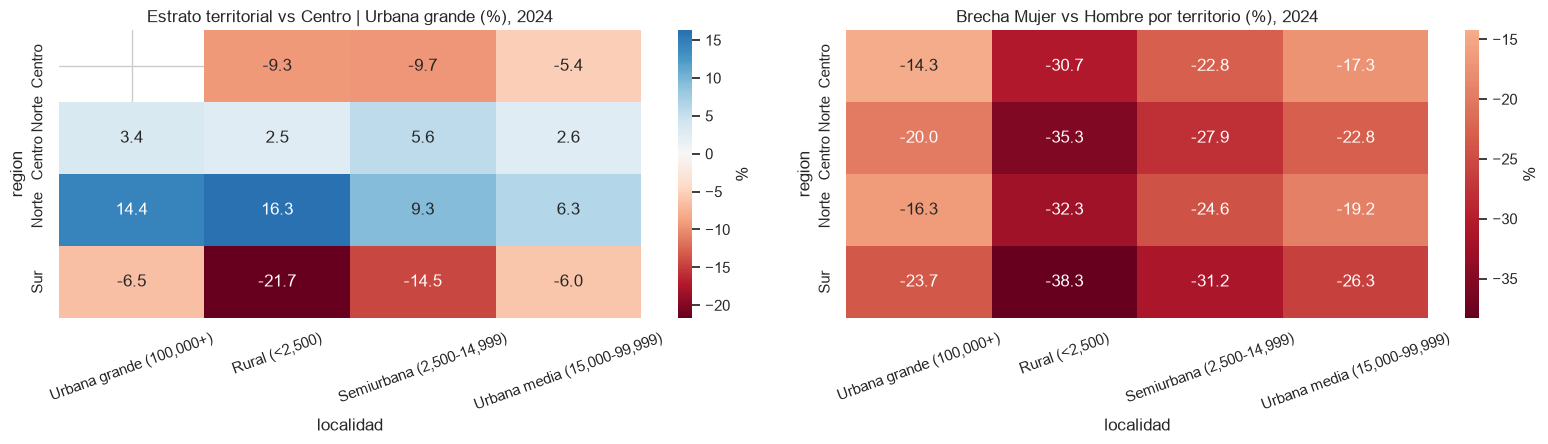

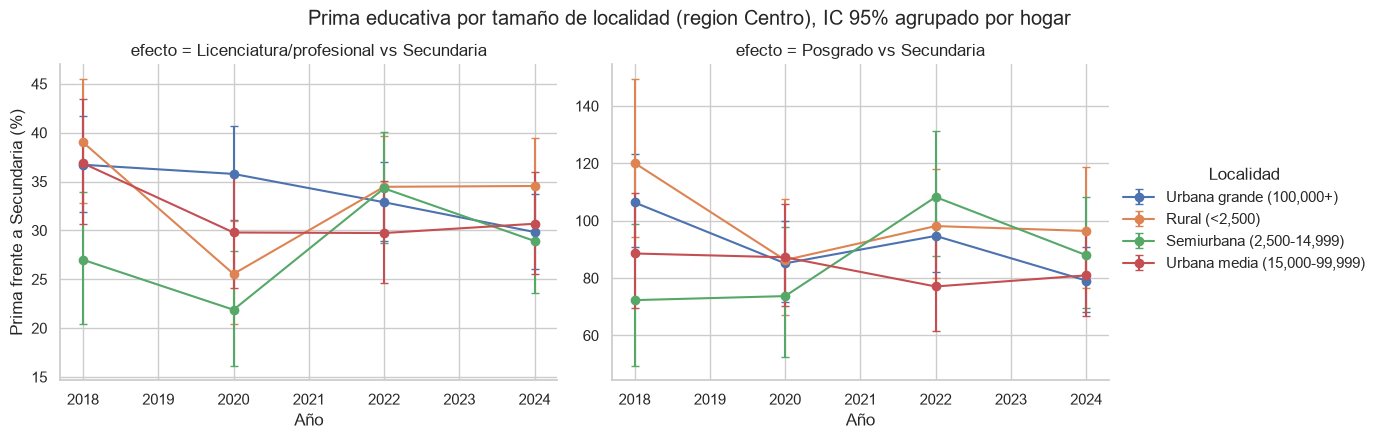

anio,2018,2020,2022,2024
region,,,,
Centro,-16.934406,-19.955564,-16.315319,-14.260667
Centro Norte,-21.462947,-20.479045,-20.617088,-19.987740
Norte,-20.230982,-20.987660,-18.125449,-16.274447
Sur,-21.006600,-21.677456,-22.730169,-23.658941


In [15]:
efectos = efectos_territoriales_bloques
d_diag = efectos.loc[efectos.anio.eq(ANIO_DIAGNOSTICO)]
fig, ejes = plt.subplots(1, 2, figsize=(16, 4.6))
estratos = d_diag.loc[d_diag.bloque.eq("I3a_estrato_territorial")]
if not estratos.empty:
    sns.heatmap(estratos.pivot(index="region", columns="localidad", values="efecto_pct").loc[REGIONES, LOCALIDADES],
                annot=True, fmt=".1f", cmap="RdBu", center=0, ax=ejes[0], cbar_kws={"label": "%"})
    ejes[0].set_title(f"Estrato territorial vs Centro | Urbana grande (%), {ANIO_DIAGNOSTICO}")
genero = d_diag.loc[d_diag.bloque.eq("I3c_genero_territorio")]
if not genero.empty:
    sns.heatmap(genero.pivot(index="region", columns="localidad", values="efecto_pct").loc[REGIONES, LOCALIDADES],
                annot=True, fmt=".1f", cmap="RdBu", center=0, ax=ejes[1], cbar_kws={"label": "%"})
    ejes[1].set_title(f"Brecha Mujer vs Hombre por territorio (%), {ANIO_DIAGNOSTICO}")
for ax in ejes:
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
mostrar_figura(fig, "efectos_territoriales_heatmap")

educacion = efectos.loc[efectos.bloque.eq("I3b_educacion_territorio")
                        & efectos.efecto.isin(["Licenciatura/profesional vs Secundaria", "Posgrado vs Secundaria"])
                        & efectos.region.eq(REFERENCIAS["region_banxico"])]
if not educacion.empty:
    grid = sns.FacetGrid(educacion, col="efecto", hue="localidad", height=4, aspect=1.4, sharey=False)
    grid.map_dataframe(lambda data, color, label: plt.errorbar(
        data.anio, data.efecto_pct, yerr=[data.efecto_pct - data.ic_inferior_pct, data.ic_superior_pct - data.efecto_pct],
        marker="o", capsize=3, color=color, label=label))
    grid.add_legend(title="Localidad")
    grid.set_axis_labels("Año", "Prima frente a Secundaria (%)")
    grid.figure.suptitle("Prima educativa por tamaño de localidad (region Centro), IC 95% agrupado por hogar", y=1.04)
    mostrar_figura(grid.figure, "prima_educativa_por_localidad")
display(efectos.loc[efectos.bloque.eq("I3c_genero_territorio")
                    & efectos.localidad.eq(REFERENCIAS["tam_loc_grupo"])]
        .pivot(index="region", columns="anio", values="efecto_pct"))

Los efectos territoriales se calculan con cada bloque agregado a M4 (no necesariamente con M5) y sus intervalos usan la covarianza agrupada por hogar del mismo ajuste, incluidos los términos cruzados: $\widehat{\operatorname{Var}}(\hat\beta_1 + \hat\beta_3) = \hat V_{11} + \hat V_{33} + 2\hat V_{13}$. Son diferencias porcentuales en $1+$ingreso **dentro de cada año**; compararlas entre años exige una interacción con año como en el notebook 14, porque una diferencia de *p-values* no prueba un cambio.

## 8. Geografía: estratos territoriales, varianza y efectos estatales

**Heterocedasticidad por estrato.** Si $\operatorname{Var}(u_i \mid x_i) = \sigma^2_{g(i)}$ depende del estrato $g$ (región × tamaño de localidad × subordinación), OLS sigue siendo consistente, pero deja de ser eficiente. Los errores agrupados por hogar corrigen la inferencia; ninguna de las dos cosas cambia los coeficientes ni el $R^2$. Por eso "estabilizar la varianza" mejora la **precisión**, no el ajuste. La varianza se estabiliza con **mínimos cuadrados generalizados factibles** (FGLS):

$$\hat\sigma^2_g = \frac{1}{n_g}\sum_{i \in g}\hat u_i^2, \qquad \hat\beta_{FGLS} = (X'\hat\Omega^{-1}X)^{-1}X'\hat\Omega^{-1}y, \qquad \hat\Omega = \operatorname{diag}\big(\hat\sigma^2_{g(i)}\big).$$

En validación cruzada, $\hat\sigma^2_g$ se estima solo con el entrenamiento de cada pliegue. La heterocedasticidad se contrasta con la prueba de Breusch–Pagan en su versión robusta de Koenker: se regresa $\hat u_i^2$ sobre los indicadores de estrato y $LM = nR^2_{aux} \sim \chi^2_{G-1}$.

**Modelos separados por tamaño de localidad.** La forma más flexible de estratificar es estimar $\ln(1+y_i) = x_i'\beta_s + u_i$ por separado en cada estrato $s$ (rural, semiurbano, urbano medio, urbano grande), lo que equivale a interactuar **todos** los regresores con el estrato. Como un hogar pertenece a una sola localidad, las muestras de los estratos son independientes entre sí y la igualdad de un subconjunto de coeficientes se contrasta con un Wald tipo Chow:

$$W = \hat d'\big(\widehat{\operatorname{Var}}(\hat d)\big)^{-1}\hat d \sim \chi^2_{(S-1)q},\qquad \hat d = (\hat\beta_2 - \hat\beta_1,\dots,\hat\beta_S - \hat\beta_1),$$

donde $\widehat{\operatorname{Var}}(\hat d)$ tiene bloques $\hat V_s + \hat V_1$ en la diagonal y $\hat V_1$ fuera de ella, todos agrupados por hogar.

**Efectos estatales con contracción empírica bayesiana.** Con 31 contrastes estatales, los estados con poca muestra tienen estimaciones ruidosas. Bajo el modelo jerárquico $\hat\theta_j \mid \theta_j \sim N(\theta_j, v_j)$, $\theta_j \sim N(\mu, \tau^2)$, el estimador de Bayes empírico es

$$\hat\theta_j^{EB} = \hat\mu + B_j(\hat\theta_j - \hat\mu), \qquad B_j = \frac{\hat\tau^2}{\hat\tau^2 + v_j},$$

con $\hat\mu$ ponderado por precisión y $\hat\tau^2$ por momentos de DerSimonian y Laird (1986):

$$\hat\tau^2 = \max\Big\{0,\ \frac{Q - (J-1)}{\sum w_j - \sum w_j^2/\sum w_j}\Big\},\qquad Q = \sum_j w_j(\hat\theta_j - \hat\mu)^2,\quad w_j = 1/v_j.$$

Las estimaciones imprecisas (con $v_j$ grande) se contraen más hacia la media (Efron y Morris, 1975). Es una alternativa transparente a un modelo mixto con intercepto aleatorio por entidad, cuya estimación con `statsmodels.MixedLM` no convergió de manera confiable con $n \approx 140{,}000$ en la exploración previa.

,anio,bp_estrato_territorial,gl_estrato,p_estrato,bp_subordinacion,p_subordinacion
0,2018,1280.485951,15,8.308870e-264,9476.731813,0.0
1,2020,1153.584127,15,1.519831e-236,10768.854078,0.0
2,2022,1526.647853,15,0.000000e+00,12655.428570,0.0
3,2024,1641.583510,15,0.000000e+00,12244.185860,0.0


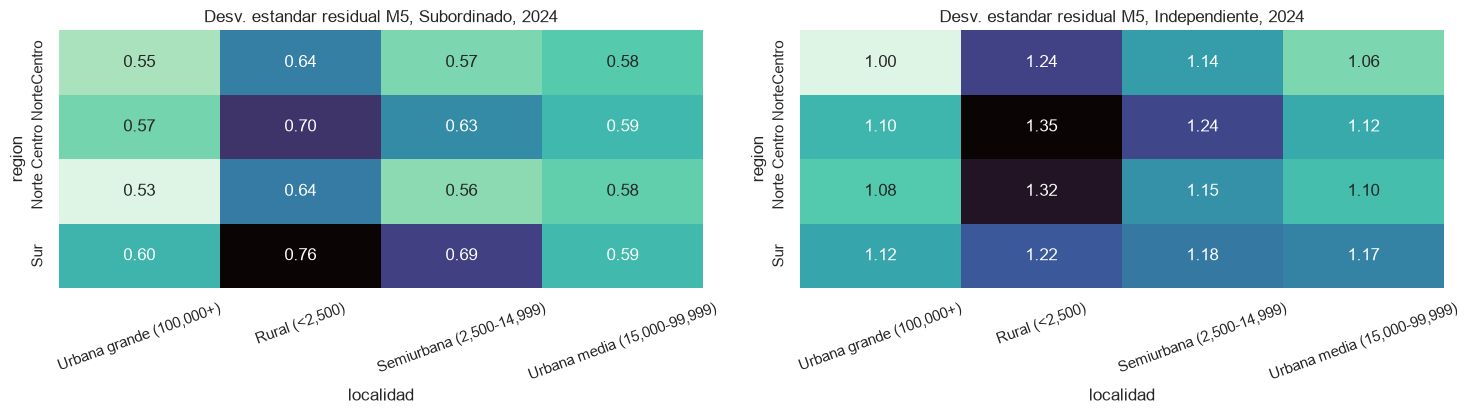

In [16]:
filas, sd_estratos = [], []
for anio in ANIOS:
    d = datos[anio]
    residuo = modelos_m5[anio]["ajuste"].resid.to_numpy()
    estratos_bp = pd.get_dummies(d.estrato_territorial, drop_first=True, dtype=float)
    lm, p_lm, _, _ = het_breuschpagan(residuo, sm.add_constant(estratos_bp.to_numpy()), robust=True)
    lm_s, p_s, _, _ = het_breuschpagan(residuo, sm.add_constant(pd.get_dummies(d.subor_grupo, drop_first=True, dtype=float).to_numpy()), robust=True)
    filas.append({"anio": anio, "bp_estrato_territorial": lm, "gl_estrato": estratos_bp.shape[1], "p_estrato": p_lm,
                  "bp_subordinacion": lm_s, "p_subordinacion": p_s})
    sd_estratos.append(pd.DataFrame({"residuo": residuo, "region": d.region_banxico, "localidad": d.tam_loc_grupo,
                                     "subordinacion": d.subor_grupo})
                       .groupby(["region", "localidad", "subordinacion"]).residuo.agg(["std", "size"])
                       .reset_index().assign(anio=anio))
heterocedasticidad_estratos = pd.DataFrame(filas)
sd_residual_estratos = pd.concat(sd_estratos, ignore_index=True)
display(heterocedasticidad_estratos)

fig, ejes = plt.subplots(1, 2, figsize=(15, 4.3))
diag = sd_residual_estratos.loc[sd_residual_estratos.anio.eq(ANIO_DIAGNOSTICO)]
for ax, grupo in zip(ejes, ["Subordinado", "Independiente"]):
    sns.heatmap(diag.loc[diag.subordinacion.eq(grupo)].pivot(index="region", columns="localidad", values="std")
                .loc[REGIONES, LOCALIDADES], annot=True, fmt=".2f", cmap="mako_r", ax=ax, cbar=False)
    ax.set_title(f"Desv. estandar residual M5, {grupo}, {ANIO_DIAGNOSTICO}")
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
mostrar_figura(fig, "varianza_residual_estratos")

In [17]:
TERMINOS_CLAVE = ["sexo_desc[Mujer]", "nivel_educativo[Media superior]", "nivel_educativo[Licenciatura/profesional]",
                  "nivel_educativo[Posgrado]", "grado_relativo", "segsoc_desc[Sí]", "subor_principal_desc[Sí]",
                  "contrato_principal_desc[Sí]", "hablaind_desc[Sí]", "etnia_grupo[Si]",
                  "tam_loc_grupo[Rural (<2,500)]", "region_banxico[Sur]", "region_banxico[Norte]"]

filas, coeficientes_fgls = [], []
for anio in ANIOS:
    d = datos[anio]
    aj = modelos_m5[anio]
    grupos_var = (d.estrato_territorial + " | " + d.subor_grupo).to_numpy()
    sigma2 = pd.Series(aj["ajuste"].resid.to_numpy() ** 2).groupby(grupos_var).mean()
    pesos = 1 / sigma2.reindex(grupos_var).to_numpy()
    wls = sm.WLS(aj["y"], aj["X"], weights=pesos).fit(method="qr")
    wls_cl = wls.get_robustcov_results(cov_type="cluster", groups=codigos_hogar(d), use_correction=True, use_t=False)
    cv = validacion_cruzada(aj["X"], aj["y"], folds_por_anio[anio], grupos_varianza=grupos_var)
    pred_in = aj["X"].to_numpy() @ np.asarray(wls.params)
    r2_no_ponderado = 1 - np.sum((aj["y"] - pred_in) ** 2) / np.sum((aj["y"] - aj["y"].mean()) ** 2)
    filas.append({"anio": anio, "estimador": "FGLS por estrato x subordinacion", "grupos_varianza": len(sigma2),
                  "r2_no_ponderado": r2_no_ponderado, "r2_cv": cv["r2_cv"],
                  "r2_cv_ols_m5": modelos_finales.set_index(["anio", "especificacion"]).loc[(anio, "M5_final"), "r2_cv"]})
    ols_tabla = tabla_coeficientes(aj["cluster"], aj["X"].columns).set_index("termino")
    fgls_tabla = tabla_coeficientes(wls_cl, aj["X"].columns).set_index("termino")
    for termino in [t for t in TERMINOS_CLAVE if t in ols_tabla.index]:
        coeficientes_fgls.append({"anio": anio, "termino": termino,
                                  "ols_pct": ols_tabla.loc[termino, "efecto_pct"], "ols_ee": ols_tabla.loc[termino, "error_estandar"],
                                  "fgls_pct": fgls_tabla.loc[termino, "efecto_pct"], "fgls_ee": fgls_tabla.loc[termino, "error_estandar"]})
fgls_estratos = pd.DataFrame(filas)
comparacion_ols_fgls = pd.DataFrame(coeficientes_fgls)
comparacion_ols_fgls["razon_ee_fgls_ols"] = comparacion_ols_fgls.fgls_ee / comparacion_ols_fgls.ols_ee
display(fgls_estratos)
display(comparacion_ols_fgls.loc[comparacion_ols_fgls.anio.eq(ANIO_DIAGNOSTICO)])

,anio,estimador,grupos_varianza,r2_no_ponderado,r2_cv,r2_cv_ols_m5
0,2018,FGLS por estrato x subordinacion,48,0.542204,0.541177,0.544646
1,2020,FGLS por estrato x subordinacion,48,0.515940,0.515096,0.518138
2,2022,FGLS por estrato x subordinacion,48,0.520717,0.520071,0.524482
3,2024,FGLS por estrato x subordinacion,48,0.532353,0.531612,0.536328


,anio,termino,ols_pct,ols_ee,fgls_pct,fgls_ee,razon_ee_fgls_ols
39,2024,sexo_desc[Mujer],-0.120077,0.014091,-0.624647,0.011565,0.820758
40,2024,nivel_educativo[Media superior],11.776268,0.008473,11.929902,0.006704,0.791305
41,2024,nivel_educativo[Licenciatura/profesional],40.349687,0.010080,38.858657,0.008218,0.815328
42,2024,nivel_educativo[Posgrado],70.445981,0.018334,68.102631,0.015634,0.852741
43,2024,grado_relativo,2.733140,0.002619,2.403534,0.002127,0.812182
44,2024,segsoc_desc[Sí],17.069108,0.014552,24.430552,0.014567,1.001010
45,2024,subor_principal_desc[Sí],-56.908145,0.073876,-54.799472,0.077000,1.042296
46,2024,contrato_principal_desc[Sí],17.509753,0.005845,19.837612,0.005627,0.962720
47,2024,hablaind_desc[Sí],-16.482073,0.011950,-11.939163,0.010248,0.857612
48,2024,etnia_grupo[Si],-4.854782,0.006429,-4.389784,0.005393,0.838966


,anio,localidad,n,r2,r2_ajustado,bic,r2_cv_estrato
0,2018,"Urbana grande (100,000+)",43910,0.519960,0.518875,102321.202692,0.516321
1,2018,"Rural (<2,500)",44036,0.526712,0.525656,121998.571184,0.523792
2,2018,"Semiurbana (2,500-14,999)",16363,0.503265,0.500241,43542.293754,0.495927
3,2018,"Urbana media (15,000-99,999)",15745,0.526282,0.523285,39236.982909,0.518528
4,2018,TOTAL modelos separados,120054,NaN,NaN,NaN,0.547026
5,2018,TOTAL M5 conjunto,120054,NaN,NaN,NaN,0.544646
6,2020,"Urbana grande (100,000+)",50343,0.518674,0.517725,125342.914598,0.515850
7,2020,"Rural (<2,500)",51870,0.496132,0.495178,147752.838018,0.493941
8,2020,"Semiurbana (2,500-14,999)",19207,0.487319,0.484662,53295.916682,0.480243
9,2020,"Urbana media (15,000-99,999)",17974,0.503682,0.500933,47440.679543,0.495635


anio,2018,2020,2022,2024
conjunto,,,,
edad (polinomio),0.199956,0.587969,0.272205,0.612927
escolaridad (niveles),0.000427,0.053348,0.000078,0.000043
horas (spline),0.011935,0.055440,0.000631,0.000002
seguridad social,0.000012,0.024490,0.000337,0.000269
sexo,0.201504,0.002352,0.200618,0.970479


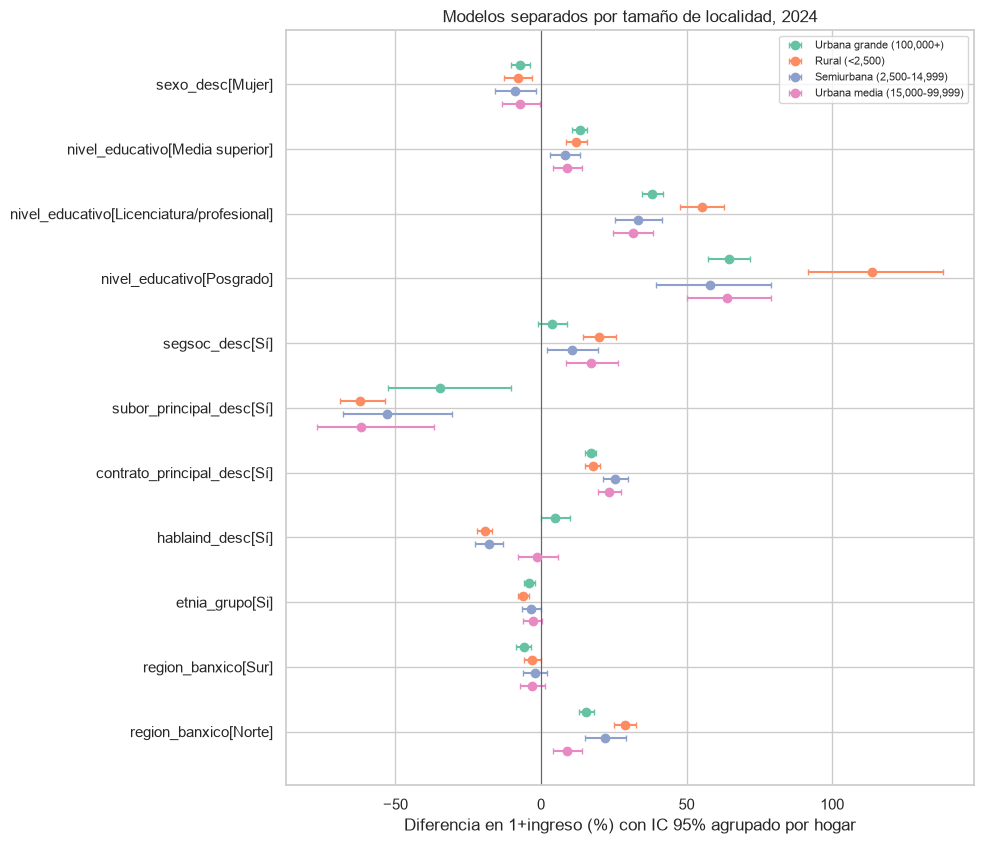

In [18]:
ESPECIFICACION_ESTRATO = [t for t in ESPECIFICACIONES["M5_final"] if "tam_loc_grupo" not in t]
CONJUNTOS_HETEROGENEIDAD = {
    "escolaridad (niveles)": lambda c: c.startswith("nivel_educativo[") and ":" not in c,
    "sexo": lambda c: c == "sexo_desc[Mujer]",
    "edad (polinomio)": lambda c: c in ("edad_c", "edad_c2"),
    "horas (spline)": lambda c: c in COMPUESTOS["horas_spline"],
    "seguridad social": lambda c: c == "segsoc_desc[Sí]",
}


def wald_entre_grupos(resultados, condicion):
    """Wald de igualdad de coeficientes entre muestras independientes (bloques diagonales)."""
    comunes = set.intersection(*[{c for c in nombres if condicion(c)} for _, nombres in resultados.values()])
    columnas = sorted(comunes)
    if not columnas:
        return np.nan, 0, np.nan
    betas, covs = [], []
    for resultado, nombres in resultados.values():
        idx = [list(nombres).index(c) for c in columnas]
        betas.append(np.asarray(resultado.params)[idx])
        covs.append(np.asarray(resultado.cov_params())[np.ix_(idx, idx)])
    q, S = len(columnas), len(betas)
    d = np.concatenate([betas[s] - betas[0] for s in range(1, S)])
    V = np.zeros(((S - 1) * q, (S - 1) * q))
    for a in range(S - 1):
        for b in range(S - 1):
            V[a*q:(a+1)*q, b*q:(b+1)*q] = covs[0] + (covs[a + 1] if a == b else 0)
    estadistico = float(d @ np.linalg.solve(V, d))
    return estadistico, (S - 1) * q, float(chi2.sf(estadistico, (S - 1) * q))


filas, coef_estratos, wald_estratos = [], [], []
for anio in ANIOS:
    d = datos[anio]
    combinada = np.empty(len(d))
    resultados_estrato = {}
    for localidad in LOCALIDADES:
        mascara = d.tam_loc_grupo.eq(localidad).to_numpy()
        sub = d.loc[mascara].reset_index(drop=True)
        aj = ajustar_ols(sub, ESPECIFICACION_ESTRATO, cluster=True)
        cv = validacion_cruzada(aj["X"], aj["y"], restringir_particiones(folds_por_anio[anio], mascara))
        combinada[mascara] = cv["pred"]
        resultados_estrato[localidad] = (aj["cluster"], aj["X"].columns)
        filas.append({"anio": anio, "localidad": localidad, **metricas_ajuste(aj["ajuste"]), "r2_cv_estrato": cv["r2_cv"]})
        tabla = tabla_coeficientes(aj["cluster"], aj["X"].columns)
        coef_estratos.append(tabla.loc[tabla.termino.isin(TERMINOS_CLAVE)].assign(anio=anio, localidad=localidad))
    referencia = cv_guardado[(anio, "M5_final")]
    yv = datos[anio][LOG_TARGET].to_numpy()
    sst = np.sum((yv - referencia["media_train"]) ** 2)
    filas.append({"anio": anio, "localidad": "TOTAL modelos separados", "n": len(d),
                  "r2_cv_estrato": 1 - np.sum((yv - combinada) ** 2) / sst})
    filas.append({"anio": anio, "localidad": "TOTAL M5 conjunto", "n": len(d),
                  "r2_cv_estrato": 1 - np.sum((yv - referencia["pred"]) ** 2) / sst})
    for conjunto, condicion in CONJUNTOS_HETEROGENEIDAD.items():
        w, gl, p = wald_entre_grupos(resultados_estrato, condicion)
        wald_estratos.append({"anio": anio, "conjunto": conjunto, "wald": w, "gl": gl, "p_value": p})
    del resultados_estrato
modelos_por_localidad = pd.DataFrame(filas)
coeficientes_por_localidad = pd.concat(coef_estratos, ignore_index=True)
heterogeneidad_localidad = pd.DataFrame(wald_estratos)
display(modelos_por_localidad[["anio", "localidad", "n", "r2", "r2_ajustado", "bic", "r2_cv_estrato"]])
display(heterogeneidad_localidad.pivot(index="conjunto", columns="anio", values="p_value"))

diag = coeficientes_por_localidad.loc[coeficientes_por_localidad.anio.eq(ANIO_DIAGNOSTICO)
                                      & ~coeficientes_por_localidad.termino.str.startswith(("grado_relativo",))]
terminos_plot = [t for t in TERMINOS_CLAVE if t in set(diag.termino) and not t.startswith("tam_loc")]
fig, ax = plt.subplots(figsize=(10, 0.6 * len(terminos_plot) + 2))
desplazamiento = dict(zip(LOCALIDADES, np.linspace(-0.3, 0.3, len(LOCALIDADES))))
colores_loc = dict(zip(LOCALIDADES, sns.color_palette("Set2", len(LOCALIDADES))))
for localidad in LOCALIDADES:
    sub = diag.loc[diag.localidad.eq(localidad)].set_index("termino").reindex(terminos_plot)
    posiciones = np.arange(len(terminos_plot)) + desplazamiento[localidad]
    ax.errorbar(sub.efecto_pct, posiciones, xerr=[sub.efecto_pct - sub.ic_inferior_pct, sub.ic_superior_pct - sub.efecto_pct],
                fmt="o", capsize=2, color=colores_loc[localidad], label=localidad)
ax.axvline(0, color="0.4", linewidth=0.8)
ax.set_yticks(range(len(terminos_plot)), terminos_plot)
ax.invert_yaxis()
ax.set_xlabel("Diferencia en 1+ingreso (%) con IC 95% agrupado por hogar")
ax.set_title(f"Modelos separados por tamaño de localidad, {ANIO_DIAGNOSTICO}")
ax.legend(fontsize=8)
fig.tight_layout()
mostrar_figura(fig, "coeficientes_por_localidad")

,anio,mu_ponderada_pct,tau,contraccion_media,contraccion_maxima
0,2018,-9.413531,0.140429,0.021792,0.034258
1,2020,2.053450,0.159840,0.017113,0.022363
2,2022,-0.648473,0.166530,0.012886,0.017981
3,2024,-1.682172,0.156141,0.013520,0.018948


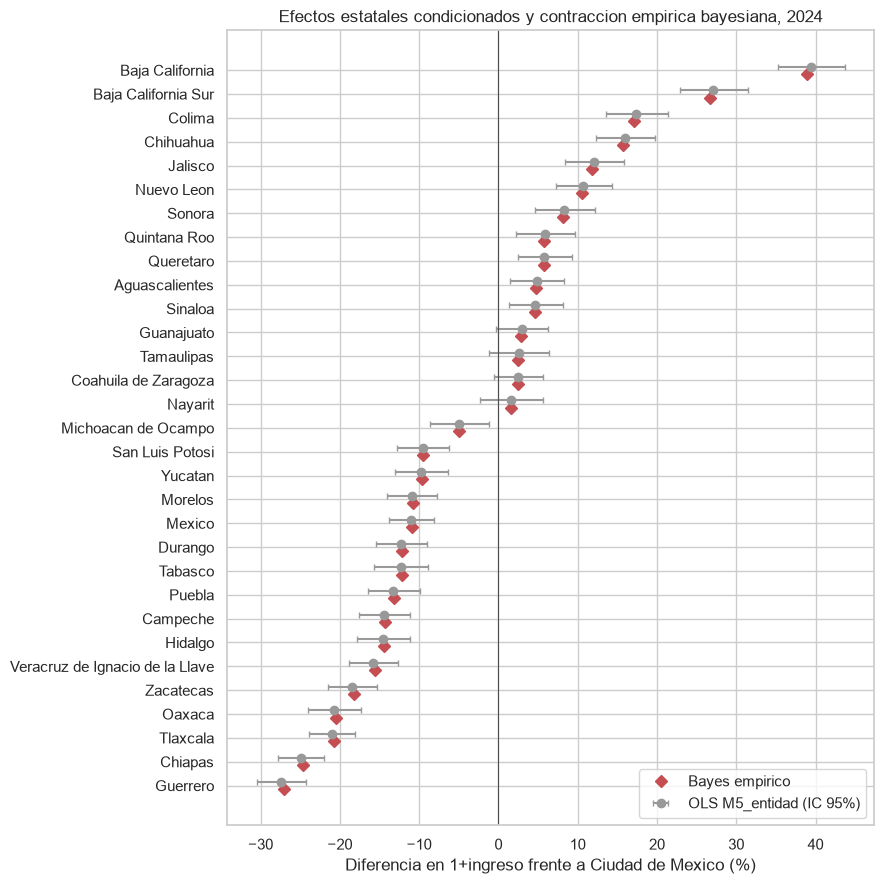

In [19]:
def contraccion_empirica_bayes(theta, varianza):
    w = 1 / varianza
    mu = np.sum(w * theta) / np.sum(w)
    Q = np.sum(w * (theta - mu) ** 2)
    tau2 = max(0.0, (Q - (len(theta) - 1)) / (np.sum(w) - np.sum(w ** 2) / np.sum(w)))
    B = tau2 / (tau2 + varianza)
    return mu + B * (theta - mu), B, mu, tau2


tablas, resumen = [], []
for tabla in coeficientes_entidad:
    theta, varianza = tabla.coeficiente.to_numpy(), tabla.error_estandar.to_numpy() ** 2
    eb, B, mu, tau2 = contraccion_empirica_bayes(theta, varianza)
    tablas.append(tabla.assign(entidad=tabla.termino.str.slice(8, -1), coeficiente_eb=eb, factor_contraccion=B,
                               efecto_eb_pct=pct(eb)))
    resumen.append({"anio": int(tabla.anio.iloc[0]), "mu_ponderada_pct": pct(mu), "tau": np.sqrt(tau2),
                    "contraccion_media": float(np.mean(1 - B)), "contraccion_maxima": float(np.max(1 - B))})
efectos_estatales_eb = pd.concat(tablas, ignore_index=True)
resumen_eb = pd.DataFrame(resumen)
display(resumen_eb)

diag = efectos_estatales_eb.loc[efectos_estatales_eb.anio.eq(ANIO_DIAGNOSTICO)].sort_values("coeficiente_eb")
fig, ax = plt.subplots(figsize=(9, 9))
y = np.arange(len(diag))
ax.errorbar(diag.efecto_pct, y + 0.15, xerr=[diag.efecto_pct - diag.ic_inferior_pct, diag.ic_superior_pct - diag.efecto_pct],
            fmt="o", color="0.6", capsize=2, label="OLS M5_entidad (IC 95%)")
ax.plot(diag.efecto_eb_pct, y - 0.15, "D", color="#c44e52", label="Bayes empirico")
ax.axvline(0, color="0.3", linewidth=0.8)
ax.set_yticks(y, diag.entidad)
ax.set_xlabel("Diferencia en 1+ingreso frente a Ciudad de Mexico (%)")
ax.set_title(f"Efectos estatales condicionados y contraccion empirica bayesiana, {ANIO_DIAGNOSTICO}")
ax.legend(loc="lower right")
fig.tight_layout()
mostrar_figura(fig, "efectos_estatales_bayes_empirico")

## 9. Diagnóstico de supuestos

Supuestos del modelo lineal clásico y su consecuencia práctica aquí:

| Supuesto | Si falla | Diagnóstico | Remedio en este notebook |
| --- | --- | --- | --- |
| A1. Linealidad en parámetros y forma funcional correcta | Sesgo de especificación; $R^2$ menor al alcanzable | RESET de Ramsey, residuos parciales | Polinomios, *splines*, interacciones (secciones 4–7) |
| A2. $\mathbb E[u \mid X] = 0$ (exogeneidad) | Sesgo; lectura causal inválida | No contrastable aquí | Lectura asociativa; variables omitidas discutidas |
| A3. Rango completo | Coeficientes no identificados | Rango, GVIF | Eliminación registrada de columnas colineales; centrado |
| A4. Homocedasticidad y no correlación | EE convencionales inválidos; OLS ineficiente. **No** sesga $\hat\beta$ ni cambia $R^2$ | Breusch–Pagan | EE agrupados por hogar; FGLS (sección 8) |
| A5. Normalidad de $u$ | Solo afecta inferencia exacta en muestras pequeñas | Jarque–Bera, QQ | Irrelevante con $n \approx 140{,}000$ (teorema central del límite); Huber y cuantílica describen colas |

De ahí que "corregir supuestos para aumentar el $R^2$" solo tiene sentido para **A1**: la forma funcional y las variables omitidas. Corregir A4 o A5 mejora la **inferencia**, no el ajuste.

* **RESET** (Ramsey, 1969): se estima $y = X\beta + \gamma_1\hat y^2 + \gamma_2 \hat y^3 + e$ y se contrasta $H_0: \gamma = 0$ con covarianza robusta (HC0). Rechazar indica que potencias del ajuste capturan estructura omitida.
* **Breusch–Pagan robusto** (Koenker, 1981): regresión auxiliar de $\hat u^2$ sobre los regresores, $LM = nR^2_{aux}$.
* **Jarque–Bera**: $JB = \frac n6\big(S^2 + \frac{(K-3)^2}{4}\big)$, con asimetría $S$ y curtosis $K$ de los residuos.
* **GVIF** (Fox y Monette, 1992): para un término con $df$ columnas, $\mathrm{GVIF} = \det(R_{11})\det(R_{22})/\det(R)$, con $R$ la matriz de correlación de los regresores; $\mathrm{GVIF}^{1/(2df)}$ es comparable con $\sqrt{\mathrm{VIF}}$. Valores mayores a $\sqrt{10} \approx 3.16$ suelen considerarse altos.

In [20]:
filas = []
for anio in ANIOS:
    d = datos[anio]
    for nombre in ["M0_base_nb14", "M5_final"]:
        aj = modelos_m5[anio] if nombre == "M5_final" else ajustar_ols(d, ESPECIFICACIONES[nombre], cluster=False)
        ajuste = aj["ajuste"]
        reset = linear_reset(ajuste, power=3, test_type="fitted", use_f=False, cov_type="HC0")
        bp, p_bp, _, _ = het_breuschpagan(ajuste.resid, aj["X"], robust=True)
        jb, p_jb, asimetria, curtosis = jarque_bera(ajuste.resid)
        filas.append({"anio": anio, "especificacion": nombre, "reset_wald": float(np.squeeze(reset.statistic)),
                      "p_reset": float(np.squeeze(reset.pvalue)), "breusch_pagan": bp, "p_bp": p_bp, "jarque_bera": jb,
                      "asimetria": asimetria, "curtosis": curtosis})
diagnostico_supuestos = pd.DataFrame(filas)
display(diagnostico_supuestos)


def gvif(X, mapa):
    columnas = [c for c in X.columns if c != "const"]
    R = np.corrcoef(X[columnas].to_numpy(dtype=float), rowvar=False)
    _, logdet_total = np.linalg.slogdet(R)
    filas = []
    for termino, cols in mapa.items():
        idx = [columnas.index(c) for c in cols if c in columnas]
        if not idx:
            continue
        resto = [i for i in range(len(columnas)) if i not in idx]
        _, logdet_a = np.linalg.slogdet(R[np.ix_(idx, idx)])
        _, logdet_b = np.linalg.slogdet(R[np.ix_(resto, resto)])
        valor = np.exp(logdet_a + logdet_b - logdet_total)
        filas.append({"termino": termino, "gl": len(idx), "gvif": valor, "gvif_ajustado": valor ** (1 / (2 * len(idx)))})
    return pd.DataFrame(filas).sort_values("gvif_ajustado", ascending=False)


_, mapa_m4, _ = construir_matriz(datos[ANIO_DIAGNOSTICO], ESPECIFICACIONES["M4_ocupacion_sector"])
gvif_m4 = gvif(modelos_m4[ANIO_DIAGNOSTICO]["X"], mapa_m4)
display(gvif_m4)

,anio,especificacion,reset_wald,p_reset,breusch_pagan,p_bp,jarque_bera,asimetria,curtosis
0,2018,M0_base_nb14,2907.947598,0.000000e+00,11309.283342,0.0,64172.675217,-0.839449,6.163868
1,2018,M5_final,962.394459,1.043995e-209,13608.857385,0.0,79294.934722,-0.817988,6.629799
2,2020,M0_base_nb14,2835.030448,0.000000e+00,12533.424058,0.0,65870.068435,-0.812005,5.950203
3,2020,M5_final,1154.320772,2.200033e-251,14789.868927,0.0,82051.330877,-0.800590,6.400487
4,2022,M0_base_nb14,4008.758630,0.000000e+00,14564.424501,0.0,99257.543554,-0.854404,6.730082
5,2022,M5_final,1034.606890,2.177551e-225,17051.790484,0.0,121690.471376,-0.827670,7.230589
6,2024,M0_base_nb14,3406.426859,0.000000e+00,14455.500632,0.0,116753.378595,-0.938166,7.033753
7,2024,M5_final,1319.145017,3.558763e-287,16972.865688,0.0,148185.144412,-0.911023,7.669066


,termino,gl,gvif,gvif_ajustado
6,subor_principal_desc,2,132.923600,3.395475
7,contrato_principal_desc,2,75.270460,2.945480
15,alfabetismo,1,2.026842,1.423672
0,edad_poly,2,3.590585,1.376548
3,sexo_desc,1,1.703553,1.305202
5,segsoc_desc,1,1.631648,1.277360
19,sinco_division,9,66.225326,1.262316
20,scian_sector,11,79.232697,1.219871
12,parentesco_grupo,4,4.694622,1.213249
14,etnia_grupo,1,1.426305,1.194280


Los GVIF altos de subordinación y contrato no indican un problema de estimación: sus categorías `No aplica` se solapan por construcción (quien no tiene trabajo principal tampoco tiene contrato), y las columnas exactamente redundantes ya fueron eliminadas.

### ¿Es adecuada la escala logarítmica? Perfil de Box–Cox condicional

La $\hat\lambda$ marginal de la sección 4 no condiciona en los regresores. La versión condicional estima $y^{(\lambda)} = x'\beta + u$, $u \sim N(0,\sigma^2)$, y maximiza la verosimilitud perfilada, que incluye el jacobiano de la transformación:

$$\ell_p(\lambda) = -\frac n2\Big[\ln(2\pi) + \ln\frac{SSR(\lambda)}{n} + 1\Big] + (\lambda - 1)\sum_i \ln y_i,$$

con $SSR(\lambda)$ la suma de residuos cuadrados de regresar $y^{(\lambda)}$ sobre las columnas de M4. El intervalo de confianza de 95% contiene los $\lambda$ con $\ell_p(\lambda) \ge \ell_p(\hat\lambda) - \tfrac12\chi^2_{1,0.95}$.

La familia de Box–Cox busca, con un solo parámetro, la escala en la que el modelo lineal se acerca más a sus supuestos: errores aproximadamente normales, varianza homogénea y efectos aditivos. Por eso se usa aquí para justificar la **transformación del target** (su "normalización"). Se comparan tres miembros de referencia:

| $\lambda$ | Transformación | Lectura de los coeficientes |
| --- | --- | --- |
| 1 | nivel (ingreso sin transformar, desplazado en 1) | pesos |
| 0.5 | raíz cuadrada | sin lectura directa |
| 0 | logaritmo ($\lim_{\lambda \to 0} y^{(\lambda)} = \ln y$) | diferencias porcentuales |

Para cada año se reportan:
* $\hat\lambda$ marginal (sección 4) y $\hat\lambda$ condicional;
* la caída de log-verosimilitud $\Delta\ell(\lambda) = \ell_p(\lambda) - \ell_p(\hat\lambda)$ en los tres valores de referencia;
* la **fracción de la ganancia de transformar que captura el logaritmo**:

$$G_{\log} = \frac{\ell_p(0) - \ell_p(1)}{\ell_p(\hat\lambda) - \ell_p(1)},$$

  que vale 1 si el logaritmo fuera óptimo y 0 si no mejorara al nivel;
* la asimetría de los residuos en cada escala.

,anio,lambda_marginal,lambda_hat_condicional,ic_inferior,ic_superior,log_l_maximo,delta_ll_logaritmo,delta_ll_raiz,delta_ll_nivel,lr_logaritmo_vs_optimo,lr_nivel_vs_optimo,ganancia_capturada_por_log,asimetria_residual_logaritmo,asimetria_residual_lambda_hat,asimetria_residual_raiz,asimetria_residual_nivel
0,2018,0.250,0.22,0.22,0.22,-1257794.113,-12788.694,-20196.234,-165789.002,25577.388,331578.004,0.923,-0.815,0.458,4.529,47.757
1,2020,0.247,0.22,0.22,0.22,-1466180.358,-14864.150,-23957.635,-230935.492,29728.299,461870.983,0.936,-0.800,0.485,6.029,120.573
2,2022,0.262,0.22,0.22,0.22,-1527428.357,-14952.217,-23601.450,-201821.890,29904.435,403643.781,0.926,-0.818,0.591,5.198,68.059
3,2024,0.297,0.25,0.25,0.25,-1549291.736,-17831.153,-16574.311,-155260.424,35662.306,310520.847,0.885,-0.908,0.595,3.677,49.548


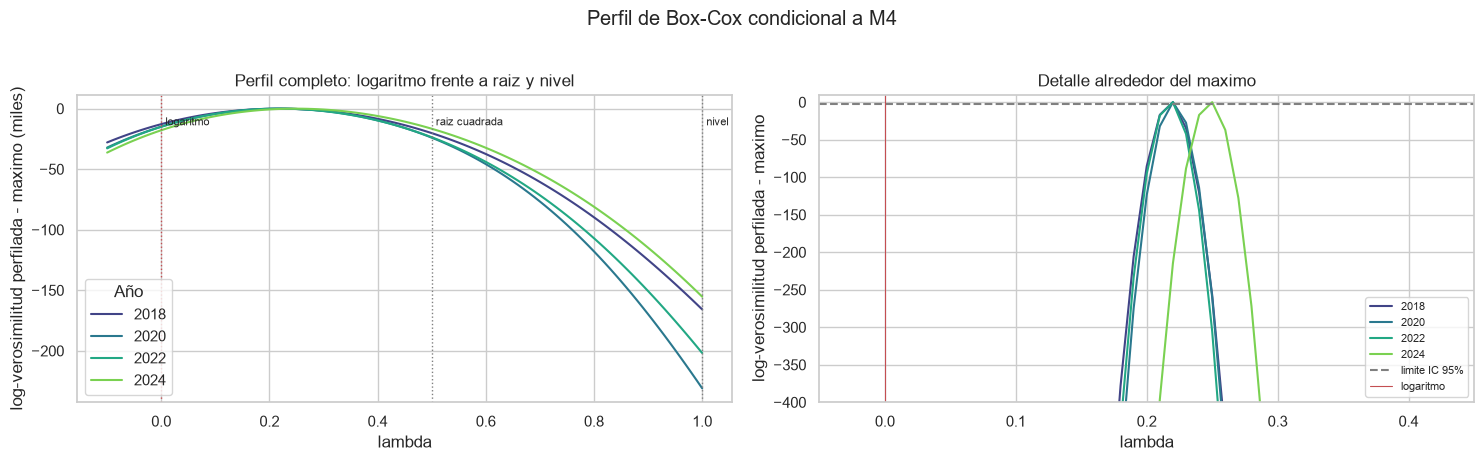

**Resumen de esta ejecución.** $\hat\lambda$ condicional entre 0.22 y 0.25; $\hat\lambda$ marginal entre 0.25 y 0.30. Frente al óptimo, el logaritmo pierde entre 12,789 y 17,831 unidades de log-verosimilitud; la raíz cuadrada, entre 16,574 y 23,958; el nivel, entre 155,260 y 230,935. El logaritmo captura entre 88.5% y 93.6% de la ganancia de transformar. La asimetría residual es de 47.8 a 120.6 en nivel, de -0.91 a -0.80 en logaritmo y de 0.46 a 0.60 en $\hat\lambda$.

In [21]:
def transformar_box_cox(y, lam):
    return np.log(y) if abs(lam) < 1e-12 else (y ** lam - 1) / lam


def asimetria(v):
    v = v - v.mean()
    return float(np.mean(v ** 3) / np.mean(v ** 2) ** 1.5)


GRID_LAMBDA = np.round(np.arange(-0.10, 1.0001, 0.01), 2)
LAMBDAS_REFERENCIA = {0.0: "logaritmo", 0.5: "raiz cuadrada", 1.0: "nivel"}
lambda_marginal = box_cox.set_index("anio").lambda_box_cox_mle
filas, perfiles = [], []
for anio in ANIOS:
    X = modelos_m4[anio]["X"].to_numpy(dtype=float)
    y = datos[anio][TARGET].to_numpy(dtype=float)
    Q, _ = np.linalg.qr(X)
    suma_log = np.sum(np.log(y))
    n = len(y)
    llf, asimetrias = [], {}
    for lam in GRID_LAMBDA:
        z = transformar_box_cox(y, lam)
        residuo = z - Q @ (Q.T @ z)
        llf.append(-n / 2 * (np.log(2 * np.pi) + np.log(np.sum(residuo ** 2) / n) + 1) + (lam - 1) * suma_log)
        for referencia in LAMBDAS_REFERENCIA:
            if np.isclose(lam, referencia):
                asimetrias[referencia] = asimetria(residuo)
    llf = np.array(llf)
    lambda_hat = GRID_LAMBDA[llf.argmax()]
    z = transformar_box_cox(y, lambda_hat)
    asimetria_hat = asimetria(z - Q @ (Q.T @ z))
    del Q
    ll = {referencia: llf[np.isclose(GRID_LAMBDA, referencia)][0] for referencia in LAMBDAS_REFERENCIA}
    dentro = GRID_LAMBDA[llf >= llf.max() - chi2.ppf(0.95, 1) / 2]
    filas.append({
        "anio": anio, "lambda_marginal": lambda_marginal[anio], "lambda_hat_condicional": lambda_hat,
        "ic_inferior": dentro.min(), "ic_superior": dentro.max(), "log_l_maximo": llf.max(),
        "delta_ll_logaritmo": ll[0.0] - llf.max(), "delta_ll_raiz": ll[0.5] - llf.max(),
        "delta_ll_nivel": ll[1.0] - llf.max(),
        "lr_logaritmo_vs_optimo": 2 * (llf.max() - ll[0.0]), "lr_nivel_vs_optimo": 2 * (llf.max() - ll[1.0]),
        "ganancia_capturada_por_log": (ll[0.0] - ll[1.0]) / (llf.max() - ll[1.0]),
        "asimetria_residual_logaritmo": asimetrias[0.0], "asimetria_residual_lambda_hat": asimetria_hat,
        "asimetria_residual_raiz": asimetrias[0.5], "asimetria_residual_nivel": asimetrias[1.0],
    })
    perfiles.append(pd.DataFrame({"anio": anio, "lambda": GRID_LAMBDA, "log_verosimilitud": llf}))
box_cox_condicional = pd.DataFrame(filas)
perfil_box_cox = pd.concat(perfiles, ignore_index=True)
display(box_cox_condicional.round(3))

fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5))
for anio in ANIOS:
    sub = perfil_box_cox.loc[perfil_box_cox.anio.eq(anio)]
    delta = sub.log_verosimilitud - sub.log_verosimilitud.max()
    ejes[0].plot(sub["lambda"], delta / 1000, color=paleta[anio], label=str(anio))
    ejes[1].plot(sub["lambda"], delta, color=paleta[anio], label=str(anio))
for referencia, nombre in LAMBDAS_REFERENCIA.items():
    ejes[0].axvline(referencia, color="#c44e52" if referencia == 0 else "0.5", linestyle=":", linewidth=1)
    ejes[0].annotate(nombre, (referencia, 0), xytext=(3, -12), textcoords="offset points", fontsize=8)
ejes[0].set(xlabel="lambda", ylabel="log-verosimilitud perfilada - maximo (miles)",
            title="Perfil completo: logaritmo frente a raiz y nivel")
ejes[1].axhline(-chi2.ppf(0.95, 1) / 2, color="0.5", linestyle="--", label="limite IC 95%")
ejes[1].axvline(0, color="#c44e52", linewidth=0.8, label="logaritmo")
ejes[1].set_xlim(-0.05, 0.45)
ejes[1].set_ylim(-400, 10)
ejes[1].set(xlabel="lambda", ylabel="log-verosimilitud perfilada - maximo", title="Detalle alrededor del maximo")
ejes[0].legend(title="Año")
ejes[1].legend(fontsize=8)
fig.suptitle("Perfil de Box-Cox condicional a M4", y=1.02)
fig.tight_layout()
mostrar_figura(fig, "perfil_box_cox")

r = box_cox_condicional
display(Markdown(
    f"**Resumen de esta ejecución.** $\\hat\\lambda$ condicional entre {r.lambda_hat_condicional.min():.2f} y "
    f"{r.lambda_hat_condicional.max():.2f}; $\\hat\\lambda$ marginal entre {r.lambda_marginal.min():.2f} y "
    f"{r.lambda_marginal.max():.2f}. Frente al óptimo, el logaritmo pierde entre {-r.delta_ll_logaritmo.max():,.0f} y "
    f"{-r.delta_ll_logaritmo.min():,.0f} unidades de log-verosimilitud; la raíz cuadrada, entre "
    f"{-r.delta_ll_raiz.max():,.0f} y {-r.delta_ll_raiz.min():,.0f}; el nivel, entre {-r.delta_ll_nivel.max():,.0f} y "
    f"{-r.delta_ll_nivel.min():,.0f}. El logaritmo captura entre {100 * r.ganancia_capturada_por_log.min():.1f}% y "
    f"{100 * r.ganancia_capturada_por_log.max():.1f}% de la ganancia de transformar. La asimetría residual es de "
    f"{r.asimetria_residual_nivel.min():.1f} a {r.asimetria_residual_nivel.max():.1f} en nivel, de "
    f"{r.asimetria_residual_logaritmo.min():.2f} a {r.asimetria_residual_logaritmo.max():.2f} en logaritmo y de "
    f"{r.asimetria_residual_lambda_hat.min():.2f} a {r.asimetria_residual_lambda_hat.max():.2f} en $\\hat\\lambda$."
))

#### Qué dice Box–Cox sobre la normalización del target

El resultado **no** demuestra que el logaritmo sea la transformación óptima: con $n \approx 140{,}000$ la prueba de razón de verosimilitud rechaza cualquier valor exacto de $\lambda$, incluido $\lambda = 0$. Lo que sí establece, y es lo que sostiene la elección metodológica, es lo siguiente:

1. **El ingreso en niveles no es una escala defendible para el modelo lineal.** $\lambda = 1$ queda a la mayor distancia del óptimo, y los residuos en nivel tienen una asimetría positiva extrema, dominada por la cola derecha. Es coherente con el $R^2$ de 0.06–0.11 del modelo en pesos (`regional_ampliado`, nivel nominal) del notebook 14.
2. **Los datos piden una transformación fuertemente compresiva.** $\hat\lambda$ se ubica entre 0.2 y 0.3 en los cuatro años, tanto marginal como condicionalmente: lejos del nivel y entre el logaritmo y la raíz cuadrada. La pérdida de verosimilitud del logaritmo y la de la raíz frente al óptimo son de magnitud comparable (según el año, una u otra queda más cerca), y ambas son pequeñas frente a la del nivel.
3. **El logaritmo recupera la mayor parte de la mejora de transformar.** La fracción $G_{\log}$ indica cuánto de la ganancia de verosimilitud entre el nivel y el óptimo captura el logaritmo.
4. **Entre las escalas con interpretación, el logaritmo deja los residuos menos asimétricos.** En nivel la asimetría residual es enorme y positiva, y en raíz cuadrada sigue siendo claramente positiva. En logaritmo es negativa y moderada (−0.80 a −0.91), y en $\hat\lambda$ es positiva y algo menor en magnitud (0.46 a 0.60). Ninguna potencia de la familia elimina la asimetría, que se origina en la cola de ingresos muy bajos.
5. **Hay razones para no usar $\hat\lambda$ directamente:**
   * **Comparabilidad entre años:** $\hat\lambda$ cambia entre años. Con una $\lambda$ propia por año, los coeficientes de cada corte estarían en escalas distintas y no serían comparables, lo que contradice el objetivo temporal del proyecto.
   * **Interpretación:** en la escala $y^{(\lambda)}$ los coeficientes no tienen lectura directa. En logaritmo, $100[\exp(\beta)-1]$ es una diferencia porcentual, que es la forma estándar de la ecuación de ingresos de Mincer y de la literatura.
   * **Supuestos de la estimación de $\lambda$:** $\hat\lambda$ se estima suponiendo errores normales y homocedásticos. Como la heterocedasticidad está documentada (sección 8), parte de $\hat\lambda$ refleja la mezcla de varianzas entre subordinados e independientes y la cola de ingresos muy bajos, no solo la forma de la relación media.
6. **Costo reconocido del logaritmo.** Comprime de más la cola baja, lo que deja asimetría negativa en los residuos. Ese costo se atiende con estimadores que no dependen de la normalidad (Huber, regresión cuantílica), con la corrección de Duan por grupo al volver a pesos y con la sensibilidad $\lambda \approx 0.25$ pendiente.

**Formulación para la tesina.** La transformación logarítmica del ingreso se justifica con la estimación de Box–Cox: el ingreso laboral requiere una transformación fuertemente compresiva ($\hat\lambda \approx 0.2$–$0.3$, lejos de $\lambda = 1$). El logaritmo, miembro límite de la familia, recupera la mayor parte de la ganancia de verosimilitud de transformar y, entre las escalas con interpretación, deja los residuos menos asimétricos. Además, permite interpretar los coeficientes como diferencias porcentuales y conservar una misma escala en los cuatro años. No se presenta como la transformación óptima en sentido estricto, y su sesgo en la cola baja se trata con métodos robustos.

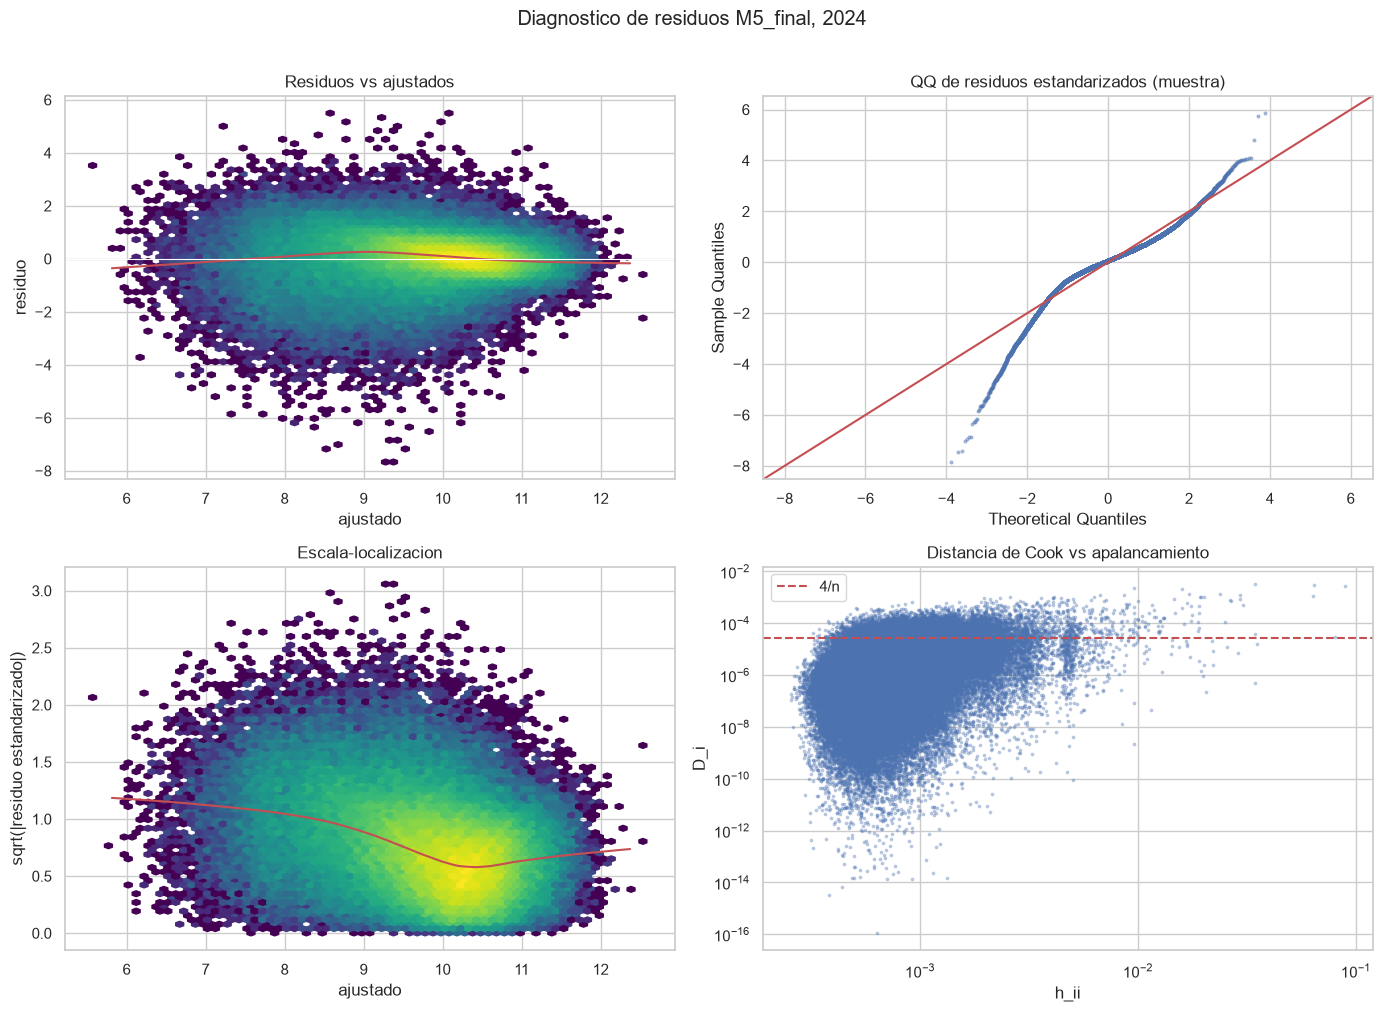

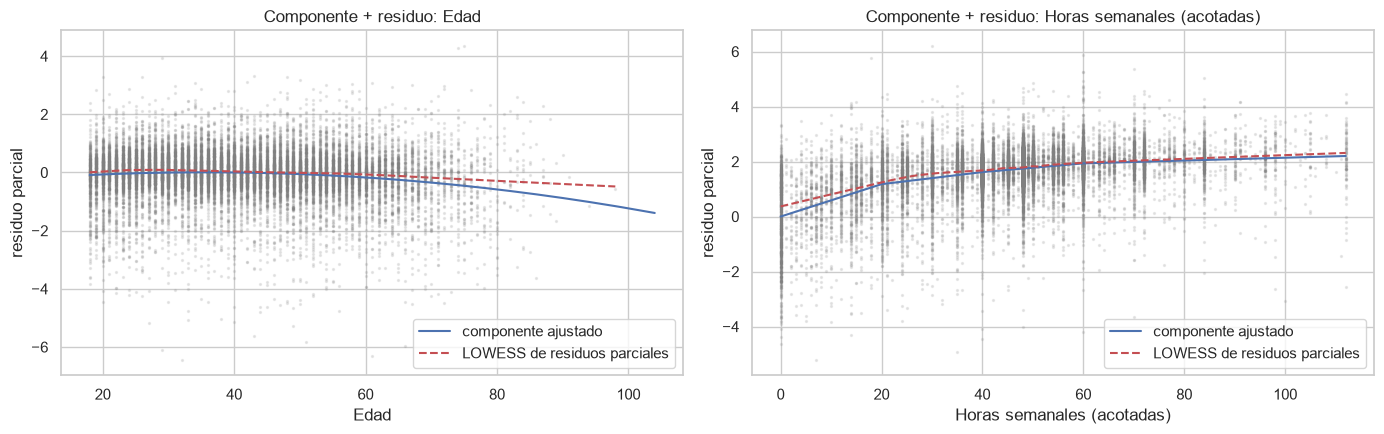

,proporcion_cook_mayor_4n,cook_maximo,apalancamiento_maximo,apalancamiento_medio
0,0.065031,0.003254,0.089199,0.000812


In [22]:
aj = modelos_m5[ANIO_DIAGNOSTICO]
d = datos[ANIO_DIAGNOSTICO]
ajustado, residuo = aj["ajuste"].fittedvalues.to_numpy(), aj["ajuste"].resid.to_numpy()
Q, _ = np.linalg.qr(aj["X"].to_numpy(dtype=float))
apalancamiento = np.einsum("ij,ij->i", Q, Q)
del Q
s2 = aj["ajuste"].ssr / aj["ajuste"].df_resid
estandarizado = residuo / np.sqrt(s2 * (1 - apalancamiento))
cook = residuo ** 2 / (aj["X"].shape[1] * s2) * apalancamiento / (1 - apalancamiento) ** 2
rng = np.random.default_rng(SEMILLA)
m = rng.choice(len(d), size=min(20000, len(d)), replace=False)

fig, ejes = plt.subplots(2, 2, figsize=(14, 10))
ejes[0, 0].hexbin(ajustado, residuo, gridsize=70, bins="log", cmap="viridis")
curva = lowess(residuo[m], ajustado[m], frac=0.3, return_sorted=True)
ejes[0, 0].plot(curva[:, 0], curva[:, 1], color="#c44e52")
ejes[0, 0].axhline(0, color="white", linewidth=0.8)
ejes[0, 0].set(title="Residuos vs ajustados", xlabel="ajustado", ylabel="residuo")
sm.qqplot(estandarizado[m], line="45", ax=ejes[0, 1], markersize=2, alpha=0.4)
ejes[0, 1].set_title("QQ de residuos estandarizados (muestra)")
raiz = np.sqrt(np.abs(estandarizado))
ejes[1, 0].hexbin(ajustado, raiz, gridsize=70, bins="log", cmap="viridis")
curva = lowess(raiz[m], ajustado[m], frac=0.3, return_sorted=True)
ejes[1, 0].plot(curva[:, 0], curva[:, 1], color="#c44e52")
ejes[1, 0].set(title="Escala-localizacion", xlabel="ajustado", ylabel="sqrt(|residuo estandarizado|)")
ejes[1, 1].scatter(apalancamiento, cook, s=3, alpha=0.3)
ejes[1, 1].axhline(4 / len(d), color="#c44e52", linestyle="--", label="4/n")
ejes[1, 1].set(xscale="log", yscale="log", title="Distancia de Cook vs apalancamiento", xlabel="h_ii", ylabel="D_i")
ejes[1, 1].legend()
fig.suptitle(f"Diagnostico de residuos M5_final, {ANIO_DIAGNOSTICO}", y=1.01)
fig.tight_layout()
mostrar_figura(fig, "diagnostico_residuos_m5")

parametros = aj["ajuste"].params
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, variable, columnas, etiqueta in [(ejes[0], "edad", COMPUESTOS["edad_poly"], "Edad"),
                                         (ejes[1], "horas_acotadas", COMPUESTOS["horas_spline"], "Horas semanales (acotadas)")]:
    componente = d[columnas].to_numpy() @ parametros[columnas].to_numpy()
    parcial = residuo + componente
    ax.scatter(d[variable].to_numpy()[m], parcial[m], s=2, alpha=0.15, color="0.5")
    orden_x = np.argsort(d[variable].to_numpy())
    ax.plot(d[variable].to_numpy()[orden_x], componente[orden_x], color="#4c72b0", label="componente ajustado")
    curva = lowess(parcial[m], d[variable].to_numpy()[m], frac=0.3, return_sorted=True)
    ax.plot(curva[:, 0], curva[:, 1], color="#c44e52", linestyle="--", label="LOWESS de residuos parciales")
    ax.set(xlabel=etiqueta, ylabel="residuo parcial", title=f"Componente + residuo: {etiqueta}")
    ax.legend()
fig.tight_layout()
mostrar_figura(fig, "residuos_parciales_m5")
display(pd.DataFrame([{"proporcion_cook_mayor_4n": float(np.mean(cook > 4 / len(d))), "cook_maximo": float(cook.max()),
                       "apalancamiento_maximo": float(apalancamiento.max()), "apalancamiento_medio": float(apalancamiento.mean())}]))

Si la curva LOWESS de los residuos parciales sigue al componente ajustado, la forma funcional elegida (polinomio de edad, *spline* de horas) es adecuada; las desviaciones sistemáticas sugieren otra transformación. Los términos de interacción con edad no se incluyen en el componente: la figura muestra la relación para la categoría de referencia de las variables que interactúan.

## 10. Estimador robusto de Huber

OLS minimiza $\sum_i u_i^2$: un residuo grande pesa cuadráticamente y puede arrastrar los coeficientes. Un **M-estimador** (Huber, 1964) reemplaza el cuadrado por una función $\rho$ que crece más despacio en las colas:

$$\hat\beta_M = \arg\min_\beta \sum_i \rho\!\left(\frac{y_i - x_i'\beta}{\hat\sigma}\right), \qquad
\rho_c(r) = \begin{cases} \tfrac12 r^2 & |r| \le c \\ c|r| - \tfrac12 c^2 & |r| > c \end{cases}$$

Su derivada $\psi_c(r) = \max(-c, \min(c, r))$ acota la influencia de cada residuo. Las condiciones de primer orden $\sum_i \psi_c(r_i)\,x_i = 0$ equivalen a mínimos cuadrados ponderados con pesos

$$w_i = \frac{\psi_c(r_i)}{r_i} = \min\Big(1, \frac{c}{|r_i|}\Big),$$

y se resuelven por **mínimos cuadrados reponderados iterativamente** (IRLS): $\beta^{(t+1)} = (X'W^{(t)}X)^{-1}X'W^{(t)}y$. La escala se estima de forma robusta, $\hat\sigma = \operatorname{MAD}(\hat u)/0.6745$. Con $c = 1.345$ el estimador conserva 95% de eficiencia frente a OLS si los errores son normales, y limita la influencia de residuos grandes cuando no lo son.

**Alcance.** Huber acota la influencia de residuos extremos en $y$, no la de puntos con alto apalancamiento en $x$. Si la distribución del error es simétrica, OLS y Huber estiman el mismo $\beta$; las diferencias señalan asimetría o colas pesadas. Los errores estándar de `statsmodels.RLM` son de tipo sándwich (H1), no agrupados por hogar. Se estima sobre **M4** (efectos principales), que es más interpretable que M5 y menos costosa de estimar. La validación cruzada se calcula solo en el año de diagnóstico.

,anio,escala_robusta,iteraciones,proporcion_ponderada_menor_1,r2_huber_en_muestra,r2_ols_en_muestra,mae_log_huber,mae_log_ols,r2_cv_huber,mae_cv_log_huber,r2_cv_ols,mae_cv_log_ols
0,2018,0.611837,35,0.240067,0.530233,0.535664,0.609952,0.617794,NaN,NaN,NaN,NaN
1,2020,0.661332,32,0.239422,0.505375,0.510535,0.652352,0.660414,NaN,NaN,NaN,NaN
2,2022,0.576279,32,0.242619,0.509559,0.515832,0.586645,0.594640,NaN,NaN,NaN,NaN
3,2024,0.549363,37,0.241930,0.522215,0.528633,0.562715,0.570965,0.521797,0.563081,0.528088,0.571349


huber_pct                      ols_pct                     
anio                                           2018   2020   2022   2024    2018   2020   2022   2024
termino                                                                                              
contrato_principal_desc[Sí]                   12.65  19.60  13.09  12.95   15.14  22.79  14.01  14.73
etnia_grupo[Si]                               -3.37  -2.26  -3.53  -4.01   -4.31  -3.69  -4.40  -5.21
grado_relativo                                 3.84   3.39   3.53   3.37    3.94   3.55   3.64   3.69
hablaind_desc[Sí]                            -14.40 -19.09 -12.70 -14.89  -15.25 -19.48 -14.39 -17.05
nivel_educativo[Licenciatura/profesional]     37.64  29.31  30.40  26.36   38.45  28.94  31.04  27.36
nivel_educativo[Media superior]                8.72   6.49   7.32   7.30    8.93   6.53   7.24   7.64
nivel_educativo[Posgrado]                     97.06  81.88  85.92  67.90  100.98  84.46  89.65  70.02
region_banxico[Norte]                          9.67  20.32  21.49  19.52    9.67  22.41  23.39  20.23
region_banxico[Sur]                          -14.19 -11.80  -7.43  -7.28  -15.76 -12.34  -8.38  -8.35
segsoc_desc[Sí]                               17.18  17.59  16.28  16.54   18.70  18.22  16.72  18.46
sexo_desc[Mujer]                             -23.52 -22.85 -22.21 -20.64  -27.17 -26.36 -26.38 -25.11
subor_principal_desc[Sí]                     -57.91 -61.35 -63.66 -53.57  -61.91 -60.11 -66.07 -58.42
tam_loc_grupo[Rural (<2,500)]                 -1.29   5.33   0.40  -4.80   -1.77   6.56   1.13  -5.54

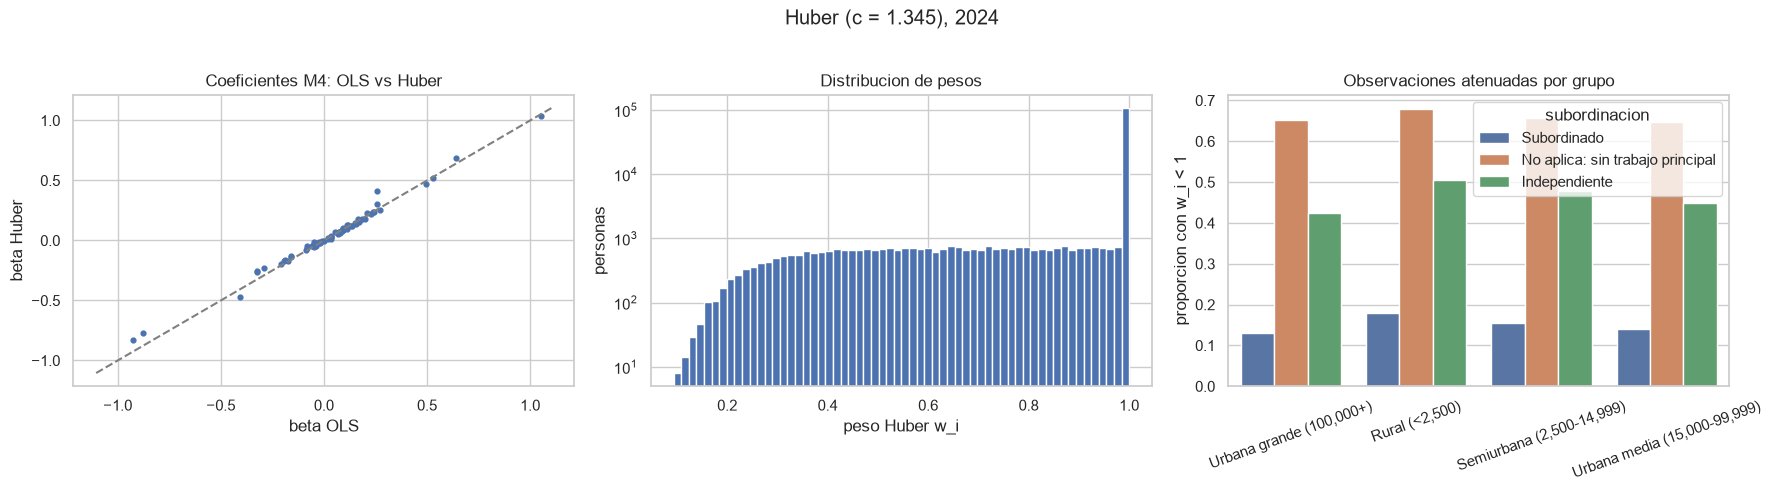

In [23]:
filas, coef_huber, pesos_huber = [], [], {}
if EJECUTAR_HUBER:
    for anio in ANIOS:
        inicio = time.time()
        X, y = modelos_m4[anio]["X"], modelos_m4[anio]["y"]
        huber = sm.RLM(y, X, M=sm.robust.norms.HuberT(t=HUBER_T)).fit(maxiter=100, tol=1e-8)
        pesos_huber[anio] = np.asarray(huber.weights)
        pred = X.to_numpy() @ huber.params.to_numpy()
        ols_pred = X.to_numpy() @ np.asarray(modelos_m4[anio]["cluster"].params)
        fila = {"anio": anio, "escala_robusta": float(huber.scale), "iteraciones": int(huber.fit_history["iteration"]),
                "proporcion_ponderada_menor_1": float(np.mean(pesos_huber[anio] < 1)),
                "r2_huber_en_muestra": 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2),
                "r2_ols_en_muestra": 1 - np.sum((y - ols_pred) ** 2) / np.sum((y - y.mean()) ** 2),
                "mae_log_huber": float(np.mean(np.abs(y - pred))), "mae_log_ols": float(np.mean(np.abs(y - ols_pred))),
                "segundos": time.time() - inicio}
        if EJECUTAR_CV_HUBER and anio == ANIO_DIAGNOSTICO:
            oof = np.empty(len(y))
            media_train = cv_guardado[(anio, "M4_ocupacion_sector")]["media_train"]
            for tr, te in folds_por_anio[anio]:
                ajuste_fold = sm.RLM(y.iloc[tr], X.iloc[tr], M=sm.robust.norms.HuberT(t=HUBER_T)).fit(maxiter=100, tol=1e-8)
                oof[te] = X.iloc[te].to_numpy() @ ajuste_fold.params.to_numpy()
            sst = np.sum((y.to_numpy() - media_train) ** 2)
            fila["r2_cv_huber"] = 1 - np.sum((y.to_numpy() - oof) ** 2) / sst
            fila["mae_cv_log_huber"] = float(np.mean(np.abs(y.to_numpy() - oof)))
            ols_oof = cv_guardado[(anio, "M4_ocupacion_sector")]["pred"]
            fila["r2_cv_ols"] = 1 - np.sum((y.to_numpy() - ols_oof) ** 2) / sst
            fila["mae_cv_log_ols"] = float(np.mean(np.abs(y.to_numpy() - ols_oof)))
        filas.append(fila)
        ols = tabla_coeficientes(modelos_m4[anio]["cluster"], X.columns).set_index("termino")
        rob = tabla_coeficientes(huber, X.columns).set_index("termino")
        coef_huber.append(pd.DataFrame({"anio": anio, "termino": X.columns, "ols": ols.coeficiente.to_numpy(),
                                        "huber": rob.coeficiente.to_numpy(), "ols_pct": ols.efecto_pct.to_numpy(),
                                        "huber_pct": rob.efecto_pct.to_numpy(),
                                        "huber_ic_inferior_pct": rob.ic_inferior_pct.to_numpy(),
                                        "huber_ic_superior_pct": rob.ic_superior_pct.to_numpy()}))
        del huber
    resumen_huber = pd.DataFrame(filas)
    coeficientes_huber = pd.concat(coef_huber, ignore_index=True)
    display(resumen_huber.drop(columns="segundos"))
    display(coeficientes_huber.loc[coeficientes_huber.termino.isin(TERMINOS_CLAVE)]
            .pivot_table(index="termino", columns="anio", values=["ols_pct", "huber_pct"]).round(2))

    diag = coeficientes_huber.loc[coeficientes_huber.anio.eq(ANIO_DIAGNOSTICO) & coeficientes_huber.termino.ne("const")]
    d = datos[ANIO_DIAGNOSTICO]
    w = pesos_huber[ANIO_DIAGNOSTICO]
    fig, ejes = plt.subplots(1, 3, figsize=(18, 4.8))
    ejes[0].scatter(diag.ols, diag.huber, s=12)
    limite = np.abs(diag[["ols", "huber"]].to_numpy()).max() * 1.05
    ejes[0].plot([-limite, limite], [-limite, limite], color="0.5", linestyle="--")
    ejes[0].set(xlabel="beta OLS", ylabel="beta Huber", title="Coeficientes M4: OLS vs Huber")
    ejes[1].hist(w, bins=60, color="#4c72b0")
    ejes[1].set(yscale="log", xlabel="peso Huber w_i", ylabel="personas", title="Distribucion de pesos")
    proporciones = pd.DataFrame({"peso_menor_1": w < 1, "subordinacion": d.subor_grupo, "localidad": d.tam_loc_grupo})
    sns.barplot(data=proporciones, x="localidad", y="peso_menor_1", hue="subordinacion", ax=ejes[2], errorbar=None)
    ejes[2].set(ylabel="proporcion con w_i < 1", xlabel="", title="Observaciones atenuadas por grupo")
    ejes[2].tick_params(axis="x", rotation=20)
    fig.suptitle(f"Huber (c = {HUBER_T}), {ANIO_DIAGNOSTICO}", y=1.02)
    fig.tight_layout()
    mostrar_figura(fig, "huber_diagnostico")

## 11. Regresión cuantílica

OLS modela la media condicional. La **regresión cuantílica** (Koenker y Bassett, 1978) modela el cuantil condicional $\tau$:

$$Q_\tau\big(\ln(1+y) \mid x\big) = x'\beta_\tau, \qquad \hat\beta_\tau = \arg\min_\beta \sum_i \rho_\tau(y_i - x_i'\beta), \qquad \rho_\tau(u) = u\big(\tau - \mathbb 1\{u < 0\}\big).$$

La función de pérdida "*check*" $\rho_\tau$ pondera los residuos positivos con $\tau$ y los negativos con $1-\tau$; con $\tau = 0.5$ se obtiene la mediana (desviaciones absolutas mínimas). El problema es lineal y se resuelve por programación lineal o métodos de punto interior.

**Propiedades útiles aquí.**

* **Robustez:** el estimador depende del signo de los residuos, no de su magnitud, por lo que un ingreso extremo no lo arrastra. Por eso es la alternativa natural a recortar colas.
* **Equivarianza a transformaciones monótonas:** $Q_\tau(h(Y) \mid x) = h\big(Q_\tau(Y \mid x)\big)$ para $h$ creciente. Entonces $Q_\tau(y \mid x) = \exp(x'\hat\beta_\tau) - 1$ **exactamente**, sin corrección de Duan, a diferencia de la media.
* **Heterogeneidad distributiva:** si $\beta_{0.9} > \beta_{0.1}$ para una variable, esta se asocia con mayor dispersión del ingreso **dentro** de su grupo. Es una lectura directa sobre desigualdad.

$\beta_\tau$ describe el desplazamiento del cuantil condicional, no la posición de una persona concreta (el rango no se conserva entre grupos). Como medida de ajuste se usa el pseudo-$R^1$ de Koenker y Machado (1999), $R^1(\tau) = 1 - \hat V(\tau)/\tilde V(\tau)$, con $\hat V$ la pérdida *check* del modelo y $\tilde V$ la del modelo con solo intercepto. Los errores estándar son del sándwich con *kernel* (ancho de banda de Hall–Sheather) que implementa `statsmodels`, no agrupados por hogar. Se estima sobre **M4**: el proceso completo $\tau \in \{0.1, 0.25, 0.5, 0.75, 0.9\}$ en el año de diagnóstico y $\tau \in \{0.1, 0.5, 0.9\}$ en los cuatro años.

anio,2018,2020,2022,2024
tau,,,,
0.10,0.429953,0.403613,0.431054,0.446003
0.25,NaN,NaN,NaN,0.400168
0.50,0.323781,0.313888,0.308761,0.319388
0.75,NaN,NaN,NaN,0.278771
0.90,0.288171,0.268050,0.268590,0.271338


anio                                       2018               2020               2022               2024            
tau                                         0.1   0.5    0.9   0.1   0.5    0.9   0.1   0.5    0.9   0.1   0.5   0.9
termino                                                                                                             
contrato_principal_desc[Sí]                29.6  10.9    9.5  43.0  16.2   14.4  28.7  11.5   10.0  27.3  11.8   8.9
etnia_grupo[Si]                            -3.1  -2.5   -3.6  -4.9  -1.7   -1.5  -5.1  -2.9   -3.6  -6.8  -3.4  -2.9
grado_relativo                              4.2   3.6    3.6   4.5   3.3    3.4   3.1   3.5    3.7   3.7   2.9   3.3
hablaind_desc[Sí]                         -15.6 -13.2   -8.5 -17.3 -19.2  -13.0 -11.7 -10.8   -9.3 -18.8 -13.4 -10.0
nivel_educativo[Licenciatura/profesional]  26.6  36.3   52.0  20.1  27.6   46.7  22.9  29.3   44.6  20.0  25.1  37.2
nivel_educativo[Media superior]             7.2   8.4   11.8   6.8   5.8    8.6   5.9   7.4    9.7   7.0   7.0   8.5
nivel_educativo[Posgrado]                  79.3  96.5  120.3  66.3  79.4  110.2  69.6  86.6  113.0  52.9  68.0  89.6
region_banxico[Norte]                       2.7  10.1   12.2  21.3  19.5   18.9  16.1  21.0   24.5  15.0  19.9  20.9
region_banxico[Sur]                       -19.8 -13.3   -7.6 -14.7 -11.4   -8.3 -11.9  -7.0   -2.7  -9.6  -6.4  -3.0
segsoc_desc[Sí]                            31.0  15.9    9.7  30.5  17.1    8.7  28.7  15.5    9.1  28.1  16.0  10.7
sexo_desc[Mujer]                          -28.3 -21.4  -22.0 -28.3 -20.4  -20.9 -26.1 -20.0  -21.3 -24.3 -18.3 -19.3
subor_principal_desc[Sí]                  -62.5 -57.1  -42.9 -57.2 -62.5  -50.2 -67.3 -63.3  -52.2 -56.1 -54.1 -42.5
tam_loc_grupo[Rural (<2,500)]              -4.8  -0.6   -0.1   5.3   4.6    5.6  -0.4   0.2    3.5 -10.8  -4.6  -2.0

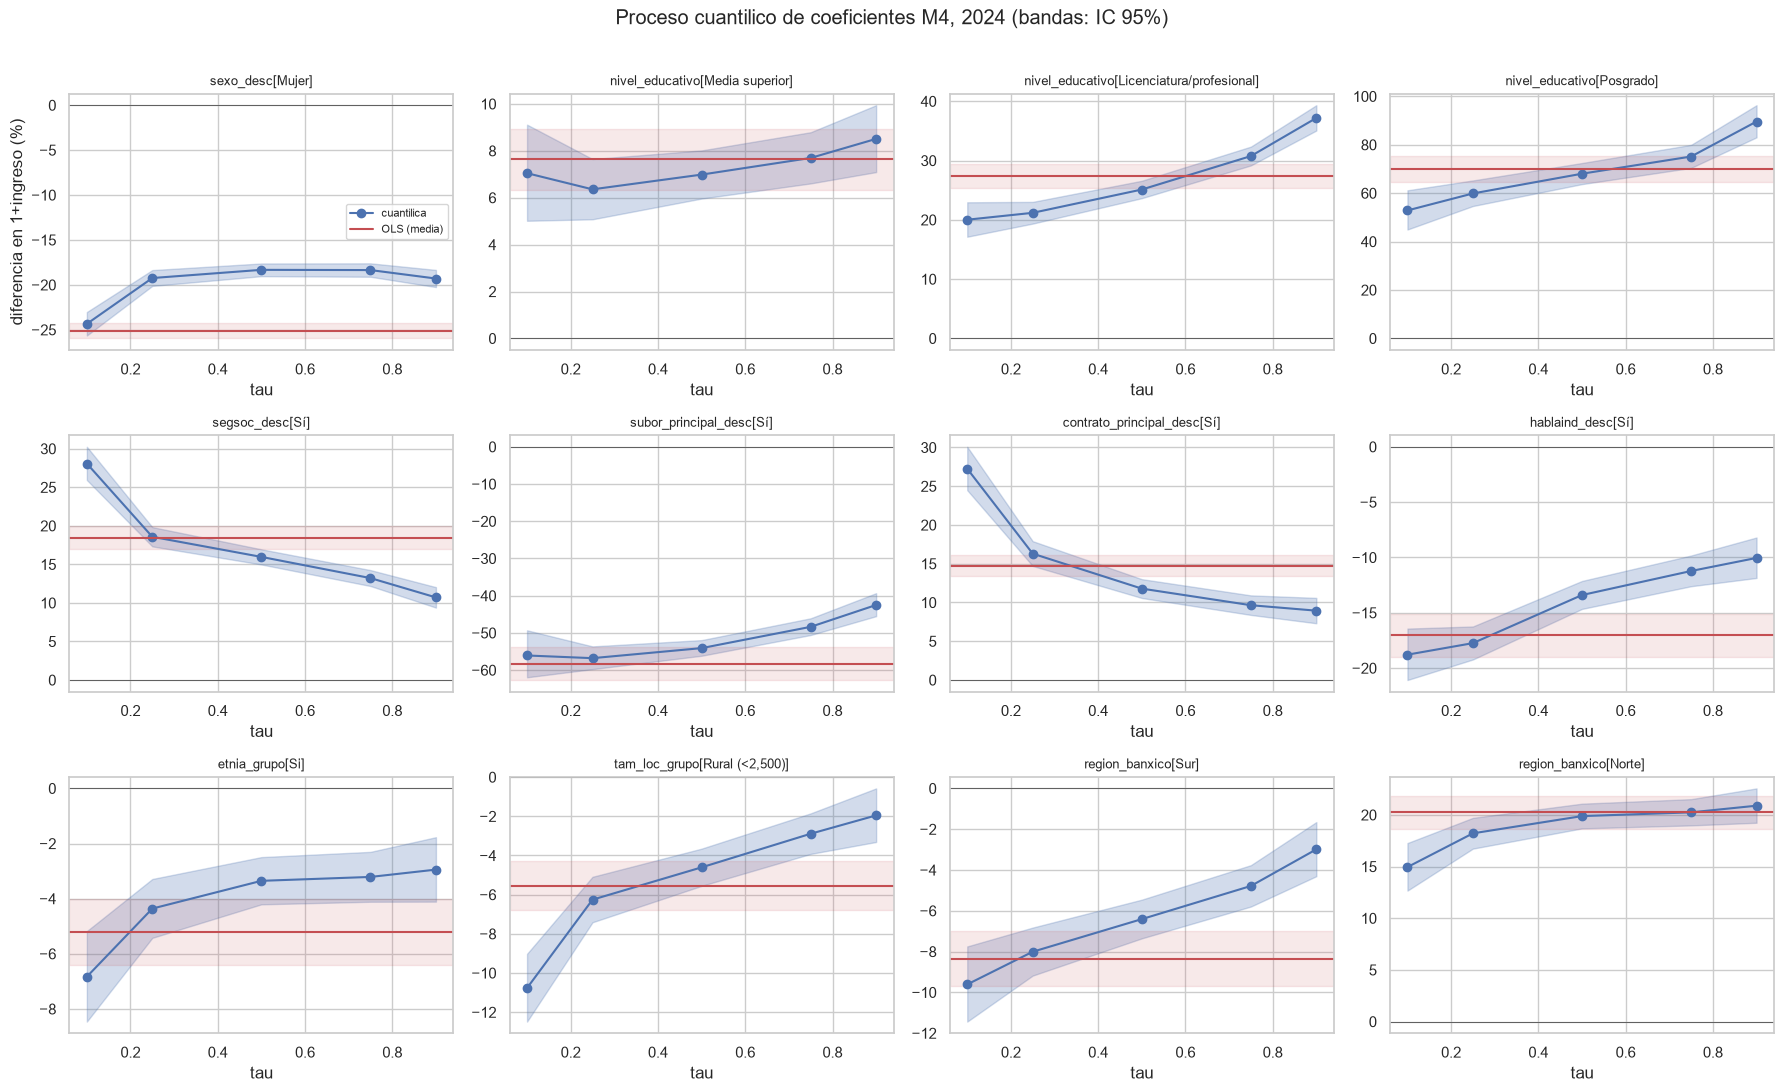

In [24]:
def perdida_check(u, tau):
    return np.sum(u * (tau - (u < 0)))


filas, coef_qr = [], []
if EJECUTAR_CUANTILICA:
    for anio in ANIOS:
        X, y = modelos_m4[anio]["X"], modelos_m4[anio]["y"]
        cuantiles = sorted(set(CUANTILES_ANUALES) | (set(CUANTILES_PROCESO) if anio == ANIO_DIAGNOSTICO else set()))
        for tau in cuantiles:
            inicio = time.time()
            qr = sm.QuantReg(y, X).fit(q=tau, max_iter=5000)
            u = y.to_numpy() - X.to_numpy() @ qr.params.to_numpy()
            u0 = y.to_numpy() - np.quantile(y, tau)
            filas.append({"anio": anio, "tau": tau, "pseudo_r1": 1 - perdida_check(u, tau) / perdida_check(u0, tau),
                          "iteraciones": int(qr.iterations) if hasattr(qr, "iterations") else np.nan,
                          "segundos": time.time() - inicio})
            coef_qr.append(tabla_coeficientes(qr, X.columns).assign(anio=anio, tau=tau))
            del qr
    ajuste_cuantilico = pd.DataFrame(filas)
    coeficientes_cuantilicos = pd.concat(coef_qr, ignore_index=True)
    display(ajuste_cuantilico.drop(columns="segundos").pivot(index="tau", columns="anio", values="pseudo_r1"))
    display(coeficientes_cuantilicos.loc[coeficientes_cuantilicos.termino.isin(TERMINOS_CLAVE)
                                         & coeficientes_cuantilicos.tau.isin(CUANTILES_ANUALES)]
            .pivot_table(index="termino", columns=["anio", "tau"], values="efecto_pct").round(1))

    ols_diag = tabla_coeficientes(modelos_m4[ANIO_DIAGNOSTICO]["cluster"], modelos_m4[ANIO_DIAGNOSTICO]["X"].columns).set_index("termino")
    proceso = coeficientes_cuantilicos.loc[coeficientes_cuantilicos.anio.eq(ANIO_DIAGNOSTICO)]
    terminos_plot = [t for t in TERMINOS_CLAVE if t in set(proceso.termino) and t != "grado_relativo"]
    columnas = 4
    filas_fig = int(np.ceil(len(terminos_plot) / columnas))
    fig, ejes = plt.subplots(filas_fig, columnas, figsize=(18, 3.6 * filas_fig), squeeze=False)
    for ax, termino in zip(ejes.ravel(), terminos_plot):
        serie = proceso.loc[proceso.termino.eq(termino)].sort_values("tau")
        ax.fill_between(serie.tau, serie.ic_inferior_pct, serie.ic_superior_pct, alpha=0.25, color="#4c72b0")
        ax.plot(serie.tau, serie.efecto_pct, marker="o", color="#4c72b0", label="cuantilica")
        fila_ols = ols_diag.loc[termino]
        ax.axhline(fila_ols.efecto_pct, color="#c44e52", label="OLS (media)")
        ax.axhspan(fila_ols.ic_inferior_pct, fila_ols.ic_superior_pct, color="#c44e52", alpha=0.12)
        ax.axhline(0, color="0.3", linewidth=0.6)
        ax.set_title(termino, fontsize=9)
        ax.set_xlabel("tau")
    for ax in ejes.ravel()[len(terminos_plot):]:
        ax.set_visible(False)
    ejes[0, 0].set_ylabel("diferencia en 1+ingreso (%)")
    ejes[0, 0].legend(fontsize=8)
    fig.suptitle(f"Proceso cuantilico de coeficientes M4, {ANIO_DIAGNOSTICO} (bandas: IC 95%)", y=1.01)
    fig.tight_layout()
    mostrar_figura(fig, "proceso_cuantilico")

## 12. Subordinados e independientes por separado

El ingreso de un asalariado es un salario pactado; el de un independiente (cuenta propia o empleador) es una ganancia que mezcla retorno al trabajo, al capital del negocio y al riesgo, con más error de reporte. Los procesos generadores difieren, y la sección 4 muestra que la dispersión también. Se estiman ecuaciones separadas

$$\ln(1+y_i) = x_i'\beta_g + u_i,\qquad \operatorname{Var}(u_i \mid g) = \sigma^2_g,\qquad g \in \{\text{subordinado}, \text{independiente}\},$$

que equivalen a interactuar todos los regresores con el grupo. Las personas sin trabajo principal (alrededor de 4%) quedan fuera de esta comparación. Se reporta el $R^2_{CV}$ de cada ecuación y se compara con el desempeño fuera de muestra de M5 conjunto **en las mismas personas y pliegues**. La prueba de igualdad de coeficientes entre grupos supone independencia entre muestras, lo cual es una **aproximación**: un hogar puede tener un miembro asalariado y otro independiente.

,anio,grupo,n,r2,r2_ajustado,bic,sd_residual,r2_cv_separado,r2_cv_m5_conjunto
0,2018,Subordinado,88185,0.522951,0.522382,178932.038877,0.663216,0.564211,0.549510
1,2018,Independiente,26726,0.472217,0.470135,86692.435285,1.202868,0.548093,0.526444
2,2020,Subordinado,99278,0.507476,0.506955,211379.703141,0.697703,0.557570,0.545372
3,2020,Independiente,33332,0.401988,0.400116,111723.134747,1.273985,0.491873,0.472097
4,2022,Subordinado,104419,0.512492,0.512001,199394.667397,0.625306,0.553354,0.536974
5,2022,Independiente,32186,0.441782,0.439973,104258.029995,1.203679,0.513382,0.491506
6,2024,Subordinado,104929,0.525893,0.525418,192444.611988,0.602149,0.567790,0.550595
7,2024,Independiente,31444,0.441701,0.439831,100151.532143,1.170970,0.517404,0.496259


anio,2018,2020,2022,2024
conjunto,,,,
edad (polinomio),3.269670e-03,8.398221e-03,2.163561e-05,9.216315e-05
escolaridad (niveles),1.371477e-02,6.735354e-04,2.402033e-02,6.346635e-02
horas (spline),9.894968e-17,4.181175e-21,1.565991e-17,3.911446e-24
seguridad social,2.438723e-14,5.405824e-10,8.533845e-19,4.064158e-13
sexo,3.774665e-03,1.257275e-06,4.884446e-03,3.723216e-04


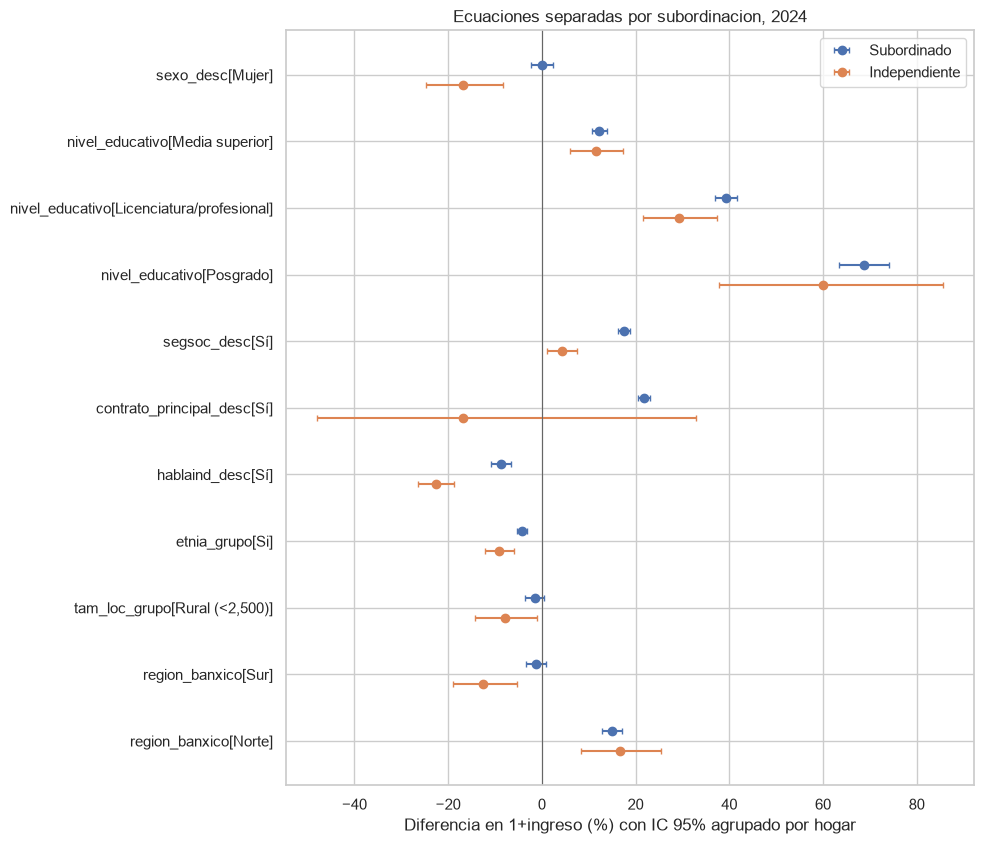

In [25]:
ESPECIFICACION_GRUPO = [t for t in ESPECIFICACIONES["M5_final"] if "subor_principal_desc" not in t]
filas, coef_grupos, wald_grupos = [], [], []
for anio in ANIOS:
    d = datos[anio]
    referencia = cv_guardado[(anio, "M5_final")]
    yv = d[LOG_TARGET].to_numpy()
    resultados_grupo = {}
    for grupo in ["Subordinado", "Independiente"]:
        mascara = d.subor_grupo.eq(grupo).to_numpy()
        sub = d.loc[mascara].reset_index(drop=True)
        aj = ajustar_ols(sub, ESPECIFICACION_GRUPO, cluster=True)
        cv = validacion_cruzada(aj["X"], aj["y"], restringir_particiones(folds_por_anio[anio], mascara),
                                grupos_duan=sub.tam_loc_grupo.to_numpy())
        sst = np.sum((yv[mascara] - referencia["media_train"][mascara]) ** 2)
        filas.append({"anio": anio, "grupo": grupo, **metricas_ajuste(aj["ajuste"]),
                      "sd_residual": float(np.std(aj["ajuste"].resid, ddof=aj["X"].shape[1])),
                      "r2_cv_separado": 1 - np.sum((yv[mascara] - cv["pred"]) ** 2) / sst,
                      "r2_cv_m5_conjunto": 1 - np.sum((yv[mascara] - referencia["pred"][mascara]) ** 2) / sst})
        resultados_grupo[grupo] = (aj["cluster"], aj["X"].columns)
        tabla = tabla_coeficientes(aj["cluster"], aj["X"].columns)
        coef_grupos.append(tabla.loc[tabla.termino.isin(TERMINOS_CLAVE)].assign(anio=anio, grupo=grupo))
    for conjunto, condicion in CONJUNTOS_HETEROGENEIDAD.items():
        w, gl, p = wald_entre_grupos(resultados_grupo, condicion)
        wald_grupos.append({"anio": anio, "conjunto": conjunto, "wald_aprox": w, "gl": gl, "p_value": p})
    del resultados_grupo
modelos_subordinacion = pd.DataFrame(filas)
coeficientes_subordinacion = pd.concat(coef_grupos, ignore_index=True)
heterogeneidad_subordinacion = pd.DataFrame(wald_grupos)
display(modelos_subordinacion[["anio", "grupo", "n", "r2", "r2_ajustado", "bic", "sd_residual",
                               "r2_cv_separado", "r2_cv_m5_conjunto"]])
display(heterogeneidad_subordinacion.pivot(index="conjunto", columns="anio", values="p_value"))

diag = coeficientes_subordinacion.loc[coeficientes_subordinacion.anio.eq(ANIO_DIAGNOSTICO)
                                      & coeficientes_subordinacion.termino.ne("grado_relativo")]
terminos_plot = [t for t in TERMINOS_CLAVE if t in set(diag.termino)]
fig, ax = plt.subplots(figsize=(10, 0.6 * len(terminos_plot) + 2))
for grupo, desplazamiento_g, color in [("Subordinado", -0.15, "#4c72b0"), ("Independiente", 0.15, "#dd8452")]:
    sub = diag.loc[diag.grupo.eq(grupo)].set_index("termino").reindex(terminos_plot)
    ax.errorbar(sub.efecto_pct, np.arange(len(terminos_plot)) + desplazamiento_g,
                xerr=[sub.efecto_pct - sub.ic_inferior_pct, sub.ic_superior_pct - sub.efecto_pct],
                fmt="o", capsize=2, color=color, label=grupo)
ax.axvline(0, color="0.4", linewidth=0.8)
ax.set_yticks(range(len(terminos_plot)), terminos_plot)
ax.invert_yaxis()
ax.set_xlabel("Diferencia en 1+ingreso (%) con IC 95% agrupado por hogar")
ax.set_title(f"Ecuaciones separadas por subordinacion, {ANIO_DIAGNOSTICO}")
ax.legend()
fig.tight_layout()
mostrar_figura(fig, "coeficientes_subordinacion")

## 13. Retransformación a pesos y corrección de Duan

El modelo predice $\widehat{\ln(1+y)} = x'\hat\beta$. Si $\ln(1+y) = x'\beta + u$ con $u$ independiente de $x$,

$$\mathbb E[1+y \mid x] = e^{x'\beta}\,\mathbb E[e^{u}] \neq e^{x'\beta},$$

porque por la desigualdad de Jensen $\mathbb E[e^u] \ge e^{\mathbb E[u]} = 1$. La predicción "ingenua" $e^{x'\hat\beta} - 1$ subestima la media condicional: si $u$ es simétrico con mediana cero, estima la **mediana** condicional. Duan (1983) propone el estimador no paramétrico (*smearing*)

$$\hat s = \frac1n \sum_i e^{\hat u_i}, \qquad \widehat{\mathbb E}[y \mid x] = \hat s\, e^{x'\hat\beta} - 1,$$

que no supone normalidad. Bajo heterocedasticidad, $\mathbb E[e^u \mid x]$ varía con $x$ y un único $\hat s$ es insuficiente; se usa entonces un factor por grupo, $\hat s_g$ (Manning, 1998), aquí por subordinación × tamaño de localidad, coherente con la sección 8.

Se evalúa **fuera de muestra**: en cada pliegue, $\hat s$ y $\hat s_g$ se calculan con los residuos de entrenamiento y se aplican a la predicción de prueba. Las métricas en pesos nominales trimestrales son el $R^2$ en pesos, el error absoluto medio y la razón entre la media predicha y la observada (calibración). El $R^2$ en pesos es bajo por construcción: la cola derecha del ingreso domina la suma de cuadrados en niveles.

,anio,especificacion,retransformacion,factor_medio,r2_pesos,mae_pesos,error_absoluto_mediano_pesos,razon_media_predicha_observada
0,2018,M0_base_nb14,ingenua exp(xb)-1,1.000000,0.044809,10537.041317,5157.909584,0.765392
1,2018,M0_base_nb14,Duan global,1.535696,-0.032125,12935.043657,7213.566737,1.175432
2,2018,M0_base_nb14,Duan por subordinacion x localidad,1.535615,0.043995,11600.186157,6434.821060,1.053730
3,2018,M4_ocupacion_sector,ingenua exp(xb)-1,1.000000,0.135671,9361.587059,4672.722983,0.794847
4,2018,M4_ocupacion_sector,Duan global,1.445628,0.125172,11341.345678,6475.287920,1.149073
5,2018,M4_ocupacion_sector,Duan por subordinacion x localidad,1.445583,0.163068,10249.745522,5729.133095,1.045770
6,2018,M5_final,ingenua exp(xb)-1,1.000000,0.142564,9258.935810,4613.892666,0.796934
7,2018,M5_final,Duan global,1.433027,0.135511,11116.423818,6315.078520,1.142046
8,2018,M5_final,Duan por subordinacion x localidad,1.432969,0.168453,10147.513847,5632.475693,1.044508
9,2020,M0_base_nb14,ingenua exp(xb)-1,1.000000,0.024846,11011.948382,5421.172758,0.747820


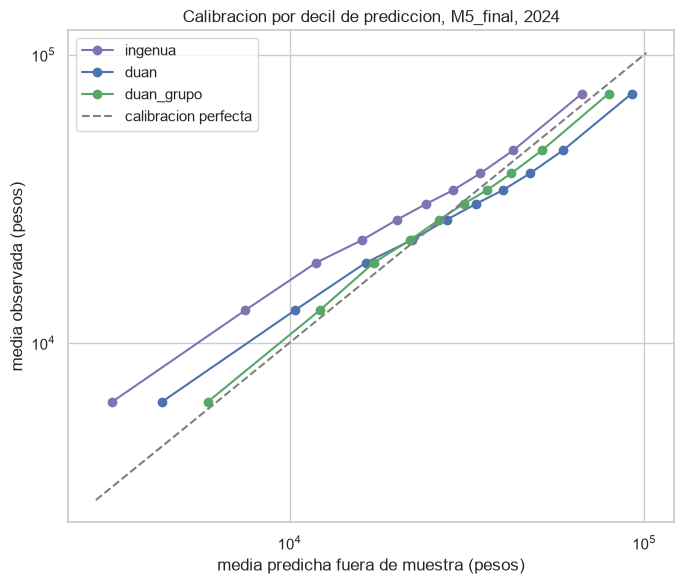

In [26]:
filas = []
for anio in ANIOS:
    yv = datos[anio][LOG_TARGET].to_numpy()
    for nombre in ["M0_base_nb14", "M4_ocupacion_sector", "M5_final"]:
        cv = cv_guardado[(anio, nombre)]
        for variante, factor in [("ingenua exp(xb)-1", 1.0), ("Duan global", cv["duan"]),
                                 ("Duan por subordinacion x localidad", cv["duan_grupo"])]:
            filas.append({"anio": anio, "especificacion": nombre, "retransformacion": variante,
                          "factor_medio": float(np.mean(factor)), **metricas_pesos(yv, cv["pred"], factor)})
retransformacion_duan = pd.DataFrame(filas)
display(retransformacion_duan)

cv = cv_guardado[(ANIO_DIAGNOSTICO, "M5_final")]
y_pesos = np.expm1(datos[ANIO_DIAGNOSTICO][LOG_TARGET].to_numpy())
calibracion = pd.DataFrame({"observado": y_pesos, "decil": pd.qcut(cv["pred"], 10, labels=False),
                            "ingenua": np.expm1(cv["pred"]), "duan": np.exp(cv["pred"]) * cv["duan"] - 1,
                            "duan_grupo": np.exp(cv["pred"]) * cv["duan_grupo"] - 1}).groupby("decil").mean()
fig, ax = plt.subplots(figsize=(7, 6))
for columna, color in [("ingenua", "#8172b3"), ("duan", "#4c72b0"), ("duan_grupo", "#55a868")]:
    ax.plot(calibracion[columna], calibracion.observado, marker="o", color=color, label=columna)
limite = [calibracion.min().min() * 0.9, calibracion.max().max() * 1.1]
ax.plot(limite, limite, color="0.5", linestyle="--", label="calibracion perfecta")
ax.set(xscale="log", yscale="log", xlabel="media predicha fuera de muestra (pesos)", ylabel="media observada (pesos)",
       title=f"Calibracion por decil de prediccion, M5_final, {ANIO_DIAGNOSTICO}")
ax.legend()
fig.tight_layout()
mostrar_figura(fig, "calibracion_duan")

## 14. Síntesis

La tabla reúne, por año, las métricas comparables de cada estrategia. El $R^2$ y el $R^2_{CV}$ están en la escala $\ln(1+y)$; las estrategias que no son OLS (FGLS, Huber) se evalúan con predicciones no ponderadas sobre la misma escala.

r2_ajustado                           r2_cv                        
anio                                        2018    2020    2022    2024    2018    2020    2022    2024
estrategia                                                                                              
OLS M0_base_nb14                          0.4463  0.4290  0.4258  0.4420  0.4460  0.4288  0.4257  0.4419
OLS M1_forma_funcional                    0.4930  0.4714  0.4723  0.4848  0.4927  0.4712  0.4722  0.4847
OLS M2_escolaridad_fina                   0.4956  0.4735  0.4746  0.4872  0.4952  0.4733  0.4745  0.4870
OLS M3_variables_excluidas                0.5121  0.4900  0.4926  0.5044  0.5117  0.4897  0.4925  0.5042
OLS M4_ocupacion_sector                   0.5354  0.5103  0.5156  0.5284  0.5349  0.5099  0.5154  0.5281
OLS M4_mincer                             0.5359  0.5108  0.5163  0.5288  0.5354  0.5105  0.5161  0.5285
OLS M5_final                              0.5454  0.5188  0.5249  0.5369  0.5446  0.5181  0.5245  0.5363
OLS M5_entidad                            0.5496  0.5225  0.5322  0.5437  0.5487  0.5217  0.5316  0.5431
FGLS M5 por estrato                          NaN     NaN     NaN     NaN  0.5412  0.5151  0.5201  0.5316
OLS separado por tamaño de localidad         NaN     NaN     NaN     NaN  0.5470  0.5194  0.5266  0.5395
Huber M4 (R2 no ponderado)                   NaN     NaN     NaN     NaN     NaN     NaN     NaN  0.5218

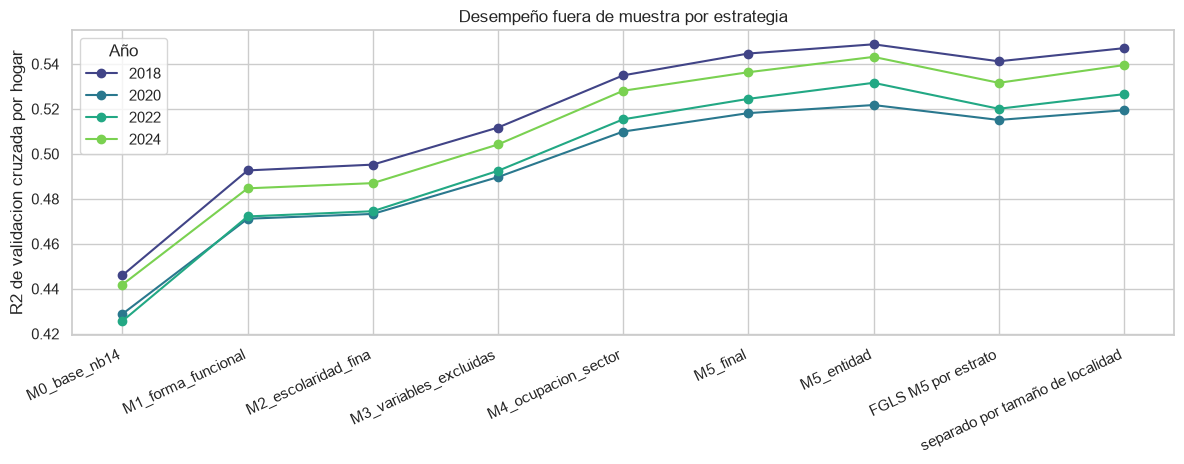

In [27]:
sintesis = pd.concat([
    escalera_completa[["anio", "especificacion", "k", "r2", "r2_ajustado", "aic", "bic", "r2_cv"]]
    .assign(estrategia="OLS " + escalera_completa.especificacion),
    fgls_estratos.rename(columns={"r2_no_ponderado": "r2"})[["anio", "r2", "r2_cv"]].assign(estrategia="FGLS M5 por estrato"),
    modelos_por_localidad.loc[modelos_por_localidad.localidad.eq("TOTAL modelos separados"), ["anio", "r2_cv_estrato"]]
    .rename(columns={"r2_cv_estrato": "r2_cv"}).assign(estrategia="OLS separado por tamaño de localidad"),
], ignore_index=True)
if EJECUTAR_HUBER:
    huber_sintesis = resumen_huber.rename(columns={"r2_huber_en_muestra": "r2", "r2_cv_huber": "r2_cv"})
    huber_sintesis = huber_sintesis[["anio", "r2"] + [c for c in ["r2_cv"] if c in huber_sintesis]]
    sintesis = pd.concat([sintesis, huber_sintesis.assign(estrategia="Huber M4 (R2 no ponderado)")], ignore_index=True)
sintesis = sintesis[["anio", "estrategia", "k", "r2", "r2_ajustado", "aic", "bic", "r2_cv"]]
display(sintesis.pivot_table(index="estrategia", columns="anio", values=["r2_ajustado", "r2_cv"], sort=False).round(4))

principales = ["OLS M0_base_nb14", "OLS M1_forma_funcional", "OLS M2_escolaridad_fina", "OLS M3_variables_excluidas",
               "OLS M4_ocupacion_sector", "OLS M5_final", "OLS M5_entidad", "FGLS M5 por estrato",
               "OLS separado por tamaño de localidad"]
fig, ax = plt.subplots(figsize=(12, 4.8))
tabla = sintesis.loc[sintesis.estrategia.isin(principales)].pivot(index="estrategia", columns="anio", values="r2_cv").loc[principales]
for anio in ANIOS:
    ax.plot(range(len(principales)), tabla[anio], marker="o", color=paleta[anio], label=str(anio))
ax.set_xticks(range(len(principales)), [p.replace("OLS ", "") for p in principales], rotation=25, ha="right")
ax.set_ylabel("R2 de validacion cruzada por hogar")
ax.set_title("Desempeño fuera de muestra por estrategia")
ax.legend(title="Año")
fig.tight_layout()
mostrar_figura(fig, "sintesis_r2_cv")

### Lectura de resultados

Las cifras citadas provienen de las tablas de esta ejecución (validación cruzada con semilla fija). Todas son asociaciones condicionadas en pesos nominales; no son efectos causales.

**1. Cuánto mejora el ajuste y de dónde viene.** El $R^2_{CV}$ pasa de 0.426–0.446 en M0 (la especificación del notebook 14) a 0.518–0.545 en M5 y a 0.522–0.549 con entidad en lugar de región. Las diferencias entre $R^2$ ajustado y $R^2_{CV}$ son menores a 0.001 en todos los modelos, de modo que la mejora **no** es sobreajuste. Por peldaño, en los cuatro años:

* *Forma funcional* (M1): +0.042 a +0.047. Es la mejora más grande, y proviene de la concavidad de la edad y de la no linealidad de las horas.
* *Grados dentro del nivel* (M2): +0.002 a +0.003.
* *Variables antes excluidas* (M3): +0.016 a +0.018.
* *Ocupación y sector* (M4): +0.020 a +0.024.
* *Interacciones seleccionadas* (M5): +0.008 a +0.010.

Mincer (experiencia potencial en lugar de edad) es prácticamente equivalente a M4 (diferencia de $R^2_{CV}$ menor a 0.001).

**2. Prima educativa y malos controles.** Al pasar de M3 a M4, la prima de Licenciatura frente a Secundaria cae de 64.7% a 38.4% (2018) y de 43.4% a 27.4% (2024); la de Posgrado, de 110% a 70% en 2024. Una parte sustancial de la asociación educativa opera a través de la ocupación y el sector a los que se accede. Para la pregunta sustantiva sobre escolaridad, M3 es la referencia; M4 y M5 son las mejores especificaciones predictivas.

**3. Interacciones.** Cumplen la regla en los cuatro años:
* género × ciclo de vida;
* educación × edad;
* región × tamaño de localidad (estrato territorial);
* género × territorio;
* subordinación × seguridad social y horas.

No la cumplen educación × territorio ni ocupación × localidad. Sus Wald son significativos (p < 0.001), pero su $\Delta$BIC es positivo en los cuatro años y su aporte fuera de muestra es marginal. Es un ejemplo de por qué significancia estadística y mejora de especificación son preguntas distintas con $n$ grande.

**4. Territorio.**
* **Varianza:** la varianza residual difiere fuertemente por estrato y, sobre todo, por subordinación (Breusch–Pagan con p ≈ 0).
* **FGLS:** reduce entre 15% y 20% los errores estándar de la mayoría de los coeficientes clave, aunque no los de subordinación, contrato y seguridad social. No mejora el $R^2_{CV}$; incluso lo baja entre 0.003 y 0.005, como predice la teoría. Estabilizar la varianza mejora la precisión, no el ajuste.
* **Modelos separados por tamaño de localidad:** apenas superan a M5 (+0.001 a +0.003 de $R^2_{CV}$). El Wald entre estratos rechaza la igualdad de coeficientes:
  * en seguridad social, en los cuatro años;
  * en escolaridad y horas, en tres de cuatro años (no en 2020);
  * en la brecha de género, solo en 2020;
  * en el perfil de edad, en ningún año.
* **Efectos estatales:** son precisos. La contracción bayesiana empírica es de solo 1%–3%, de modo que las diferencias estatales no se deben a ruido muestral.

**5. Subordinados e independientes.** Estimar ecuaciones separadas mejora el $R^2_{CV}$ en ambos grupos y años:
* Subordinados: de 0.537–0.551 a 0.553–0.568.
* Independientes: de 0.472–0.526 a 0.492–0.548.

La desviación estándar residual de los independientes (1.17–1.27) casi duplica la de los subordinados (0.60–0.70), y se rechaza la igualdad de los coeficientes de horas y seguridad social. Separar los grupos es la mejora más clara después de las de M1–M4.

**6. Huber y cuantílica.**
* **Huber:** atenúa al 24% de las observaciones. Los coeficientes son cercanos a OLS, salvo la brecha de género, que es menor en Huber (−20.6% frente a −25.1% en 2024). Huber no mejora el $R^2_{CV}$ (0.522 frente a 0.528), aunque reduce ligeramente el error absoluto.
* **Regresión cuantílica (2024):** muestra heterogeneidad distributiva:

| Asociación | Cuantil 0.1 | Cuantil 0.5 | Cuantil 0.9 |
| --- | --- | --- | --- |
| Licenciatura | +20% | +25% | +37% |
| Posgrado | +53% | +68% | +90% |
| Seguridad social | +28% | +16% | +11% |
| Brecha de género | −24% | −18% | −19% |

  La escolaridad superior se asocia con mayor dispersión del ingreso dentro de su grupo. La seguridad social pesa más en la cola baja, y la brecha de género es mayor en la cola baja.

**7. Supuestos y escala.**
* **RESET:** su estadístico cae de 2,800–4,000 (M0) a 960–1,320 (M5). La forma funcional mejoró, aunque sigue habiendo estructura no capturada, lo cual es esperable con $n \approx 140{,}000$.
* **Box–Cox condicional:** da $\hat\lambda \approx 0.22$–0.25, lejos del nivel ($\lambda = 1$). El logaritmo no es exactamente óptimo, pero recupera la mayor parte de la ganancia de transformar. Entre las escalas interpretables es la que deja residuos menos asimétricos (−0.8 a −0.9), y es la única con lectura porcentual. Esto respalda la transformación logarítmica (sección 9). Una potencia $\lambda \approx 0.25$ queda como sensibilidad.

**8. Retransformación a pesos.** La predicción ingenua $e^{x'\hat\beta} - 1$ subestima la media observada (razón 0.75–0.82). Duan global la sobreestima (1.14–1.20), porque mezcla la alta varianza de los independientes con la de los subordinados. Duan por subordinación × localidad queda mejor calibrado (1.04–1.06) y tiene el mayor $R^2$ en pesos. Es coherente con la heterocedasticidad documentada.

**9. Registro excluido.** En escala log su influencia es despreciable: distancia de Cook de 0.0003 (lugar 329) y $R^2$ que pasa de 0.44207 a 0.44213. En nivel nominal es la observación más influyente: el $R^2$ del modelo en pesos pasa de 0.070 a 0.136 sin ella. La exclusión casi no afecta al modelo principal en log y cambia sustancialmente cualquier lectura en niveles.

**Recomendación para las siguientes etapas.**
1. Usar M3 para interpretar primas educativas y M5 (o M5 con entidad) como especificación de mejor ajuste.
2. Reportar subordinados e independientes por separado.
3. Retransformar a pesos con Duan por grupo.
4. Usar la regresión cuantílica para la lectura distributiva.
5. Evaluar Box–Cox ($\lambda \approx 0.25$) como sensibilidad de escala.

Llevar estas especificaciones al análisis temporal del notebook 14 requiere repetir allí las interacciones con año.

**Candidatas de transformación** sugeridas por la exploración y no adoptadas aquí:
* potencia Box–Cox del target;
* *spline* de edad en lugar del cuadrático;
* tratamiento separado de ingresos trimestrales muy bajos (por ejemplo, un modelo de dos partes), que hoy dominan la asimetría residual.

## 15. Exportación

Todas las tablas y figuras provienen de objetos creados en esta ejecución. La exportación sobrescribe `outputs/especificacion_validacion_fuera_muestra/`; las figuras se copian además a `reports/figures/especificacion_validacion_fuera_muestra/` para el reporte narrativo. Se exporta también, por año, la **base de modelado** (personas analizadas tras la regla de plausibilidad, con las variables homologadas) en `data/processed/especificacion_validacion/`, que es el insumo del notebook 16; no contiene resultados de modelos. El manifest registra configuración, especificaciones, bloques seleccionados, reglas, versiones de software y el estado `ejecutado_pendiente_revision_humana`.

In [28]:
tablas_salida = {
    "auditoria_lectura": auditoria_lectura, "validaciones_homologacion": validaciones_homologacion,
    "categorias_por_anio": categorias_por_anio, "frecuencias_homologadas": frecuencias_homologadas,
    "plausibilidad": plausibilidad, "perfil_excluidos": perfil_excluidos, "influencia_exclusion": influencia_exclusion,
    "box_cox": box_cox, "box_cox_condicional": box_cox_condicional, "perfil_box_cox": perfil_box_cox,
    "escalera_especificaciones": escalera_completa, "columnas_eliminadas": columnas_eliminadas,
    "prima_educativa_m3_m4": prima_educativa, "evaluacion_bloques": evaluacion_bloques,
    "decision_bloques": decision_bloques.reset_index(), "wald_bloques_m5": pd.DataFrame(wald_m5),
    "efectos_territoriales_bloques": efectos_territoriales_bloques,
    "heterocedasticidad_estratos": heterocedasticidad_estratos, "sd_residual_estratos": sd_residual_estratos,
    "fgls_estratos": fgls_estratos, "comparacion_ols_fgls": comparacion_ols_fgls,
    "modelos_por_localidad": modelos_por_localidad, "coeficientes_por_localidad": coeficientes_por_localidad,
    "heterogeneidad_localidad": heterogeneidad_localidad, "efectos_estatales_eb": efectos_estatales_eb,
    "resumen_eb": resumen_eb, "diagnostico_supuestos": diagnostico_supuestos, "gvif_m4": gvif_m4,
    "modelos_subordinacion": modelos_subordinacion, "coeficientes_subordinacion": coeficientes_subordinacion,
    "heterogeneidad_subordinacion": heterogeneidad_subordinacion, "retransformacion_duan": retransformacion_duan,
    "sintesis": sintesis,
}
if EJECUTAR_HUBER:
    tablas_salida.update({"resumen_huber": resumen_huber, "coeficientes_huber": coeficientes_huber})
if EJECUTAR_CUANTILICA:
    tablas_salida.update({"ajuste_cuantilico": ajuste_cuantilico, "coeficientes_cuantilicos": coeficientes_cuantilicos})

manifest = {
    "estado": "ejecutado_pendiente_revision_humana",
    "fecha_ejecucion": INICIO_EJECUCION.isoformat(timespec="seconds"),
    "duracion_minutos": round((datetime.now() - INICIO_EJECUCION).total_seconds() / 60, 1),
    "unidad_analisis": "persona",
    "universo": "edad>=18 e ingreso laboral/de negocio individual nominal trimestral>0, menos exclusiones de plausibilidad",
    "target": LOG_TARGET, "target_monetario": "nominal trimestral; sin deflactar",
    "anios": ANIOS, "anio_diagnostico": ANIO_DIAGNOSTICO,
    "archivos_entrada": {str(a): str(r.relative_to(PROJECT_ROOT)) for a, r in INPUTS.items()},
    "fraccion_hogares_prueba": FRACCION_HOGARES_PRUEBA,
    "regla_plausibilidad": {"definicion": "z = (ln y - mediana) / (1.4826 MAD) dentro de cada año; excluir z > umbral",
                            "umbral": UMBRAL_Z_PLAUSIBILIDAD, "unilateral": True,
                            "excluidos_por_anio": {int(a): int(n) for a, n in zip(plausibilidad.anio, plausibilidad.excluidos)},
                            "nota": "umbral fijado tras inspeccionar el maximo de 2024; no es prueba estadistica"},
    "horas_maximas_semanales": HORAS_MAXIMAS_SEMANALES, "nudos_horas": NUDOS_HORAS,
    "edad_centro": EDAD_CENTRO, "experiencia_centro": EXPERIENCIA_CENTRO,
    "validacion_cruzada": {"k": K_FOLDS, "agrupacion": "hogar (folioviv+foliohog)", "semilla": SEMILLA,
                           "r2_cv": "1 - SSE_oof / sum (y - media_entrenamiento)^2"},
    "especificaciones": ESPECIFICACIONES, "bloques_interaccion": BLOQUES_INTERACCION,
    "regla_seleccion_bloques": "incluir si delta BIC < 0 y delta R2 CV > 0 frente a M4 en los cuatro años",
    "bloques_seleccionados": BLOQUES_SELECCIONADOS, "referencias": REFERENCIAS,
    "categorias": CATEGORIAS, "compuestos": COMPUESTOS,
    "bases_modelo": {str(a): str((BASE_MODELO_DIR / f"base_modelo_{a}.csv.gz").relative_to(PROJECT_ROOT)) for a in ANIOS},
    "covarianza": "agrupada por hogar (cluster) en OLS/FGLS; sandwich H1 en Huber; kernel Hall-Sheather en cuantilica",
    "huber_t": HUBER_T, "cuantiles_proceso": CUANTILES_PROCESO, "cuantiles_anuales": CUANTILES_ANUALES,
    "duan": "factor global y por subordinacion x tamaño de localidad, estimados en entrenamiento de cada pliegue",
    "limitaciones": [
        "asociaciones condicionadas, no efectos causales",
        "ocupacion y sector son posibles malos controles para la prima educativa (ver M3 vs M4)",
        "años de escolaridad y grado de conclusion aproximados sin antecedente escolar para Normal y Tecnica",
        "SINCO y SCIAN cambian de version en 2020; solo se usan agregados estables",
        "errores agrupados por hogar no reproducen el diseño muestral ENIGH; sin ponderadores",
        "Huber y cuantilica sin errores agrupados por hogar",
        "montos nominales; no comparar niveles entre años",
    ],
    "versiones": {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
                  "statsmodels": statsmodels.__version__, "scipy": scipy.__version__,
                  "scikit_learn": sklearn.__version__, "seaborn": sns.__version__},
}
if EXPORTAR_RESULTADOS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / "figures").mkdir(exist_ok=True)
    for nombre, tabla in tablas_salida.items():
        tabla.to_csv(OUTPUT_DIR / f"{nombre}.csv", index=False)
    for nombre, figura in FIGURAS.items():
        figura.savefig(OUTPUT_DIR / "figures" / f"{nombre}.png", dpi=150, bbox_inches="tight")
    FIGURAS_REPORTE_DIR.mkdir(parents=True, exist_ok=True)
    for nombre, figura in FIGURAS.items():
        figura.savefig(FIGURAS_REPORTE_DIR / f"{nombre}.png", dpi=110, bbox_inches="tight")
    columnas_base_modelo = list(dict.fromkeys(
        KEY_COLS + ["id_hogar", TARGET, LOG_TARGET, "z_robusto_log", "factor", "est_dis", "upm", "cve_ent",
                    "edad", "n_trabajos", "horas_trabajos_total", "horas_acotadas", "anios_esc", "exp_pot",
                    "grado_relativo", "dos_o_mas_trabajos"]
        + list(CATEGORIAS) + [c for columnas in COMPUESTOS.values() for c in columnas]))
    BASE_MODELO_DIR.mkdir(parents=True, exist_ok=True)
    for anio in ANIOS:
        if datos[anio].duplicated(KEY_COLS).any():
            raise ValueError(f"{anio}: llave duplicada en la base de modelado.")
        datos[anio][columnas_base_modelo].to_csv(BASE_MODELO_DIR / f"base_modelo_{anio}.csv.gz", index=False,
                                                 compression="gzip")
    (OUTPUT_DIR / "manifest_especificacion_validacion.json").write_text(
        json.dumps(manifest, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
display(pd.DataFrame([{"exportacion": "realizada" if EXPORTAR_RESULTADOS else "desactivada", "ruta": str(OUTPUT_DIR),
                       "tablas": len(tablas_salida), "figuras": len(FIGURAS),
                       "duracion_minutos": manifest["duracion_minutos"]}]))

,exportacion,ruta,tablas,figuras,duracion_minutos
0,realizada,G:\Escritorio\Tesina\inegi-modeling-income\ine...,37,19,29.0
